Step 1 — loaded application_train: (307511, 122)
Step 2 — after ratio features: (307511, 138)
Step 3 — after peer-group features: (307511, 201)
Step 4 — dropped 48 columns. Shape: (307511, 153)
Step 5 — added 29 missing flags. Shape: (307511, 182)
Step 6 — previous_application summary: (338857, 86)
Step 7 — bureau summary: (305811, 109)
Step 8 — installments summary: (339587, 22)
Step 9 — credit card summary: (103558, 23)
Step 10 — POS_CASH summary: (337252, 16)
  previous_application: (338857, 86), duplicate customers = 0
  bureau: (305811, 109), duplicate customers = 0
  installments: (339587, 22), duplicate customers = 0
  credit_card: (103558, 23), duplicate customers = 0
  pos_cash: (337252, 16), duplicate customers = 0
Step 11 — merged everything: (307511, 433) (rows unchanged: 307511)
Step 11 — filled 54 count/sum columns with 0
FINAL table: (307511, 438)  (features = 436)
Step 12 — train (246008, 436), test (61503, 436)
Step 13 — 423 numeric and 13 categorical columns
Step 14 —

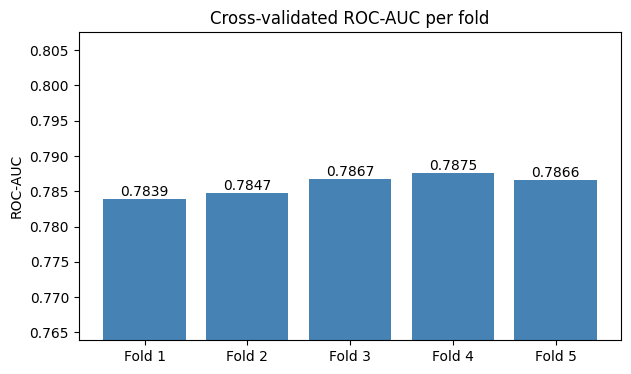


Step 16 — training 5 models with 844 trees each
  finished seed 42
  finished seed 10
  finished seed 2018
  finished seed 38
  finished seed 28

FINAL TEST ROC-AUC: 0.7911
FINAL TEST PR-AUC : 0.2925

Step 17 — best threshold on cross-validation predictions: 0.5


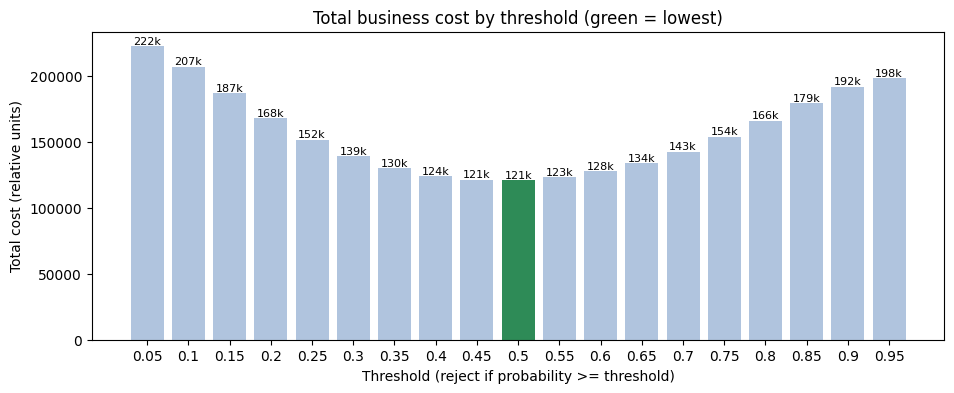

TEST at threshold 0.5: missed defaulters=1604, rejected good customers=13280
  model cost           = 29320
  approve-everyone cost= 49650
  reject-everyone cost = 56538

Step 18 — top 20 features:
EXT_SOURCES_MEAN                                           0.051912
EXT_SOURCES_MIN                                            0.017813
EXT_SOURCES_MAX                                            0.016952
CODE_GENDER_NAME_EDUCATION_TYPE_MEAN_EXT_SOURCE_2          0.011326
INST_DAYS_LATE_MEAN_1Y                                     0.008277
CODE_GENDER_REG_CITY_NOT_WORK_CITY_MEAN_DAYS_ID_PUBLISH    0.007165
OVER_FINANCING_RATIO                                       0.006983
OCCUPATION_TYPE_MEAN_EXT_SOURCE_1                          0.006650
NAME_EDUCATION_TYPE_OCCUPATION_TYPE_MEAN_EXT_SOURCE_2      0.006470
INST_LATE_RATE                                             0.006450
CODE_GENDER_NAME_EDUCATION_TYPE_MEAN_EXT_SOURCE_1          0.006401
PREV_REFUSED_RATIO                                    

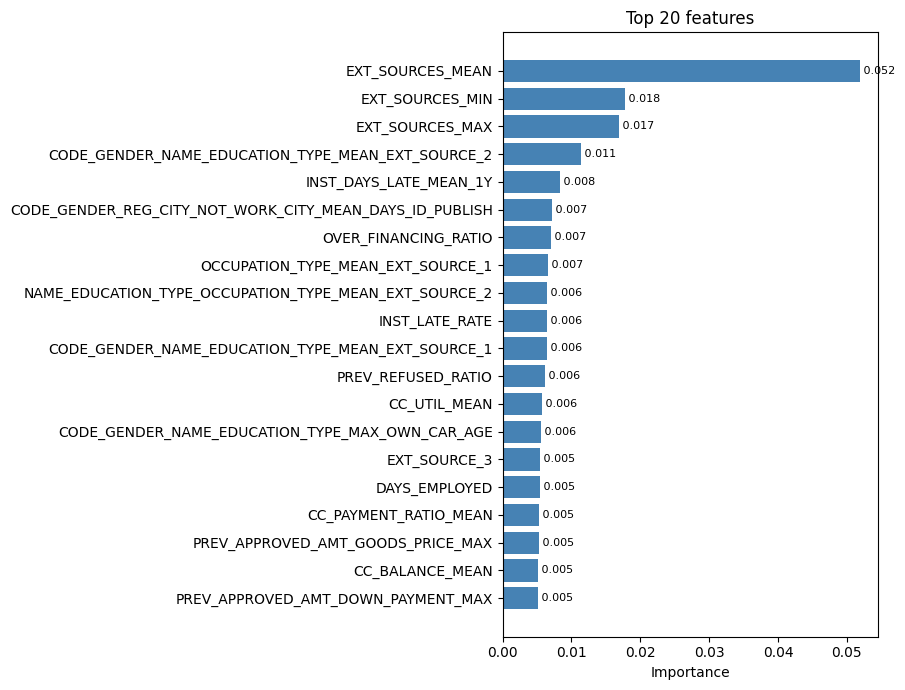

In [ ]:
"""
Home Credit Default Risk — Easy-to-Read Version
==================================================

GOAL
  Predict which customers will fail to repay a loan (TARGET = 1).

THE BIG IDEA (read this first)
  application_train.csv has ONE row per customer.
  The six other files have MANY rows per customer (one row per past loan,
  per month, or per payment). You cannot attach many rows to one row, so:
      (a) SUMMARIZE each other file down to one row per customer
      (b) MERGE that summary onto application_train (it adds new columns)
  Only after every file has been merged do we split the data and train.

WORDS USED IN THIS FILE
  customer ID   SK_ID_CURR. The column that links every file together.
  summarize     Turn many rows into one row, e.g. "average", "maximum",
                "count". Also called "aggregate" or "groupby".
  merge         Add columns to a table by matching on the customer ID.
  NaN           A missing value.
  imputer       A tool that fills in missing values.
  flag          A 0/1 column that says "yes/no", e.g. HAS_CHILDREN.
  rate          The average of a 0/1 flag. 0.30 means "30% of the time".
  fold          One round of cross-validation (train on part, test on the rest).
  leakage       Accidentally letting the model peek at answers it should not
                see, which makes the score look better than it really is.

THE ORDER
   1. Load application_train, fix the 365243 placeholder
   2. Add ratio features (credit/income, EXT_SOURCE averages, ...)
   3. Add "peer group" features (how does this customer compare to similar people?)
   4. Drop columns that are mostly empty or constant
   5. Add "was this value missing?" flags
   6. previous_application   -> 1 row per customer
   7. bureau + bureau_balance -> 1 row per customer
   8. installments_payments  -> 1 row per customer
   9. credit_card_balance    -> 1 row per customer
  10. POS_CASH_balance       -> 1 row per customer
  11. Merge everything, check nothing was duplicated, fill the gaps
  12. Train/test split (the test set is locked away from now on)
  13. Preprocessing recipe (learned only from training rows)
  14. Model settings, including scale_pos_weight
  15. 5-fold cross-validation on the TRAIN part only
  16. Final model: 5 seeds averaged, scored once on the test set
  17. Choose the business threshold from the cross-validation predictions
  18. Which features did the model use most?

REQUIREMENTS: scikit-learn >= 1.3 (for TargetEncoder), xgboost >= 1.6
"""

import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import TargetEncoder
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)


# =====================================================================
# SETTINGS — the only things you normally need to change
# =====================================================================
DATA_DIR = '/content'            # folder that holds the CSV files
N_FOLDS = 5                      # how many cross-validation rounds
MAX_TREES = 800                  # upper limit; early stopping picks the real number
SEEDS = [42, 10, 2018, 38, 28]   # final model is trained once per seed, then averaged
MISSING_CUTOFF_PERCENT = 50      # drop columns with more than this % missing


# =====================================================================
# ONE HELPER FUNCTION (used for previous_application and bureau)
# =====================================================================
def summarize_table(df, agg_dict, prefix):
    """
    Turn many rows per customer into ONE row per customer.

    You give it:
      df        the table to summarize
      agg_dict  which columns to summarize and how, e.g.
                {'AMT_CREDIT': ['mean', 'max']}
      prefix    text put in front of the new column names, e.g. 'PREV_'

    You get back one row per customer with columns such as
      PREV_AMT_CREDIT_MEAN   and   PREV_AMT_CREDIT_MAX
    """
    # Group the rows by customer and calculate the requested statistics
    result = df.groupby('SK_ID_CURR').agg(agg_dict)

    # After .agg(), each column name is a PAIR like ('AMT_CREDIT', 'mean').
    # We join each pair into one plain name: prefix + column + statistic.
    new_names = []
    for column_pair in result.columns:
        source_column = column_pair[0]
        statistic = column_pair[1].upper()
        new_names.append(prefix + source_column + '_' + statistic)
    result.columns = new_names

    # Make SK_ID_CURR a normal column again so we can merge on it later
    return result.reset_index()


# =====================================================================
# STEP 1: Load application_train and fix the placeholder number
# =====================================================================
# WHAT: read the main table (one row per customer, with the TARGET answer).
application = pd.read_csv(f'{DATA_DIR}/application_train.csv', low_memory=False)
print(f'Step 1 — loaded application_train: {application.shape}')

# WHY: 365243 days is about 1000 years of employment, which is impossible.
# It is a placeholder the database uses for "not applicable" (often
# pensioners). If we left it, the model would treat it as a real number.
# So we (1) keep a 0/1 flag saying "this was the placeholder", and
# (2) replace the fake number with NaN (missing).
application['DAYS_EMPLOYED_ANOM'] = (application['DAYS_EMPLOYED'] == 365243).astype(int)
application['DAYS_EMPLOYED'] = application['DAYS_EMPLOYED'].replace(365243, np.nan)


# =====================================================================
# STEP 2: Ratio features built from the application itself
# =====================================================================
# WHY ratios: "credit of 500,000" means different things for a person
# earning 50,000 and a person earning 500,000. A ratio captures that.
# Each new column uses only that customer's own row, so nothing can leak.

# --- 2a. Money ratios ---
# How big is the loan compared with income? How big are the repayments?
application['CREDIT_INCOME_PERCENT'] = application['AMT_CREDIT'] / application['AMT_INCOME_TOTAL']
application['ANNUITY_INCOME_PERCENT'] = application['AMT_ANNUITY'] / application['AMT_INCOME_TOTAL']
application['CREDIT_TERM'] = application['AMT_ANNUITY'] / application['AMT_CREDIT']            # repayment per unit of loan
application['DAYS_EMPLOYED_PERCENT'] = application['DAYS_EMPLOYED'] / application['DAYS_BIRTH']  # share of life spent employed

# --- 2b. Household and over-financing ---
# .replace(0, np.nan) avoids dividing by zero.
application['INCOME_PER_PERSON'] = application['AMT_INCOME_TOTAL'] / application['CNT_FAM_MEMBERS'].replace(0, np.nan)
application['INCOME_LESS_ANNUITY'] = application['AMT_INCOME_TOTAL'] - application['AMT_ANNUITY']  # income left after repayments
application['OVER_FINANCING_RATIO'] = application['AMT_CREDIT'] / application['AMT_GOODS_PRICE'].replace(0, np.nan)  # borrowing more than the goods cost?

# --- 2c. Combine the three external scores ---
# EXT_SOURCE_1/2/3 are the strongest raw predictors in this dataset.
# Summaries across the three give the model extra useful columns.
external_score_columns = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
application['EXT_SOURCES_MEAN'] = application[external_score_columns].mean(axis=1)  # average score
application['EXT_SOURCES_STD'] = application[external_score_columns].std(axis=1)    # do the scores disagree?
application['EXT_SOURCES_MIN'] = application[external_score_columns].min(axis=1)    # worst score
application['EXT_SOURCES_MAX'] = application[external_score_columns].max(axis=1)    # best score
application['EXT_SOURCES_PROD'] = (
    application['EXT_SOURCE_1'] * application['EXT_SOURCE_2'] * application['EXT_SOURCE_3']
)  # multiplied together: low only if all three are low

# --- 2d. Simple yes/no flags ---
application['HAS_CHILDREN'] = (application['CNT_CHILDREN'] > 0).astype(int)
application['HAS_JOB'] = application['DAYS_EMPLOYED'].notna().astype(int)
application['LONG_EMPLOYMENT'] = (application['DAYS_EMPLOYED'] < -2000).astype(int)  # employed for more than ~5.5 years

print(f'Step 2 — after ratio features: {application.shape}')


# =====================================================================
# STEP 3: Peer-group features
# =====================================================================
# WHAT: compare each customer with SIMILAR customers.
# WHY: an annuity of 30,000 is normal for one kind of customer and huge
# for another. Knowing how a person differs from their peers is a signal.
#
# EXAMPLE with the first recipe below:
#   group = same gender AND same education.
#   For every customer we look up the LARGEST AMT_ANNUITY among customers
#   in their group, and create three columns:
#     <name>           that group value (the largest annuity in the group)
#     <name>_DIFF      this customer's own annuity MINUS the group value
#     <name>_ABS_DIFF  the same difference, ignoring the sign (+/-)
#
# TARGET is never used here, only ordinary feature values.
peer_group_recipes = [
    # (columns that define "similar customers",  [(column to summarize, statistic), ...])
    (['CODE_GENDER', 'NAME_EDUCATION_TYPE'],
     [('AMT_ANNUITY', 'max'), ('AMT_CREDIT', 'max'),
      ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'), ('OWN_CAR_AGE', 'max')]),
    (['CODE_GENDER', 'ORGANIZATION_TYPE'],
     [('AMT_ANNUITY', 'mean'), ('AMT_INCOME_TOTAL', 'mean'), ('DAYS_REGISTRATION', 'mean')]),
    (['CODE_GENDER', 'REG_CITY_NOT_WORK_CITY'],
     [('AMT_ANNUITY', 'mean'), ('DAYS_ID_PUBLISH', 'mean')]),
    (['NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE'],
     [('AMT_CREDIT', 'mean'), ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'),
      ('EXT_SOURCE_3', 'mean'), ('AMT_REQ_CREDIT_BUREAU_YEAR', 'mean')]),
    (['OCCUPATION_TYPE'],
     [('AMT_ANNUITY', 'mean'), ('DAYS_BIRTH', 'mean'), ('DAYS_EMPLOYED', 'mean'),
      ('EXT_SOURCE_1', 'mean'), ('EXT_SOURCE_2', 'mean'), ('EXT_SOURCE_3', 'mean')]),
]

# For every recipe, and every (column, statistic) inside it, make 3 columns
for group_columns, things_to_summarize in peer_group_recipes:
    for source_column, statistic in things_to_summarize:
        new_name = '_'.join(group_columns) + '_' + statistic.upper() + '_' + source_column

        # transform() gives every customer the value of their own group,
        # so the table keeps exactly one row per customer (no merge needed).
        group_value = application.groupby(group_columns, dropna=False)[source_column].transform(statistic)

        application[new_name] = group_value
        application[new_name + '_DIFF'] = application[source_column] - group_value
        application[new_name + '_ABS_DIFF'] = (application[source_column] - group_value).abs()

print(f'Step 3 — after peer-group features: {application.shape}')


# =====================================================================
# STEP 4: Drop columns that are mostly empty or constant
# =====================================================================
# WHY drop mostly-empty columns: over 50% empty means more than half the
#   values would be guesses after filling.
# WHY drop constant columns: if every customer has the same value, the
#   column cannot help tell good customers from bad ones.
# EXCEPTION: columns we know are valuable are kept even if sparse.
columns_to_always_keep = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_EMPLOYED_ANOM',
    'EXT_SOURCES_MEAN', 'EXT_SOURCES_STD', 'EXT_SOURCES_PROD',
]

# What percent of each column is missing?
missing_percent = application.isnull().mean() * 100

# Go through every column and decide whether to drop it
columns_to_drop = []
for column in application.columns:
    if column == 'TARGET' or column == 'SK_ID_CURR':
        continue   # never touch the answer or the ID
    too_empty = missing_percent[column] > MISSING_CUTOFF_PERCENT
    is_constant = application[column].nunique(dropna=False) <= 1   # nunique = number of different values
    if (too_empty and column not in columns_to_always_keep) or is_constant:
        columns_to_drop.append(column)

application = application.drop(columns=columns_to_drop)
print(f'Step 4 — dropped {len(columns_to_drop)} columns. Shape: {application.shape}')


# =====================================================================
# STEP 5: "Was this value missing?" flags
# =====================================================================
# WHY: sometimes being missing is itself informative (for example, no
# external score on file). Later the imputer will fill the gap, and
# without a flag the model could not tell a real value from a filled one.
# We add a flag for every column that is at least 5% missing.
missing_percent = application.isnull().mean() * 100   # recalculate after dropping

columns_needing_flag = []
for column in application.columns:
    if column == 'TARGET' or column == 'SK_ID_CURR':
        continue
    if missing_percent[column] >= 5:
        columns_needing_flag.append(column)

for column in columns_needing_flag:
    application[column + '_MISSING'] = application[column].isna().astype(int)

print(f'Step 5 — added {len(columns_needing_flag)} missing flags. Shape: {application.shape}')


# =====================================================================
# STEP 6: previous_application.csv -> 1 row per customer
# =====================================================================
# WHAT IT IS: this customer's PAST applications at Home Credit itself.
# WHY IT HELPS: how often they applied, how big, how recent, and above
#   all how often they were approved versus refused.
# We only load the columns we need (usecols) to save memory.
previous_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'AMT_ANNUITY',
    'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE',
    'DAYS_DECISION', 'CNT_PAYMENT', 'RATE_DOWN_PAYMENT',
]
previous = pd.read_csv(f'{DATA_DIR}/previous_application.csv', usecols=previous_columns_to_load)

# --- 6a. A row-by-row column made BEFORE summarizing ---
# "Did they receive what they asked for?" = amount asked / amount given.
# .clip(0, 10) limits it to 0-10 so a tiny denominator cannot create a
# billion-sized ratio.
previous['APP_CREDIT_RATIO'] = (
    previous['AMT_APPLICATION'] / previous['AMT_CREDIT'].replace(0, np.nan)
).clip(0, 10)

# --- 6b. Which statistics to compute for each column ---
# The comment after each line says why that column is useful.
previous_aggregations = {
    'SK_ID_PREV': ['count'],                            # how many applications
    'AMT_ANNUITY': ['min', 'max', 'mean'],              # size of repayments
    'AMT_APPLICATION': ['min', 'max', 'mean'],          # what they asked for
    'AMT_CREDIT': ['min', 'max', 'mean'],               # what they received
    'AMT_DOWN_PAYMENT': ['min', 'max', 'mean'],         # how much they put down
    'AMT_GOODS_PRICE': ['min', 'max', 'mean'],          # price of what they bought
    'DAYS_DECISION': ['min', 'max', 'mean'],            # how recent the decisions were
    'CNT_PAYMENT': ['mean', 'sum'],                     # loan lengths
    'RATE_DOWN_PAYMENT': ['mean'],                      # down payment as a share
    'APP_CREDIT_RATIO': ['min', 'max', 'mean', 'var'],  # asked vs received
}

# --- 6c. Run the SAME summary three times ---
#   1. all applications        -> columns start with PREV_
#   2. only Approved ones      -> columns start with PREV_APPROVED_
#   3. only Refused ones       -> columns start with PREV_REFUSED_
prev_all = summarize_table(previous, previous_aggregations, 'PREV_')
prev_approved = summarize_table(
    previous[previous['NAME_CONTRACT_STATUS'] == 'Approved'], previous_aggregations, 'PREV_APPROVED_')
prev_refused = summarize_table(
    previous[previous['NAME_CONTRACT_STATUS'] == 'Refused'], previous_aggregations, 'PREV_REFUSED_')

# Put the three summaries side by side. how='left' keeps every customer
# from prev_all, even ones who were never approved or never refused.
prev_final = prev_all.merge(prev_approved, on='SK_ID_CURR', how='left')
prev_final = prev_final.merge(prev_refused, on='SK_ID_CURR', how='left')

# Give the three count columns friendly names
prev_final = prev_final.rename(columns={
    'PREV_SK_ID_PREV_COUNT': 'PREV_TOTAL_COUNT',
    'PREV_APPROVED_SK_ID_PREV_COUNT': 'PREV_APPROVED_COUNT',
    'PREV_REFUSED_SK_ID_PREV_COUNT': 'PREV_REFUSED_COUNT',
})
# A customer who was never approved (or refused) really has a count of 0
prev_final['PREV_APPROVED_COUNT'] = prev_final['PREV_APPROVED_COUNT'].fillna(0)
prev_final['PREV_REFUSED_COUNT'] = prev_final['PREV_REFUSED_COUNT'].fillna(0)

# --- 6d. Approval and refusal RATES ---
# Refused 3 times out of 3 is very different from 3 times out of 30.
prev_final['PREV_APPROVED_RATIO'] = prev_final['PREV_APPROVED_COUNT'] / prev_final['PREV_TOTAL_COUNT'].replace(0, np.nan)
prev_final['PREV_REFUSED_RATIO'] = prev_final['PREV_REFUSED_COUNT'] / prev_final['PREV_TOTAL_COUNT'].replace(0, np.nan)

# --- 6e. Approved-versus-refused comparisons ---
# For a few key columns: (value when approved) / (value when refused).
columns_to_compare = ['AMT_CREDIT_MEAN', 'AMT_ANNUITY_MEAN', 'AMT_APPLICATION_MEAN', 'CNT_PAYMENT_MEAN']
for column in columns_to_compare:
    approved_value = prev_final['PREV_APPROVED_' + column]
    refused_value = prev_final['PREV_REFUSED_' + column]
    prev_final['PREV_RATIO_APPROVED_REFUSED_' + column] = approved_value / refused_value.replace(0, np.nan)

# --- 6f. Recent behavior ---
# DAYS_DECISION is negative: -365 means "365 days ago". So "> -365"
# means "decided within the last year".
recent_previous = previous[previous['DAYS_DECISION'] > -365]
prev_recent = recent_previous.groupby('SK_ID_CURR').size().reset_index(name='PREV_LAST_1Y_COUNT')
prev_final = prev_final.merge(prev_recent, on='SK_ID_CURR', how='left')

print(f'Step 6 — previous_application summary: {prev_final.shape}')

# Free memory: we no longer need these big temporary tables
del previous, prev_all, prev_approved, prev_refused, recent_previous, prev_recent
gc.collect()


# =====================================================================
# STEP 7: bureau.csv + bureau_balance.csv -> 1 row per customer
# =====================================================================
# WHAT THEY ARE:
#   bureau.csv          this customer's loans at OTHER banks (one row per loan)
#   bureau_balance.csv  the month-by-month payment status of those loans
# WHY TWO STAGES: bureau_balance is keyed by LOAN (SK_ID_BUREAU), not by
#   customer. So we go in three small hops:
#     monthly rows -> one row per loan -> attach to bureau -> one row per customer

# --- 7a. bureau_balance -> one row per LOAN ---
balance = pd.read_csv(
    f'{DATA_DIR}/bureau_balance.csv',
    usecols=['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS'],
    dtype={'STATUS': str},
)

# STATUS letters/numbers: C = closed, X = unknown, 0-5 = how overdue (5 is worst)
balance['IS_DPD'] = balance['STATUS'].isin(['1', '2', '3', '4', '5']).astype(int)   # 1 = this month was overdue
status_to_number = {'C': 0, 'X': 0, '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5}
balance['STATUS_NUMBER'] = balance['STATUS'].map(status_to_number)                  # status as a number

balance_per_loan = balance.groupby('SK_ID_BUREAU').agg(
    BB_MONTHS_MIN=('MONTHS_BALANCE', 'min'),     # oldest month on file
    BB_MONTHS_MAX=('MONTHS_BALANCE', 'max'),     # newest month on file
    BB_MONTHS_SIZE=('MONTHS_BALANCE', 'size'),   # months of history on file
    BB_DPD_COUNT=('IS_DPD', 'sum'),              # months spent overdue
    BB_STATUS_VAR=('STATUS_NUMBER', 'var'),      # how unstable the payment status was
).reset_index()

# Recent behavior: overdue months in the last 12 months
recent_balance = balance[balance['MONTHS_BALANCE'] > -12]
balance_recent = recent_balance.groupby('SK_ID_BUREAU').agg(
    BB_RECENT_DPD_SUM=('IS_DPD', 'sum'),
).reset_index()

del balance, recent_balance   # the monthly table is huge, so free it now
gc.collect()

# --- 7b. bureau (one row per loan) + the per-loan summaries ---
bureau_columns_to_load = [
    'SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE',
    'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_OVERDUE',
    'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_ANNUITY',
]
bureau = pd.read_csv(f'{DATA_DIR}/bureau.csv', usecols=bureau_columns_to_load)

# Debt and credit cannot be negative. A few rows are, and they would pull
# a customer's total below zero. We fix each row BEFORE summing.
bureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
bureau['AMT_CREDIT_SUM'] = bureau['AMT_CREDIT_SUM'].clip(lower=0)

bureau = bureau.merge(balance_per_loan, on='SK_ID_BUREAU', how='left')
bureau = bureau.merge(balance_recent, on='SK_ID_BUREAU', how='left')

# A loan with no monthly history has 0 months and 0 overdue months
bureau['BB_MONTHS_SIZE'] = bureau['BB_MONTHS_SIZE'].fillna(0)
bureau['BB_DPD_COUNT'] = bureau['BB_DPD_COUNT'].fillna(0)
bureau['BB_RECENT_DPD_SUM'] = bureau['BB_RECENT_DPD_SUM'].fillna(0)

# --- 7c. Summarize per CUSTOMER: all loans, Active only, Closed only ---
bureau_aggregations = {
    'SK_ID_BUREAU': ['count'],                             # number of loans
    'DAYS_CREDIT': ['min', 'max', 'mean', 'var'],          # how long ago loans were taken
    'DAYS_CREDIT_ENDDATE': ['min', 'max', 'mean'],         # when loans end
    'AMT_CREDIT_SUM': ['min', 'max', 'mean', 'sum'],       # amounts borrowed
    'AMT_CREDIT_SUM_DEBT': ['min', 'max', 'mean', 'sum'],  # amounts still owed
    'AMT_CREDIT_SUM_OVERDUE': ['min', 'max', 'mean'],      # overdue amounts
    'CREDIT_DAY_OVERDUE': ['min', 'max', 'mean'],          # days overdue
    'CNT_CREDIT_PROLONG': ['sum', 'mean'],                 # times a loan was extended
    'AMT_ANNUITY': ['min', 'max', 'mean', 'sum'],          # repayment sizes
    'BB_MONTHS_SIZE': ['mean', 'sum'],                     # months of history
    'BB_DPD_COUNT': ['mean', 'sum'],                       # overdue months
    'BB_STATUS_VAR': ['mean'],                             # payment instability
    'BB_RECENT_DPD_SUM': ['sum'],                          # overdue months, last year
}

bureau_all = summarize_table(bureau, bureau_aggregations, 'BUREAU_')
bureau_active = summarize_table(
    bureau[bureau['CREDIT_ACTIVE'] == 'Active'], bureau_aggregations, 'BUREAU_ACTIVE_')
bureau_closed = summarize_table(
    bureau[bureau['CREDIT_ACTIVE'] == 'Closed'], bureau_aggregations, 'BUREAU_CLOSED_')

bureau_final = bureau_all.merge(bureau_active, on='SK_ID_CURR', how='left')
bureau_final = bureau_final.merge(bureau_closed, on='SK_ID_CURR', how='left')

bureau_final = bureau_final.rename(columns={
    'BUREAU_SK_ID_BUREAU_COUNT': 'BUREAU_LOAN_COUNT',
    'BUREAU_ACTIVE_SK_ID_BUREAU_COUNT': 'BUREAU_ACTIVE_COUNT',
    'BUREAU_CLOSED_SK_ID_BUREAU_COUNT': 'BUREAU_CLOSED_COUNT',
})

# --- 7d. Active-versus-closed comparisons and the overall debt ratio ---
# (active value) / (closed value) for a few key columns
columns_to_compare = [
    'AMT_CREDIT_SUM_MEAN', 'AMT_CREDIT_SUM_SUM',
    'AMT_CREDIT_SUM_DEBT_MEAN', 'AMT_CREDIT_SUM_DEBT_SUM', 'DAYS_CREDIT_MEAN',
]
for column in columns_to_compare:
    active_value = bureau_final['BUREAU_ACTIVE_' + column]
    closed_value = bureau_final['BUREAU_CLOSED_' + column]
    bureau_final['BUREAU_RATIO_ACTIVE_CLOSED_' + column] = active_value / closed_value.replace(0, np.nan)

# What share of their total borrowing do they still owe?
bureau_final['BUREAU_DEBT_CREDIT_RATIO'] = (
    bureau_final['BUREAU_AMT_CREDIT_SUM_DEBT_SUM']
    / bureau_final['BUREAU_AMT_CREDIT_SUM_SUM'].replace(0, np.nan)
)

print(f'Step 7 — bureau summary: {bureau_final.shape}')
del bureau, bureau_all, bureau_active, bureau_closed, balance_per_loan, balance_recent
gc.collect()


# =====================================================================
# STEP 8: installments_payments.csv -> 1 row per customer
# =====================================================================
# WHAT IT IS: for every installment that was due, when and how much was paid.
# WHY IT HELPS: the most direct evidence of whether someone really pays.
installment_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT',
    'AMT_INSTALMENT', 'AMT_PAYMENT',
]
installments = pd.read_csv(f'{DATA_DIR}/installments_payments.csv', usecols=installment_columns_to_load)

# --- 8a. Row-by-row columns, created BEFORE summarizing ---
# DAYS_INSTALMENT = the due date, DAYS_ENTRY_PAYMENT = when it was paid
# (both are "days relative to the current application", so negative).
# Days late counts only lateness; days early is its own column.
installments['DAYS_LATE'] = (installments['DAYS_ENTRY_PAYMENT'] - installments['DAYS_INSTALMENT']).clip(lower=0)
installments['DAYS_BEFORE_DUE'] = (installments['DAYS_INSTALMENT'] - installments['DAYS_ENTRY_PAYMENT']).clip(lower=0)

# Paid / due. 1 means "paid exactly what was due". Limited to 0-2 because
# without a limit, a near-zero installment produced ratios in the billions.
installments['PAYMENT_RATIO'] = (
    installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT'].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan).clip(0, 2)

installments['PAYMENT_DIFF'] = installments['AMT_INSTALMENT'] - installments['AMT_PAYMENT']   # money still owed
installments['IS_UNDERPAYMENT'] = (installments['AMT_PAYMENT'] < installments['AMT_INSTALMENT']).astype(int)  # paid less than due?
installments['IS_LATE'] = (installments['DAYS_LATE'] > 0).astype(int)           # paid after the due date?
installments['IS_SEVERE_LATE'] = (installments['DAYS_LATE'] > 30).astype(int)   # more than 30 days late?

# --- 8b. Summarize per customer ---
# Remember: averaging a 0/1 column gives a RATE (0.30 = "30% of the time").
installments_final = installments.groupby('SK_ID_CURR').agg(
    INST_COUNT=('SK_ID_PREV', 'count'),                        # number of installment records
    INST_UNIQUE_LOANS=('SK_ID_PREV', 'nunique'),               # number of different past loans
    INST_DAYS_LATE_MEAN=('DAYS_LATE', 'mean'),                 # average days late
    INST_DAYS_LATE_MAX=('DAYS_LATE', 'max'),                   # worst lateness
    INST_DAYS_LATE_STD=('DAYS_LATE', 'std'),                   # is lateness erratic?
    INST_DAYS_LATE_SUM=('DAYS_LATE', 'sum'),                   # total days late
    INST_DAYS_BEFORE_DUE_MEAN=('DAYS_BEFORE_DUE', 'mean'),     # how early they usually pay
    INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO', 'mean'),         # average paid / due
    INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO', 'min'),           # worst underpayment
    INST_PAYMENT_RATIO_VAR=('PAYMENT_RATIO', 'var'),           # how much the ratio varies
    INST_PAYMENT_DIFF_SUM=('PAYMENT_DIFF', 'sum'),             # total money still owed
    INST_UNDERPAYMENT_COUNT=('IS_UNDERPAYMENT', 'sum'),        # how many were underpaid
    INST_UNDERPAYMENT_RATE=('IS_UNDERPAYMENT', 'mean'),        # share that were underpaid
    INST_LATE_COUNT=('IS_LATE', 'sum'),                        # how many were late
    INST_LATE_RATE=('IS_LATE', 'mean'),                        # share that were late
    INST_SEVERE_LATE_COUNT=('IS_SEVERE_LATE', 'sum'),          # how many were over 30 days late
    INST_SEVERE_LATE_RATE=('IS_SEVERE_LATE', 'mean'),          # share over 30 days late
    INST_AMT_INSTALMENT_SUM=('AMT_INSTALMENT', 'sum'),         # total amount due
    INST_AMT_PAYMENT_SUM=('AMT_PAYMENT', 'sum'),               # total amount paid
).reset_index()

# --- 8c. Recent behavior: installments due in the last 365 days ---
recent_installments = installments[installments['DAYS_INSTALMENT'] > -365]
installments_recent = recent_installments.groupby('SK_ID_CURR').agg(
    INST_DAYS_LATE_MEAN_1Y=('DAYS_LATE', 'mean'),              # average days late, last year
    INST_PAYMENT_RATIO_MEAN_1Y=('PAYMENT_RATIO', 'mean'),      # average paid / due, last year
).reset_index()

installments_final = installments_final.merge(installments_recent, on='SK_ID_CURR', how='left')
print(f'Step 8 — installments summary: {installments_final.shape}')
del installments, recent_installments, installments_recent
gc.collect()


# =====================================================================
# STEP 9: credit_card_balance.csv -> 1 row per customer
# =====================================================================
# WHAT IT IS: monthly statements of this customer's past credit cards.
# WHY IT HELPS: balance versus limit ("utilization"), cash withdrawals,
#   and days past due show how they handle revolving credit.
card_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'AMT_BALANCE',
    'AMT_CREDIT_LIMIT_ACTUAL', 'AMT_DRAWINGS_ATM_CURRENT', 'AMT_DRAWINGS_CURRENT',
    'AMT_DRAWINGS_POS_CURRENT', 'AMT_PAYMENT_TOTAL_CURRENT', 'SK_DPD', 'SK_DPD_DEF',
]
card = pd.read_csv(f'{DATA_DIR}/credit_card_balance.csv', usecols=card_columns_to_load)

# Row-by-row columns, each limited (clip) to a sensible range
card['CC_UTILIZATION'] = (card['AMT_BALANCE'] / card['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)).clip(0, 5)             # how much of the limit is used
card['CC_PAYMENT_RATIO'] = (card['AMT_PAYMENT_TOTAL_CURRENT'] / card['AMT_BALANCE'].replace(0, np.nan)).clip(0, 10)       # how much of the balance was paid
card['CC_ATM_DRAWING_RATIO'] = (card['AMT_DRAWINGS_ATM_CURRENT'] / card['AMT_DRAWINGS_CURRENT'].replace(0, np.nan)).clip(0, 1)  # share of spending taken as ATM cash
card['CC_IS_DPD'] = (card['SK_DPD'] > 0).astype(int)          # was this month overdue?
card['CC_IS_DPD_DEF'] = (card['SK_DPD_DEF'] > 0).astype(int)  # was it overdue on a meaningful amount?

card_final = card.groupby('SK_ID_CURR').agg(
    CC_COUNT=('SK_ID_PREV', 'count'),                          # number of card records
    CC_UNIQUE_CARDS=('SK_ID_PREV', 'nunique'),                 # number of different cards
    CC_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),               # months of history
    CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),                   # typical balance
    CC_BALANCE_MAX=('AMT_BALANCE', 'max'),                     # highest balance
    CC_BALANCE_SUM=('AMT_BALANCE', 'sum'),                     # total of all balances
    CC_LIMIT_MEAN=('AMT_CREDIT_LIMIT_ACTUAL', 'mean'),         # typical credit limit
    CC_LIMIT_MAX=('AMT_CREDIT_LIMIT_ACTUAL', 'max'),           # highest credit limit
    CC_UTIL_MEAN=('CC_UTILIZATION', 'mean'),                   # typical share of limit used
    CC_UTIL_MAX=('CC_UTILIZATION', 'max'),                     # highest share of limit used
    CC_PAYMENT_RATIO_MEAN=('CC_PAYMENT_RATIO', 'mean'),        # typical payment vs balance
    CC_PAYMENT_RATIO_MIN=('CC_PAYMENT_RATIO', 'min'),          # weakest payment vs balance
    CC_ATM_DRAWING_RATIO_MEAN=('CC_ATM_DRAWING_RATIO', 'mean'),  # typical ATM share of spending
    CC_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT', 'sum'),   # total ATM cash taken
    CC_DRAWINGS_POS_SUM=('AMT_DRAWINGS_POS_CURRENT', 'sum'),   # total spent in shops
    CC_DRAWINGS_TOTAL_SUM=('AMT_DRAWINGS_CURRENT', 'sum'),     # total spent overall
    CC_DPD_MEAN=('SK_DPD', 'mean'),                            # average days past due
    CC_DPD_MAX=('SK_DPD', 'max'),                              # worst days past due
    CC_DPD_COUNT=('CC_IS_DPD', 'sum'),                         # overdue months
    CC_DPD_RATE=('CC_IS_DPD', 'mean'),                         # share of months overdue
    CC_DPD_DEF_COUNT=('CC_IS_DPD_DEF', 'sum'),                 # months overdue on a meaningful amount
    CC_DPD_DEF_RATE=('CC_IS_DPD_DEF', 'mean'),                 # share of such months
).reset_index()

print(f'Step 9 — credit card summary: {card_final.shape}')
del card
gc.collect()


# =====================================================================
# STEP 10: POS_CASH_balance.csv -> 1 row per customer
# =====================================================================
# WHAT IT IS: monthly status of this customer's past point-of-sale and
#   cash loans at Home Credit.
# WHY IT HELPS: SK_DPD (days past due) shows whether they fell behind.
pos_columns_to_load = [
    'SK_ID_PREV', 'SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT',
    'CNT_INSTALMENT_FUTURE', 'NAME_CONTRACT_STATUS', 'SK_DPD', 'SK_DPD_DEF',
]
pos = pd.read_csv(f'{DATA_DIR}/POS_CASH_balance.csv', usecols=pos_columns_to_load)

# 0/1 helper columns, created before summarizing
pos['POS_IS_DPD'] = (pos['SK_DPD'] > 0).astype(int)                                      # overdue this month?
pos['POS_IS_COMPLETED'] = (pos['NAME_CONTRACT_STATUS'] == 'Completed').astype(int)       # loan finished?
pos['POS_IS_ACTIVE'] = (pos['NAME_CONTRACT_STATUS'] == 'Active').astype(int)             # loan still running?

pos_final = pos.groupby('SK_ID_CURR').agg(
    POS_COUNT=('SK_ID_PREV', 'count'),                         # number of monthly records
    POS_UNIQUE=('SK_ID_PREV', 'nunique'),                      # number of different loans
    POS_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),              # months of history
    POS_DPD_MEAN=('SK_DPD', 'mean'),                           # average days past due
    POS_DPD_MAX=('SK_DPD', 'max'),                             # worst days past due
    POS_DPD_DEF_MEAN=('SK_DPD_DEF', 'mean'),                   # average overdue (meaningful amounts)
    POS_DPD_DEF_MAX=('SK_DPD_DEF', 'max'),                     # worst overdue (meaningful amounts)
    POS_DPD_COUNT=('POS_IS_DPD', 'sum'),                       # overdue months
    POS_DPD_RATE=('POS_IS_DPD', 'mean'),                       # share of months overdue
    POS_COMPLETED_COUNT=('POS_IS_COMPLETED', 'sum'),           # records on completed loans
    POS_COMPLETED_RATE=('POS_IS_COMPLETED', 'mean'),           # share on completed loans
    POS_ACTIVE_COUNT=('POS_IS_ACTIVE', 'sum'),                 # records on active loans
    POS_INSTALMENT_FUTURE_MEAN=('CNT_INSTALMENT_FUTURE', 'mean'),  # installments still to pay
    POS_INSTALMENT_MEAN=('CNT_INSTALMENT', 'mean'),            # typical loan length
).reset_index()

# Recent behavior: the worst lateness in the last 6 months
recent_pos = pos[pos['MONTHS_BALANCE'] > -6]
pos_recent = recent_pos.groupby('SK_ID_CURR').agg(
    POS_RECENT_DPD_MAX=('SK_DPD', 'max'),
).reset_index()

pos_final = pos_final.merge(pos_recent, on='SK_ID_CURR', how='left')
print(f'Step 10 — POS_CASH summary: {pos_final.shape}')
del pos, recent_pos, pos_recent
gc.collect()


# =====================================================================
# STEP 11: Merge everything onto application, check, fill the gaps
# =====================================================================
# --- 11a. Check every summary is really 1 row per customer ---
# A duplicated customer ID here would silently multiply rows in the merge
# and corrupt everything after it. So we stop immediately if we find one.
summaries_to_check = [
    ('previous_application', prev_final),
    ('bureau', bureau_final),
    ('installments', installments_final),
    ('credit_card', card_final),
    ('pos_cash', pos_final),
]
for summary_name, summary_table in summaries_to_check:
    duplicate_count = summary_table['SK_ID_CURR'].duplicated().sum()
    print(f'  {summary_name}: {summary_table.shape}, duplicate customers = {duplicate_count}')
    assert duplicate_count == 0, f'{summary_name} has duplicate SK_ID_CURR rows!'

# --- 11b. Merge (a "left" merge keeps every customer) ---
# The number of ROWS must stay the same. Only COLUMNS should be added.
rows_before_merge = len(application)
app_train = application.merge(prev_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(bureau_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(installments_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(card_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(pos_final, on='SK_ID_CURR', how='left')

assert len(app_train) == rows_before_merge, 'Row count changed during merge!'
print(f'Step 11 — merged everything: {app_train.shape} (rows unchanged: {len(app_train)})')

del application, prev_final, bureau_final, installments_final, card_final, pos_final
gc.collect()

# --- 11c. "Does this customer have history in this table?" flags ---
# Must be created BEFORE filling gaps, while a missing value still means
# "this customer has no rows in that table".
app_train['HAS_PREV_APPLICATION'] = app_train['PREV_TOTAL_COUNT'].notna().astype(int)
app_train['HAS_BUREAU'] = app_train['BUREAU_LOAN_COUNT'].notna().astype(int)
app_train['HAS_INSTALLMENTS'] = app_train['INST_COUNT'].notna().astype(int)
app_train['HAS_CREDIT_CARD'] = app_train['CC_COUNT'].notna().astype(int)
app_train['HAS_POS_CASH'] = app_train['POS_COUNT'].notna().astype(int)

# --- 11d. Fill gaps: 0 ONLY for counts and sums ---
# "No previous applications" really is a count of 0. But an AVERAGE such
# as "average days late" has no honest value for someone with no history,
# so averages stay missing: the imputer handles them later, and the HAS_
# flags above tell the model which customers had no history.
history_prefixes = ('PREV_', 'BUREAU_', 'INST_', 'CC_', 'POS_')
columns_to_fill_with_zero = []
for column in app_train.columns:
    starts_right = column.startswith(history_prefixes)
    ends_right = column.endswith('_COUNT') or column.endswith('_SUM')
    if starts_right and ends_right:
        columns_to_fill_with_zero.append(column)

app_train[columns_to_fill_with_zero] = app_train[columns_to_fill_with_zero].fillna(0)

# Division can sometimes produce infinity; treat it as missing
app_train = app_train.replace([np.inf, -np.inf], np.nan)
print(f'Step 11 — filled {len(columns_to_fill_with_zero)} count/sum columns with 0')
print(f'FINAL table: {app_train.shape}  (features = {app_train.shape[1] - 2})')


# =====================================================================
# STEP 12: Train/test split — the test set is now locked away
# =====================================================================
# X = the features (everything except the answer and the ID)
# y = the answer (TARGET: 1 = defaulted, 0 = repaid)
X = app_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y = app_train['TARGET'].astype(int)
del app_train
gc.collect()

# 80% to train on, 20% kept aside as the final exam.
# stratify=y keeps the same share of defaulters in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
del X, y
gc.collect()
print(f'Step 12 — train {X_train.shape}, test {X_test.shape}')


# =====================================================================
# STEP 13: Preprocessing recipe (always learned from training rows only)
# =====================================================================
# WHY the recipe is learned from training rows only: if medians were
# computed using test rows, test information would leak into training.
numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train.select_dtypes(include='object').columns.tolist()   # text columns

# Number columns: fill gaps with the median of the training rows
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

# Text columns: fill gaps with the most common value, then replace each
# category with a number based on how often that category defaulted.
# TargetEncoder does this safely (it stops a row from seeing its own answer).
# If your scikit-learn is older than 1.3, swap TargetEncoder for
# OneHotEncoder(handle_unknown='ignore', sparse_output=False).
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_encoder', TargetEncoder(target_type='binary', smooth='auto', random_state=42)),
])

# Apply the number recipe to number columns, the text recipe to text columns
preprocessor = ColumnTransformer(
    [
        ('numeric', numeric_pipeline, numeric_columns),
        ('categorical', categorical_pipeline, categorical_columns),
    ],
    verbose_feature_names_out=False,   # keep the original column names
)
print(f'Step 13 — {len(numeric_columns)} numeric and {len(categorical_columns)} categorical columns')


# =====================================================================
# STEP 14: Model settings, including scale_pos_weight
# =====================================================================
# scale_pos_weight = (customers who repaid) / (customers who defaulted),
# measured on the training rows.
# WHY: only about 8% of customers default. Without this setting the model
# can score ~92% accuracy by always saying "will repay" and catch no
# defaulters at all. This setting says: missing one defaulter is that many
# times worse than wrongly flagging one repayer.
repaid_count = (y_train == 0).sum()
default_count = (y_train == 1).sum()
scale_pos_weight = repaid_count / default_count
print(f'Step 14 — scale_pos_weight = {repaid_count} / {default_count} = {scale_pos_weight:.2f}')

# The model's settings, collected in one place so we reuse them below
xgb_settings = dict(
    learning_rate=0.03,        # small steps = steadier learning
    max_depth=5,               # how deep each tree can grow
    subsample=0.8,             # each tree sees 80% of the rows
    colsample_bytree=0.8,      # each tree sees 80% of the columns
    min_child_weight=10,       # a split needs enough evidence
    gamma=0.1,                 # extra penalty for adding splits
    reg_lambda=10,             # keeps predictions from getting extreme
    reg_alpha=0.1,             # pushes unhelpful features toward zero
    objective='binary:logistic',   # predict a probability of default
    eval_metric='auc',             # judge progress with ROC-AUC
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',        # fast method
    n_jobs=-1,                 # use all CPU cores
)


# =====================================================================
# STEP 15: Cross-validation on the TRAIN part only
# =====================================================================
# WHAT: a more trustworthy score than one single split.
# HOW: cut the training rows into 5 parts. Five times, train on 4 parts
#   and score on the 1 part left out (a different one each time).
# The preprocessing is re-learned inside every round, so nothing leaks.
# Early stopping stops adding trees once the left-out part stops
# improving; the tree count it finds is reused for the final model.
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

out_of_fold_probabilities = np.zeros(len(X_train))   # each row's prediction when it was left out
fold_aucs = []
fold_pr_aucs = []
best_tree_counts = []

fold_number = 0
for train_positions, valid_positions in splitter.split(X_train, y_train):
    fold_number += 1

    # 15a. Pick this round's training part and left-out part
    X_fold_train = X_train.iloc[train_positions]
    X_fold_valid = X_train.iloc[valid_positions]
    y_fold_train = y_train.iloc[train_positions]
    y_fold_valid = y_train.iloc[valid_positions]

    # 15b. Learn the preprocessing on the training part, then apply it to both
    X_fold_train_ready = preprocessor.fit_transform(X_fold_train, y_fold_train).astype(np.float32)
    X_fold_valid_ready = preprocessor.transform(X_fold_valid).astype(np.float32)

    # 15c. Train the model, with early stopping checked on the left-out part
    model = XGBClassifier(
        **xgb_settings, n_estimators=MAX_TREES, early_stopping_rounds=100, random_state=42,
    )
    model.fit(X_fold_train_ready, y_fold_train,
              eval_set=[(X_fold_valid_ready, y_fold_valid)], verbose=False)

    # 15d. Score the left-out part and remember the results
    fold_probabilities = model.predict_proba(X_fold_valid_ready)[:, 1]   # probability of default
    out_of_fold_probabilities[valid_positions] = fold_probabilities

    fold_auc = roc_auc_score(y_fold_valid, fold_probabilities)
    fold_pr_auc = average_precision_score(y_fold_valid, fold_probabilities)
    fold_aucs.append(fold_auc)
    fold_pr_aucs.append(fold_pr_auc)
    best_tree_counts.append(model.best_iteration + 1)
    print(f'  fold {fold_number}: AUC={fold_auc:.4f}  PR-AUC={fold_pr_auc:.4f}  trees={model.best_iteration + 1}')

    del X_fold_train_ready, X_fold_valid_ready, model
    gc.collect()

# Reading the result: a small +/- means the score is stable.
print(f'\nStep 15 — CV AUC    = {np.mean(fold_aucs):.4f} +/- {np.std(fold_aucs):.4f}')
print(f'          CV PR-AUC = {np.mean(fold_pr_aucs):.4f} +/- {np.std(fold_pr_aucs):.4f}')
print(f'          OOF AUC   = {roc_auc_score(y_train, out_of_fold_probabilities):.4f}')

# --- Simple chart: AUC per fold ---
fold_labels = []
for number in range(1, len(fold_aucs) + 1):
    fold_labels.append('Fold ' + str(number))

plt.figure(figsize=(7, 4))
bars = plt.bar(fold_labels, fold_aucs, color='steelblue')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height():.4f}', ha='center', va='bottom')
plt.ylim(min(fold_aucs) - 0.02, max(fold_aucs) + 0.02)
plt.ylabel('ROC-AUC')
plt.title('Cross-validated ROC-AUC per fold')
plt.show()


# =====================================================================
# STEP 16: Final model — 5 seeds averaged, scored ONCE on the test set
# =====================================================================
# Different random seeds give slightly different trees. Averaging their
# predictions is steadier than trusting a single run.
# The tree count comes from cross-validation (+10% because we now train
# on more rows than each fold had).
X_train_ready = preprocessor.fit_transform(X_train, y_train).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

final_tree_count = int(np.mean(best_tree_counts) * 1.1)
print(f'\nStep 16 — training {len(SEEDS)} models with {final_tree_count} trees each')

test_probability_list = []
for seed in SEEDS:
    final_model = XGBClassifier(**xgb_settings, n_estimators=final_tree_count, random_state=seed)
    final_model.fit(X_train_ready, y_train, verbose=False)
    test_probability_list.append(final_model.predict_proba(X_test_ready)[:, 1])
    print(f'  finished seed {seed}')

# Same kind of model every time, so a plain average of probabilities is enough
test_probabilities = np.mean(test_probability_list, axis=0)

# The ONLY time we look at the test set:
test_auc = roc_auc_score(y_test, test_probabilities)
test_pr_auc = average_precision_score(y_test, test_probabilities)
print(f'\nFINAL TEST ROC-AUC: {test_auc:.4f}')
print(f'FINAL TEST PR-AUC : {test_pr_auc:.4f}')


# =====================================================================
# STEP 17: Pick the business threshold (using the CV predictions)
# =====================================================================
# The model outputs a probability, like 0.31. The bank needs a cutoff:
# "reject if the probability is at or above the threshold".
# The two possible mistakes cost different amounts.
# THESE COSTS ARE PLACEHOLDERS in relative units: replace with real numbers.
COST_MISSED_DEFAULT = 10   # approved someone who then defaulted (lose the principal)
COST_REJECTED_GOOD = 1     # rejected someone who would have repaid (lose the interest)

# We choose the threshold using the out-of-fold predictions from Step 15
# (made on rows the model had not seen), so the test set stays untouched.
threshold_rows = []
for threshold in np.arange(0.05, 0.96, 0.05):
    predicted_default = (out_of_fold_probabilities >= threshold).astype(int)   # 1 = reject
    true_neg, false_pos, false_neg, true_pos = confusion_matrix(y_train, predicted_default).ravel()
    total_cost = false_neg * COST_MISSED_DEFAULT + false_pos * COST_REJECTED_GOOD
    threshold_rows.append({
        'threshold': round(threshold, 2),
        'missed_defaulters': false_neg,
        'rejected_good_customers': false_pos,
        'total_cost': total_cost,
    })

threshold_table = pd.DataFrame(threshold_rows)
best_threshold = threshold_table.loc[threshold_table['total_cost'].idxmin(), 'threshold']
print(f'\nStep 17 — best threshold on cross-validation predictions: {best_threshold}')

# --- Simple chart: cost per threshold, cheapest in green ---
bar_colors = []
for threshold_value in threshold_table['threshold']:
    if threshold_value == best_threshold:
        bar_colors.append('seagreen')
    else:
        bar_colors.append('lightsteelblue')

plt.figure(figsize=(11, 4))
bars = plt.bar(threshold_table['threshold'].astype(str), threshold_table['total_cost'], color=bar_colors)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
             f'{bar.get_height() / 1000:.0f}k', ha='center', va='bottom', fontsize=8)
plt.xlabel('Threshold (reject if probability >= threshold)')
plt.ylabel('Total cost (relative units)')
plt.title('Total business cost by threshold (green = lowest)')
plt.show()

# --- Apply the chosen threshold to the test set, and compare with two ---
# --- naive strategies. A useful model must beat BOTH of them.          ---
test_predicted_default = (test_probabilities >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_predicted_default).ravel()
model_cost = fn * COST_MISSED_DEFAULT + fp * COST_REJECTED_GOOD
approve_everyone_cost = (y_test == 1).sum() * COST_MISSED_DEFAULT
reject_everyone_cost = (y_test == 0).sum() * COST_REJECTED_GOOD

print(f'TEST at threshold {best_threshold}: missed defaulters={fn}, rejected good customers={fp}')
print(f'  model cost           = {model_cost}')
print(f'  approve-everyone cost= {approve_everyone_cost}')
print(f'  reject-everyone cost = {reject_everyone_cost}')


# =====================================================================
# STEP 18: Which features did the model use most?
# =====================================================================
# Importance = how much each column helped the trees make decisions.
feature_names = preprocessor.get_feature_names_out()
importance = pd.Series(final_model.feature_importances_, index=feature_names)
top_features = importance.sort_values(ascending=False).head(20)
print('\nStep 18 — top 20 features:')
print(top_features)

plt.figure(figsize=(9, 7))
bars = plt.barh(top_features.index[::-1], top_features.values[::-1], color='steelblue')
for bar in bars:
    plt.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
             f' {bar.get_width():.3f}', va='center', fontsize=8)
plt.xlabel('Importance')
plt.title('Top 20 features')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# HOME CREDIT DEFAULT RISK — FULL UPGRADED PIPELINE (MEMORY-SAFE)
# Compatible with XGBoost >= 1.6 (early_stopping_rounds in constructor)
# ============================================================

import numpy as np
import pandas as pd
import gc
import warnings
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import xgboost as xgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

print(f"XGBoost version: {xgb.__version__}")
DATA_DIR = "/content"

# [FIX] Detect XGBoost version once so we can branch on API
_XGB_VERSION = tuple(int(x) for x in xgb.__version__.split(".")[:2])
_EARLY_STOP_IN_FIT = _XGB_VERSION < (1, 6)
print(f"early_stopping_rounds goes in {'fit()' if _EARLY_STOP_IN_FIT else 'constructor'}")


def make_xgb(**kwargs):
    """Build an XGBClassifier. If XGBoost < 1.6, keep early stopping
    kwargs out of the constructor (caller must pass to fit)."""
    early = kwargs.pop("early_stopping_rounds", None)
    if not _EARLY_STOP_IN_FIT and early is not None:
        kwargs["early_stopping_rounds"] = early
    return XGBClassifier(**kwargs), (early if _EARLY_STOP_IN_FIT else None)


# ------------------------------------------------------------
# Memory helper
# ------------------------------------------------------------
def reduce_mem(df, verbose=True):
    start_mem = df.memory_usage(deep=True).sum() / 1024**2
    for col in df.columns:
        dt = df[col].dtype
        if pd.api.types.is_integer_dtype(dt):
            df[col] = pd.to_numeric(df[col], downcast="integer")
        elif pd.api.types.is_float_dtype(dt):
            df[col] = pd.to_numeric(df[col], downcast="float")
        elif dt == "object":
            if df[col].nunique(dropna=True) / max(len(df), 1) < 0.5:
                df[col] = df[col].astype("category")
    end_mem = df.memory_usage(deep=True).sum() / 1024**2
    if verbose:
        print(f"  memory {start_mem:.1f} MB -> {end_mem:.1f} MB "
              f"({100*(start_mem-end_mem)/start_mem:.1f}% reduction)")
    return df


def force_float32(df, cols=None):
    cols = cols or df.select_dtypes(include=["float64"]).columns
    for c in cols:
        df[c] = df[c].astype(np.float32)
    return df


# ============================================================
# STEP 1: LOAD MASTER TABLE & CLEAN SENTINELS
# ============================================================
application_csv = pd.read_csv(f"{DATA_DIR}/application_train.csv", low_memory=False)
print(f"Loaded application_train: {application_csv.shape}")
application_csv = reduce_mem(application_csv)


def clean_sentinel_column(df, col_name, sentinel_val):
    df[f"{col_name}_ANOM"] = (df[col_name] == sentinel_val).astype(np.int8)
    df[col_name] = df[col_name].astype(np.float32)
    df.loc[df[col_name] == sentinel_val, col_name] = np.nan
    n = int(df[f"{col_name}_ANOM"].sum())
    print(f"Cleaned '{col_name}': '{col_name}_ANOM' ({n} rows), "
          f"sentinel {sentinel_val} -> NaN.")
    return df


application_csv = clean_sentinel_column(application_csv, "DAYS_EMPLOYED", 365243)


# ============================================================
# STEP 2: MASTER DOMAIN FEATURES
# ============================================================
def add_master_domain_features(df):
    df["CREDIT_INCOME_PERCENT"] = (df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]).astype(np.float32)
    df["ANNUITY_INCOME_PERCENT"] = (df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]).astype(np.float32)
    df["CREDIT_TERM"] = (df["AMT_ANNUITY"] / df["AMT_CREDIT"]).astype(np.float32)
    df["DAYS_EMPLOYED_PERCENT"] = (df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]).astype(np.float32)

    df["INCOME_PER_PERSON"] = (
        df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"].replace(0, np.nan)
    ).astype(np.float32)
    df["INCOME_LESS_ANNUITY"] = (df["AMT_INCOME_TOTAL"] - df["AMT_ANNUITY"]).astype(np.float32)
    df["OVER_FINANCING_RATIO"] = (
        df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"].replace(0, np.nan)
    ).astype(np.float32)

    ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
    df["EXT_SOURCES_MEAN"] = df[ext_cols].mean(axis=1).astype(np.float32)
    df["EXT_SOURCES_STD"] = df[ext_cols].std(axis=1).astype(np.float32)
    df["EXT_SOURCES_MIN"] = df[ext_cols].min(axis=1).astype(np.float32)
    df["EXT_SOURCES_MAX"] = df[ext_cols].max(axis=1).astype(np.float32)
    df["EXT_SOURCES_PROD"] = (
        df["EXT_SOURCE_1"] * df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
    ).astype(np.float32)

    df["HAS_CHILDREN"] = (df["CNT_CHILDREN"] > 0).astype(np.int8)
    df["HAS_JOB"] = (df["DAYS_EMPLOYED"].notna()).astype(np.int8)
    df["LONG_EMPLOYMENT"] = (df["DAYS_EMPLOYED"] < -2000).astype(np.int8)
    return df


application_csv = add_master_domain_features(application_csv)
print(f"After domain features: {application_csv.shape}")
gc.collect()


# ============================================================
# STEP 2B: GROUP AGGREGATIONS
# ============================================================
def add_group_aggregations(df):
    aggregation_recipes = [
        (["CODE_GENDER", "NAME_EDUCATION_TYPE"],
         [("AMT_ANNUITY", "max"), ("AMT_CREDIT", "max"),
          ("EXT_SOURCE_1", "mean"), ("EXT_SOURCE_2", "mean"),
          ("OWN_CAR_AGE", "max")]),
        (["CODE_GENDER", "ORGANIZATION_TYPE"],
         [("AMT_ANNUITY", "mean"), ("AMT_INCOME_TOTAL", "mean"),
          ("DAYS_REGISTRATION", "mean")]),
        (["CODE_GENDER", "REG_CITY_NOT_WORK_CITY"],
         [("AMT_ANNUITY", "mean"), ("DAYS_ID_PUBLISH", "mean")]),
        (["NAME_EDUCATION_TYPE", "OCCUPATION_TYPE"],
         [("AMT_CREDIT", "mean"), ("EXT_SOURCE_1", "mean"),
          ("EXT_SOURCE_2", "mean"), ("EXT_SOURCE_3", "mean"),
          ("AMT_REQ_CREDIT_BUREAU_YEAR", "mean")]),
        (["OCCUPATION_TYPE"],
         [("AMT_ANNUITY", "mean"), ("DAYS_BIRTH", "mean"),
          ("DAYS_EMPLOYED", "mean"), ("EXT_SOURCE_1", "mean"),
          ("EXT_SOURCE_2", "mean"), ("EXT_SOURCE_3", "mean")]),
    ]

    for groupby_cols, specs in aggregation_recipes:
        group_object = df.groupby(groupby_cols, dropna=False, observed=True)
        for select, agg in specs:
            name = f"{'_'.join(groupby_cols)}_{agg.upper()}_{select}"
            agg_series = (
                group_object[select].agg(agg).reset_index()
                .rename(columns={select: name})
            )
            agg_series[name] = agg_series[name].astype(np.float32)
            df = df.merge(agg_series[groupby_cols + [name]],
                          on=groupby_cols, how="left")
            del agg_series
            df[f"{name}_DIFF"] = (df[select] - df[name]).astype(np.float32)
            df[f"{name}_ABS_DIFF"] = np.abs(df[select] - df[name]).astype(np.float32)
        del group_object
        gc.collect()
    return df


application_csv = add_group_aggregations(application_csv)
print(f"After group aggs: {application_csv.shape}")
gc.collect()


# ============================================================
# STEP 3: PRUNE HIGH-MISSING & CONSTANT (before missing indicators)
# ============================================================
missing_perct = application_csv.isnull().mean() * 100

columns_to_keep = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "DAYS_EMPLOYED_ANOM",
    "EXT_SOURCES_MEAN", "EXT_SOURCES_STD", "EXT_SOURCES_PROD",
]

cols_too_much_missing = [
    col for col in missing_perct.index
    if missing_perct[col] > 50 and col not in columns_to_keep
]
application_csv = application_csv.drop(columns=cols_too_much_missing, errors="ignore")
del missing_perct
gc.collect()

cols_constant = [
    col for col in application_csv.columns
    if application_csv[col].nunique(dropna=False) <= 1
    and col not in ("TARGET", "SK_ID_CURR")
]
application_csv = application_csv.drop(columns=cols_constant, errors="ignore")
print(f"After pruning (before missing indicators): {application_csv.shape}")
gc.collect()


# ============================================================
# STEP 2C: MISSING-VALUE INDICATORS (after pruning)
# ============================================================
def add_missing_indicators(df, threshold=0.05):
    missing_rate = df.isna().mean()
    cols_for_indicator = [
        c for c in missing_rate[missing_rate >= threshold].index
        if c not in ("TARGET", "SK_ID_CURR")
    ]
    for col in cols_for_indicator:
        df[f"{col}_MISSING"] = df[col].isna().astype(np.int8)
    print(f"Created {len(cols_for_indicator)} missing-value indicators")
    return df


application_csv = add_missing_indicators(application_csv)
print(f"After missing indicators: {application_csv.shape}")
gc.collect()


# ============================================================
# STEP 4: AUXILIARY TABLES (one at a time)
# ============================================================

# ----------------- PREVIOUS APPLICATION -----------------
def add_full_previous_app_features(previous):
    for c in ["DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE",
              "DAYS_LAST_DUE_1ST_VERSION", "DAYS_LAST_DUE", "DAYS_TERMINATION"]:
        if c in previous.columns:
            previous[c] = previous[c].astype(np.float32)
            previous.loc[previous[c] == 365243, c] = np.nan

    previous["PREV_APP_CREDIT_RATIO"] = (
        previous["AMT_APPLICATION"] / previous["AMT_CREDIT"].replace(0, np.nan)
    ).astype(np.float32)
    previous["PREV_CREDIT_ANNUITY_RATIO"] = (
        previous["AMT_CREDIT"] / previous["AMT_ANNUITY"].replace(0, np.nan)
    ).astype(np.float32)

    num_aggs = {
        "AMT_ANNUITY": ["min", "max", "mean"],
        "AMT_APPLICATION": ["min", "max", "mean"],
        "AMT_CREDIT": ["min", "max", "mean"],
        "AMT_DOWN_PAYMENT": ["min", "max", "mean"],
        "AMT_GOODS_PRICE": ["min", "max", "mean"],
        "DAYS_DECISION": ["min", "max", "mean"],
        "CNT_PAYMENT": ["mean", "sum"],
        "RATE_DOWN_PAYMENT": ["mean"],
        "PREV_APP_CREDIT_RATIO": ["min", "max", "mean", "var"],
    }

    def _agg(df, prefix):
        out = df.groupby("SK_ID_CURR").agg(num_aggs)
        out.columns = [f"{prefix}{c[0]}_{c[1].upper()}" for c in out.columns]
        out = out.reset_index()
        for c in out.columns:
            if c != "SK_ID_CURR":
                out[c] = out[c].astype(np.float32)
        return out

    all_agg = _agg(previous, "PREV_")
    approved = previous[previous["NAME_CONTRACT_STATUS"] == "Approved"]
    approved_agg = _agg(approved, "PREV_APPROVED_")
    del approved
    refused = previous[previous["NAME_CONTRACT_STATUS"] == "Refused"]
    refused_agg = _agg(refused, "PREV_REFUSED_")
    del refused
    gc.collect()

    result = all_agg.merge(approved_agg, on="SK_ID_CURR", how="left")
    del all_agg, approved_agg
    result = result.merge(refused_agg, on="SK_ID_CURR", how="left")
    del refused_agg
    gc.collect()

    for c in ["AMT_CREDIT_MEAN", "AMT_ANNUITY_MEAN",
              "AMT_APPLICATION_MEAN", "CNT_PAYMENT_MEAN"]:
        a = f"PREV_APPROVED_{c}"
        r = f"PREV_REFUSED_{c}"
        if a in result.columns and r in result.columns:
            result[f"PREV_RATIO_APPROVED_REFUSED_{c}"] = (
                result[a] / result[r].replace(0, np.nan)
            ).astype(np.float32)

    counts_all = previous.groupby("SK_ID_CURR").agg(
        PREV_TOTAL_COUNT=("SK_ID_PREV", "count")
    ).reset_index()
    counts_app = previous[previous["NAME_CONTRACT_STATUS"] == "Approved"] \
        .groupby("SK_ID_CURR").agg(PREV_APPROVED_COUNT=("SK_ID_PREV", "count")).reset_index()
    counts_ref = previous[previous["NAME_CONTRACT_STATUS"] == "Refused"] \
        .groupby("SK_ID_CURR").agg(PREV_REFUSED_COUNT=("SK_ID_PREV", "count")).reset_index()

    result = result.merge(counts_all, on="SK_ID_CURR", how="left")
    del counts_all
    result = result.merge(counts_app, on="SK_ID_CURR", how="left")
    del counts_app
    result = result.merge(counts_ref, on="SK_ID_CURR", how="left")
    del counts_ref
    gc.collect()

    result[["PREV_APPROVED_COUNT", "PREV_REFUSED_COUNT"]] = (
        result[["PREV_APPROVED_COUNT", "PREV_REFUSED_COUNT"]].fillna(0)
    )
    result["PREV_APPROVED_RATIO"] = (
        result["PREV_APPROVED_COUNT"] / result["PREV_TOTAL_COUNT"].replace(0, np.nan)
    ).astype(np.float32)
    result["PREV_REFUSED_RATIO"] = (
        result["PREV_REFUSED_COUNT"] / result["PREV_TOTAL_COUNT"].replace(0, np.nan)
    ).astype(np.float32)

    prev_1y = previous[previous["DAYS_DECISION"] > -365]
    prev_1y_agg = prev_1y.groupby("SK_ID_CURR").agg(
        PREV_LAST_1Y_COUNT=("SK_ID_PREV", "count")
    ).reset_index()
    del prev_1y
    result = result.merge(prev_1y_agg, on="SK_ID_CURR", how="left")
    del prev_1y_agg
    gc.collect()
    return result


print("Loading previous_application...")
previous_application = pd.read_csv(f"{DATA_DIR}/previous_application.csv", low_memory=False)
previous_application = reduce_mem(previous_application)
prev_final = add_full_previous_app_features(previous_application)
del previous_application
gc.collect()
print(f"Previous-app features: {prev_final.shape}")
gc.collect()


# ----------------- BUREAU + BUREAU BALANCE -----------------
def add_full_bureau_features(bureau, bureau_balance):
    bureau_balance["_IS_DPD"] = bureau_balance["STATUS"].isin(
        ["1", "2", "3", "4", "5"]
    ).astype(np.int8)
    bureau_balance["_STATUS_CODE"] = bureau_balance["STATUS"].astype("category").cat.codes.astype(np.int8)

    bb_agg_loan = bureau_balance.groupby("SK_ID_BUREAU").agg(
        BB_MONTHS_MIN=("MONTHS_BALANCE", "min"),
        BB_MONTHS_MAX=("MONTHS_BALANCE", "max"),
        BB_MONTHS_SIZE=("MONTHS_BALANCE", "size"),
        BB_DPD_COUNT=("_IS_DPD", "sum"),
        BB_STATUS_VAR=("_STATUS_CODE", lambda x: x.var(ddof=0)),
    ).reset_index()
    for c in ["BB_MONTHS_MIN", "BB_MONTHS_MAX", "BB_MONTHS_SIZE",
              "BB_DPD_COUNT", "BB_STATUS_VAR"]:
        bb_agg_loan[c] = bb_agg_loan[c].astype(np.float32)

    bb_1y = bureau_balance[bureau_balance["MONTHS_BALANCE"] > -12]
    bb_1y_agg = bb_1y.groupby("SK_ID_BUREAU")["_IS_DPD"].sum() \
        .reset_index(name="BB_RECENT_DPD_SUM")
    bb_1y_agg["BB_RECENT_DPD_SUM"] = bb_1y_agg["BB_RECENT_DPD_SUM"].astype(np.float32)
    del bb_1y
    gc.collect()

    bureau_balance.drop(columns=["_IS_DPD", "_STATUS_CODE"], inplace=True)
    del bureau_balance
    gc.collect()

    bureau = bureau.copy()
    bureau["AMT_CREDIT_SUM_DEBT"] = bureau["AMT_CREDIT_SUM_DEBT"].clip(lower=0).astype(np.float32)
    bureau["AMT_CREDIT_SUM"] = bureau["AMT_CREDIT_SUM"].clip(lower=0).astype(np.float32)

    bureau = bureau.merge(bb_agg_loan, on="SK_ID_BUREAU", how="left")
    del bb_agg_loan
    bureau = bureau.merge(bb_1y_agg, on="SK_ID_BUREAU", how="left")
    del bb_1y_agg
    gc.collect()

    for c in ["BB_MONTHS_SIZE", "BB_DPD_COUNT", "BB_RECENT_DPD_SUM"]:
        bureau[c] = bureau[c].fillna(0)

    num_aggs = {
        "DAYS_CREDIT": ["min", "max", "mean", "var"],
        "DAYS_CREDIT_ENDDATE": ["min", "max", "mean"],
        "AMT_CREDIT_SUM": ["min", "max", "mean", "sum"],
        "AMT_CREDIT_SUM_DEBT": ["min", "max", "mean", "sum"],
        "AMT_CREDIT_SUM_OVERDUE": ["min", "max", "mean"],
        "CREDIT_DAY_OVERDUE": ["min", "max", "mean"],
        "CNT_CREDIT_PROLONG": ["sum", "mean"],
        "AMT_ANNUITY": ["min", "max", "mean", "sum"],
        "BB_MONTHS_SIZE": ["mean", "sum"],
        "BB_DPD_COUNT": ["mean", "sum"],
        "BB_STATUS_VAR": ["mean"],
        "BB_RECENT_DPD_SUM": ["sum"],
    }

    def _agg(df, prefix):
        out = df.groupby("SK_ID_CURR").agg(num_aggs)
        out.columns = [f"{prefix}{c[0]}_{c[1].upper()}" for c in out.columns]
        out = out.reset_index()
        for c in out.columns:
            if c != "SK_ID_CURR":
                out[c] = out[c].astype(np.float32)
        return out

    all_agg = _agg(bureau, "BUREAU_")
    active = bureau[bureau["CREDIT_ACTIVE"].astype(str).str.upper() == "ACTIVE"]
    active_agg = _agg(active, "BUREAU_ACTIVE_")
    del active
    closed = bureau[bureau["CREDIT_ACTIVE"].astype(str).str.upper() == "CLOSED"]
    closed_agg = _agg(closed, "BUREAU_CLOSED_")
    del closed
    del bureau
    gc.collect()

    result = all_agg.merge(active_agg, on="SK_ID_CURR", how="left")
    del all_agg, active_agg
    result = result.merge(closed_agg, on="SK_ID_CURR", how="left")
    del closed_agg
    gc.collect()

    for c in ["AMT_CREDIT_SUM_MEAN", "AMT_CREDIT_SUM_SUM",
              "AMT_CREDIT_SUM_DEBT_MEAN", "AMT_CREDIT_SUM_DEBT_SUM",
              "DAYS_CREDIT_MEAN"]:
        a = f"BUREAU_ACTIVE_{c}"
        cl = f"BUREAU_CLOSED_{c}"
        if a in result.columns and cl in result.columns:
            result[f"BUREAU_RATIO_ACTIVE_CLOSED_{c}"] = (
                result[a] / result[cl].replace(0, np.nan)
            ).astype(np.float32)

    result["BUREAU_DEBT_CREDIT_RATIO"] = (
        result["BUREAU_AMT_CREDIT_SUM_DEBT_SUM"]
        / result["BUREAU_AMT_CREDIT_SUM_SUM"].replace(0, np.nan)
    ).astype(np.float32)
    return result


print("Loading bureau + bureau_balance...")
bureau = pd.read_csv(f"{DATA_DIR}/bureau.csv", low_memory=False)
bureau = reduce_mem(bureau)
bureau_balance = pd.read_csv(f"{DATA_DIR}/bureau_balance.csv", low_memory=False)
bureau_balance = reduce_mem(bureau_balance)
bureau_final = add_full_bureau_features(bureau, bureau_balance)
del bureau, bureau_balance
gc.collect()
print(f"Bureau features: {bureau_final.shape}")
gc.collect()


# ----------------- INSTALLMENTS -----------------
def add_installment_features(inst):
    inst["DAYS_LATE"] = (inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]).clip(lower=0).astype(np.float32)
    inst["DAYS_BEFORE_DUE"] = (inst["DAYS_INSTALMENT"] - inst["DAYS_ENTRY_PAYMENT"]).clip(lower=0).astype(np.float32)
    inst["PAYMENT_RATIO"] = (
        (inst["AMT_PAYMENT"] / inst["AMT_INSTALMENT"].replace(0, np.nan))
        .replace([np.inf, -np.inf], np.nan)
        .clip(0, 2)
        .astype(np.float32)
    )
    inst["PAYMENT_DIFF"] = (inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]).astype(np.float32)
    inst["IS_UNDERPAYMENT"] = (inst["AMT_PAYMENT"] < inst["AMT_INSTALMENT"]).astype(np.int8)
    inst["IS_LATE"] = (inst["DAYS_LATE"] > 0).astype(np.int8)
    inst["IS_SEVERE_LATE"] = (inst["DAYS_LATE"] > 30).astype(np.int8)

    agg = inst.groupby("SK_ID_CURR").agg(
        INST_COUNT=("SK_ID_PREV", "count"),
        INST_UNIQUE_LOANS=("SK_ID_PREV", "nunique"),
        INST_DAYS_LATE_MEAN=("DAYS_LATE", "mean"),
        INST_DAYS_LATE_MAX=("DAYS_LATE", "max"),
        INST_DAYS_LATE_STD=("DAYS_LATE", "std"),
        INST_DAYS_LATE_SUM=("DAYS_LATE", "sum"),
        INST_DAYS_BEFORE_DUE_MEAN=("DAYS_BEFORE_DUE", "mean"),
        INST_PAYMENT_RATIO_MEAN=("PAYMENT_RATIO", "mean"),
        INST_PAYMENT_RATIO_MIN=("PAYMENT_RATIO", "min"),
        INST_PAYMENT_RATIO_VAR=("PAYMENT_RATIO", "var"),
        INST_PAYMENT_DIFF_SUM=("PAYMENT_DIFF", "sum"),
        INST_UNDERPAYMENT_COUNT=("IS_UNDERPAYMENT", "sum"),
        INST_UNDERPAYMENT_RATE=("IS_UNDERPAYMENT", "mean"),
        INST_LATE_COUNT=("IS_LATE", "sum"),
        INST_LATE_RATE=("IS_LATE", "mean"),
        INST_SEVERE_LATE_COUNT=("IS_SEVERE_LATE", "sum"),
        INST_SEVERE_LATE_RATE=("IS_SEVERE_LATE", "mean"),
        INST_AMT_INSTALMENT_SUM=("AMT_INSTALMENT", "sum"),
        INST_AMT_PAYMENT_SUM=("AMT_PAYMENT", "sum"),
    ).reset_index()
    for c in agg.columns:
        if c != "SK_ID_CURR":
            agg[c] = agg[c].astype(np.float32)

    inst_1y = inst[inst["DAYS_INSTALMENT"] > -365]
    inst_1y_agg = inst_1y.groupby("SK_ID_CURR").agg(
        INST_DAYS_LATE_MEAN_1Y=("DAYS_LATE", "mean"),
        INST_PAYMENT_RATIO_MEAN_1Y=("PAYMENT_RATIO", "mean"),
    ).reset_index()
    for c in inst_1y_agg.columns:
        if c != "SK_ID_CURR":
            inst_1y_agg[c] = inst_1y_agg[c].astype(np.float32)
    del inst_1y
    gc.collect()

    out = agg.merge(inst_1y_agg, on="SK_ID_CURR", how="left")
    del agg, inst_1y_agg
    gc.collect()
    return out


print("Loading installments_payments...")
installments_payments = pd.read_csv(f"{DATA_DIR}/installments_payments.csv", low_memory=False)
installments_payments = reduce_mem(installments_payments)
inst_final = add_installment_features(installments_payments)
del installments_payments
gc.collect()
print(f"Installment features: {inst_final.shape}")
gc.collect()


# ----------------- CREDIT CARD -----------------
def add_cc_features(cc):
    cc["CC_UTILIZATION"] = (
        cc["AMT_BALANCE"] / cc["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)
    ).clip(0, 5).astype(np.float32)
    cc["CC_PAYMENT_RATIO"] = (
        cc["AMT_PAYMENT_TOTAL_CURRENT"] / cc["AMT_BALANCE"].replace(0, np.nan)
    ).clip(0, 10).astype(np.float32)
    cc["CC_ATM_DRAWING_RATIO"] = (
        cc["AMT_DRAWINGS_ATM_CURRENT"] / cc["AMT_DRAWINGS_CURRENT"].replace(0, np.nan)
    ).clip(0, 1).astype(np.float32)
    cc["CC_IS_DPD"] = (cc["SK_DPD"] > 0).astype(np.int8)
    cc["CC_IS_DPD_DEF"] = (cc["SK_DPD_DEF"] > 0).astype(np.int8)

    agg = cc.groupby("SK_ID_CURR").agg(
        CC_COUNT=("SK_ID_PREV", "count"),
        CC_UNIQUE_CARDS=("SK_ID_PREV", "nunique"),
        CC_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
        CC_BALANCE_MEAN=("AMT_BALANCE", "mean"),
        CC_BALANCE_MAX=("AMT_BALANCE", "max"),
        CC_BALANCE_SUM=("AMT_BALANCE", "sum"),
        CC_LIMIT_MEAN=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
        CC_LIMIT_MAX=("AMT_CREDIT_LIMIT_ACTUAL", "max"),
        CC_UTIL_MEAN=("CC_UTILIZATION", "mean"),
        CC_UTIL_MAX=("CC_UTILIZATION", "max"),
        CC_PAYMENT_RATIO_MEAN=("CC_PAYMENT_RATIO", "mean"),
        CC_PAYMENT_RATIO_MIN=("CC_PAYMENT_RATIO", "min"),
        CC_ATM_DRAWING_RATIO_MEAN=("CC_ATM_DRAWING_RATIO", "mean"),
        CC_DRAWINGS_ATM_SUM=("AMT_DRAWINGS_ATM_CURRENT", "sum"),
        CC_DRAWINGS_POS_SUM=("AMT_DRAWINGS_POS_CURRENT", "sum"),
        CC_DRAWINGS_TOTAL_SUM=("AMT_DRAWINGS_CURRENT", "sum"),
        CC_DPD_MEAN=("SK_DPD", "mean"),
        CC_DPD_MAX=("SK_DPD", "max"),
        CC_DPD_COUNT=("CC_IS_DPD", "sum"),
        CC_DPD_RATE=("CC_IS_DPD", "mean"),
        CC_DPD_DEF_COUNT=("CC_IS_DPD_DEF", "sum"),
        CC_DPD_DEF_RATE=("CC_IS_DPD_DEF", "mean"),
    ).reset_index()
    for c in agg.columns:
        if c != "SK_ID_CURR":
            agg[c] = agg[c].astype(np.float32)
    return agg


print("Loading credit_card_balance...")
credit_card_balance = pd.read_csv(f"{DATA_DIR}/credit_card_balance.csv", low_memory=False)
credit_card_balance = reduce_mem(credit_card_balance)
cc_final = add_cc_features(credit_card_balance)
del credit_card_balance
gc.collect()
print(f"Credit-card features: {cc_final.shape}")
gc.collect()


# ----------------- POS CASH -----------------
def add_pos_features(pos):
    pos["POS_IS_DPD"] = (pos["SK_DPD"] > 0).astype(np.int8)
    pos["POS_IS_DPD_DEF"] = (pos["SK_DPD_DEF"] > 0).astype(np.int8)
    pos["POS_IS_COMPLETED"] = (pos["NAME_CONTRACT_STATUS"] == "Completed").astype(np.int8)
    pos["POS_IS_ACTIVE"] = (pos["NAME_CONTRACT_STATUS"] == "Active").astype(np.int8)

    agg = pos.groupby("SK_ID_CURR").agg(
        POS_COUNT=("SK_ID_PREV", "count"),
        POS_UNIQUE=("SK_ID_PREV", "nunique"),
        POS_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
        POS_DPD_MEAN=("SK_DPD", "mean"),
        POS_DPD_MAX=("SK_DPD", "max"),
        POS_DPD_DEF_MEAN=("SK_DPD_DEF", "mean"),
        POS_DPD_DEF_MAX=("SK_DPD_DEF", "max"),
        POS_DPD_COUNT=("POS_IS_DPD", "sum"),
        POS_DPD_RATE=("POS_IS_DPD", "mean"),
        POS_COMPLETED_COUNT=("POS_IS_COMPLETED", "sum"),
        POS_COMPLETED_RATE=("POS_IS_COMPLETED", "mean"),
        POS_ACTIVE_COUNT=("POS_IS_ACTIVE", "sum"),
        POS_INSTALMENT_FUTURE_MEAN=("CNT_INSTALMENT_FUTURE", "mean"),
        POS_INSTALMENT_MEAN=("CNT_INSTALMENT", "mean"),
    ).reset_index()
    for c in agg.columns:
        if c != "SK_ID_CURR":
            agg[c] = agg[c].astype(np.float32)

    pos_6m = pos[pos["MONTHS_BALANCE"] > -6]
    pos_6m_agg = pos_6m.groupby("SK_ID_CURR").agg(
        POS_RECENT_DPD_MAX=("SK_DPD", "max")
    ).reset_index()
    pos_6m_agg["POS_RECENT_DPD_MAX"] = pos_6m_agg["POS_RECENT_DPD_MAX"].astype(np.float32)
    del pos_6m
    gc.collect()

    out = agg.merge(pos_6m_agg, on="SK_ID_CURR", how="left")
    del agg, pos_6m_agg
    gc.collect()
    return out


print("Loading POS_CASH_balance...")
POS_CASH_balance = pd.read_csv(f"{DATA_DIR}/POS_CASH_balance.csv", low_memory=False)
POS_CASH_balance = reduce_mem(POS_CASH_balance)
pos_final = add_pos_features(POS_CASH_balance)
del POS_CASH_balance
gc.collect()
print(f"POS features: {pos_final.shape}")
gc.collect()


# ============================================================
# STEP 5: MERGE EVERYTHING TO MASTER
# ============================================================
rows_before = len(application_csv)
app_train = application_csv
del application_csv
gc.collect()

for df_aux, name in [
    (prev_final, "prev"),
    (bureau_final, "bureau"),
    (pos_final, "pos"),
    (cc_final, "cc"),
    (inst_final, "inst"),
]:
    app_train = app_train.merge(df_aux, on="SK_ID_CURR", how="left")
    del df_aux
    gc.collect()
    print(f"Merged {name}: {app_train.shape}")

assert len(app_train) == rows_before, (
    "Row count changed during merge! Duplicate SK_ID_CURR in child aggregations."
)

prefixes = ("PREV_", "BUREAU_", "BB_", "POS_", "CC_", "INST_")
prefix_cols = [c for c in app_train.columns if c.startswith(prefixes)]
app_train[prefix_cols] = app_train[prefix_cols].fillna(0)

app_train = app_train.replace([np.inf, -np.inf], np.nan)
gc.collect()

print(f"\nFINAL dataset: {app_train.shape}")
print(f"Total features: {app_train.shape[1] - 2}")


# ============================================================
# STEP 6: SPLIT
# ============================================================
X = app_train.drop(columns=["TARGET", "SK_ID_CURR"])
y = app_train["TARGET"].astype(np.int8)
del app_train
gc.collect()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
gc.collect()

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
print(f"Numerical: {len(numeric_cols)}, Categorical: {len(categorical_cols)}")


# ============================================================
# TARGET ENCODING (CV-SAFE)
# ============================================================
def target_encode(train_series, test_series, target,
                  min_samples_leaf=1, smoothing=1, noise_level=0):
    temp = pd.concat([train_series, target], axis=1)
    averages = temp.groupby(train_series.name, observed=True)[target.name].agg(["mean", "count"])

    smoothing_factor = 1 / (1 + np.exp(
        -(averages["count"] - min_samples_leaf) / smoothing
    ))
    prior = target.mean()
    averages[target.name] = (
        prior * (1 - smoothing_factor) + averages["mean"] * smoothing_factor
    )

    tr = train_series.map(averages[target.name]).fillna(prior)
    te = test_series.map(averages[target.name]).fillna(prior)

    if noise_level > 0:
        tr = tr * (1 + noise_level * np.random.randn(len(tr)))
        te = te * (1 + noise_level * np.random.randn(len(te)))
    return tr.astype(np.float32), te.astype(np.float32)


# ============================================================
# STEP 9: 5-FOLD CV (XGBoost-version-safe early stopping)
# ============================================================
def cross_validate_lgbm(X, y, n_splits=5, random_state=42):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    fold_aucs, fold_prs, oof_preds = [], [], np.zeros(len(X))

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
        X_tr, X_va = X.iloc[tr_idx].copy(), X.iloc[va_idx].copy()
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]

        cat_feats = X_tr.select_dtypes(include="object").columns.tolist()
        for feat in cat_feats:
            enc_tr, enc_va = target_encode(X_tr[feat], X_va[feat], y_tr)
            X_tr[feat + "_TE"] = enc_tr.values
            X_va[feat + "_TE"] = enc_va.values
        X_tr = X_tr.drop(columns=cat_feats)
        X_va = X_va.drop(columns=cat_feats)

        num_cols_te = X_tr.select_dtypes(include=np.number).columns.tolist()
        prep_te = SimpleImputer(strategy="median")
        X_tr_p = prep_te.fit_transform(X_tr[num_cols_te]).astype(np.float32)
        X_va_p = prep_te.transform(X_va[num_cols_te]).astype(np.float32)
        del X_tr, X_va
        gc.collect()

        scale_pw = (y_tr == 0).sum() / (y_tr == 1).sum()

        # [FIX] version-safe early stopping placement
        model, early_for_fit = make_xgb(
            n_estimators=800, max_depth=5, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
            gamma=0.1, reg_lambda=10, reg_alpha=0.1,
            objective="binary:logistic", eval_metric="auc",
            scale_pos_weight=scale_pw, random_state=42,
            n_jobs=-1, tree_method="hist",
            early_stopping_rounds=100,
        )
        fit_kwargs = dict(eval_set=[(X_va_p, y_va)], verbose=False)
        if early_for_fit is not None:
            fit_kwargs["early_stopping_rounds"] = early_for_fit
        model.fit(X_tr_p, y_tr, **fit_kwargs)

        pred = model.predict_proba(X_va_p)[:, 1]
        oof_preds[va_idx] = pred
        auc = roc_auc_score(y_va, pred)
        pr = average_precision_score(y_va, pred)
        fold_aucs.append(auc); fold_prs.append(pr)
        print(f"Fold {fold}: AUC={auc:.4f}  PR-AUC={pr:.4f}")

        del X_tr_p, X_va_p, model
        gc.collect()

    print(f"\nCV AUC   : {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}")
    print(f"CV PR-AUC: {np.mean(fold_prs):.4f} ± {np.std(fold_prs):.4f}")
    print(f"OOF AUC  : {roc_auc_score(y, oof_preds):.4f}")
    return oof_preds


print("\n" + "="*60)
print("5-FOLD CROSS-VALIDATION WITH TARGET ENCODING")
print("="*60)
oof = cross_validate_lgbm(X, y)
del oof
gc.collect()


# ============================================================
# STEP 10: FINAL MODEL + SEED AVERAGING
# ============================================================
print("\n" + "="*60)
print("FINAL MODEL — TARGET ENCODING + SEED AVERAGING")
print("="*60)

X_tr_full = X_train.copy()
X_te_full = X_test.copy()

cat_feats_full = X_tr_full.select_dtypes(include="object").columns.tolist()
for feat in cat_feats_full:
    enc_tr, enc_te = target_encode(X_tr_full[feat], X_te_full[feat], y_train)
    X_tr_full[feat + "_TE"] = enc_tr.values
    X_te_full[feat + "_TE"] = enc_te.values
X_tr_full = X_tr_full.drop(columns=cat_feats_full)
X_te_full = X_te_full.drop(columns=cat_feats_full)

num_cols_final = X_tr_full.select_dtypes(include=np.number).columns.tolist()
imp_final = SimpleImputer(strategy="median")
X_tr_p = imp_final.fit_transform(X_tr_full[num_cols_final]).astype(np.float32)
X_te_p = imp_final.transform(X_te_full[num_cols_final]).astype(np.float32)
del X_tr_full, X_te_full
gc.collect()

scale_pw = (y_train == 0).sum() / (y_train == 1).sum()

SEEDS = [42, 10, 2018, 38, 28]
test_preds = []

for i, seed in enumerate(SEEDS, 1):
    print(f"Training round {i}/{len(SEEDS)} (seed={seed})...")
    # [FIX] no early stopping in the final full-train model (no eval_set),
    # so we don't pass early_stopping_rounds at all here.
    m, _ = make_xgb(
        n_estimators=800, max_depth=5, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
        gamma=0.1, reg_lambda=10, reg_alpha=0.1,
        objective="binary:logistic", eval_metric="auc",
        scale_pos_weight=scale_pw, random_state=seed,
        n_jobs=-1, tree_method="hist",
    )
    m.fit(X_tr_p, y_train, verbose=False)
    test_preds.append(m.predict_proba(X_te_p)[:, 1])
    del m
    gc.collect()

test_preds_arr = np.vstack(test_preds)
ranks = np.vstack([pd.Series(p).rank().values for p in test_preds_arr])
blended = ranks.mean(axis=0)
blended = (blended - blended.min()) / (blended.max() - blended.min())

final_auc = roc_auc_score(y_test, blended)
final_pr = average_precision_score(y_test, blended)
print(f"\nFINAL TEST AUC   : {final_auc:.4f}")
print(f"FINAL TEST PR-AUC: {final_pr:.4f}")

XGBoost version: 3.4.1
early_stopping_rounds goes in constructor
Loaded application_train: (307511, 122)
  memory 505.0 MB -> 96.5 MB (80.9% reduction)
Cleaned 'DAYS_EMPLOYED': 'DAYS_EMPLOYED_ANOM' (55374 rows), sentinel 365243 -> NaN.
After domain features: (307511, 138)
After group aggs: (307511, 201)
After pruning (before missing indicators): (307511, 153)
Created 29 missing-value indicators
After missing indicators: (307511, 182)
Loading previous_application...
  memory 1703.0 MB -> 178.4 MB (89.5% reduction)
Previous-app features: (338857, 86)
Loading bureau + bureau_balance...
  memory 472.8 MB -> 124.4 MB (73.7% reduction)
  memory 1718.3 MB -> 156.2 MB (90.9% reduction)
Bureau features: (305811, 106)
Loading installments_payments...
  memory 631.0 MB -> 374.7 MB (40.6% reduction)
Installment features: (286187, 22)
Loading credit_card_balance...
  memory 846.4 MB -> 454.1 MB (46.3% reduction)
Credit-card features: (103558, 23)
Loading POS_CASH_balance...
  memory 466.9 MB -> 109

In [ ]:
# ============================================================
# HOME CREDIT DEFAULT RISK — FULL UPGRADED PIPELINE (BUG-FIXED)
# ============================================================

import numpy as np
import pandas as pd
import gc
import warnings
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

DATA_DIR = "/content"  # change if needed


# ============================================================
# STEP 1: LOAD MASTER TABLE & CLEAN SENTINELS FIRST
# ============================================================
application_csv = pd.read_csv(f"{DATA_DIR}/application_train.csv", low_memory=False)
print(f"Loaded application_train: {application_csv.shape}")


def clean_sentinel_column(df, col_name, sentinel_val):
    df[f"{col_name}_ANOM"] = (df[col_name] == sentinel_val).astype(int)
    df[col_name] = df[col_name].replace(sentinel_val, np.nan)
    n = int(df[f"{col_name}_ANOM"].sum())
    print(f"Cleaned '{col_name}': created '{col_name}_ANOM' ({n} rows flagged), "
          f"sentinel {sentinel_val} -> NaN.")
    return df


application_csv = clean_sentinel_column(application_csv, "DAYS_EMPLOYED", 365243)


# ============================================================
# STEP 2: MASTER DOMAIN FEATURE ENGINEERING
# ============================================================
def add_master_domain_features(df):
    df = df.copy()

    # Baseline financial & employment ratios
    df["CREDIT_INCOME_PERCENT"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
    df["ANNUITY_INCOME_PERCENT"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
    df["CREDIT_TERM"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"]
    df["DAYS_EMPLOYED_PERCENT"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]

    # Household & over-financing
    df["INCOME_PER_PERSON"] = (
        df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"].replace(0, np.nan)
    )
    df["INCOME_LESS_ANNUITY"] = df["AMT_INCOME_TOTAL"] - df["AMT_ANNUITY"]
    df["OVER_FINANCING_RATIO"] = (
        df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"].replace(0, np.nan)
    )

    # EXT_SOURCE composites
    ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
    df["EXT_SOURCES_MEAN"] = df[ext_cols].mean(axis=1)
    df["EXT_SOURCES_STD"] = df[ext_cols].std(axis=1)
    df["EXT_SOURCES_MIN"] = df[ext_cols].min(axis=1)
    df["EXT_SOURCES_MAX"] = df[ext_cols].max(axis=1)
    df["EXT_SOURCES_PROD"] = (
        df["EXT_SOURCE_1"] * df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
    )

    # Binary flags
    df["HAS_CHILDREN"] = (df["CNT_CHILDREN"] > 0).astype(int)
    df["HAS_JOB"] = (df["DAYS_EMPLOYED"].notna()).astype(int)
    df["LONG_EMPLOYMENT"] = (df["DAYS_EMPLOYED"] < -2000).astype(int)

    return df


application_csv = add_master_domain_features(application_csv)
print(f"Master table after domain engineering: {application_csv.shape}")


# ============================================================
# STEP 2B: GROUP AGGREGATIONS ON MAIN TABLE (Peer-group deviation)
# ============================================================
def add_group_aggregations(df):
    df = df.copy()

    aggregation_recipes = [
        (["CODE_GENDER", "NAME_EDUCATION_TYPE"],
         [("AMT_ANNUITY", "max"), ("AMT_CREDIT", "max"),
          ("EXT_SOURCE_1", "mean"), ("EXT_SOURCE_2", "mean"),
          ("OWN_CAR_AGE", "max")]),
        (["CODE_GENDER", "ORGANIZATION_TYPE"],
         [("AMT_ANNUITY", "mean"), ("AMT_INCOME_TOTAL", "mean"),
          ("DAYS_REGISTRATION", "mean")]),
        (["CODE_GENDER", "REG_CITY_NOT_WORK_CITY"],
         [("AMT_ANNUITY", "mean"), ("DAYS_ID_PUBLISH", "mean")]),
        (["NAME_EDUCATION_TYPE", "OCCUPATION_TYPE"],
         [("AMT_CREDIT", "mean"), ("EXT_SOURCE_1", "mean"),
          ("EXT_SOURCE_2", "mean"), ("EXT_SOURCE_3", "mean"),
          ("AMT_REQ_CREDIT_BUREAU_YEAR", "mean")]),
        (["OCCUPATION_TYPE"],
         [("AMT_ANNUITY", "mean"), ("DAYS_BIRTH", "mean"),
          ("DAYS_EMPLOYED", "mean"), ("EXT_SOURCE_1", "mean"),
          ("EXT_SOURCE_2", "mean"), ("EXT_SOURCE_3", "mean")]),
    ]

    for groupby_cols, specs in aggregation_recipes:
        group_object = df.groupby(groupby_cols, dropna=False)
        for select, agg in specs:
            name = f"{'_'.join(groupby_cols)}_{agg.upper()}_{select}"
            agg_series = (
                group_object[select].agg(agg).reset_index()
                .rename(columns={select: name})
            )
            df = df.merge(agg_series[groupby_cols + [name]],
                          on=groupby_cols, how="left")

            # Deviation features
            df[f"{name}_DIFF"] = df[select] - df[name]
            df[f"{name}_ABS_DIFF"] = np.abs(df[select] - df[name])

    return df


application_csv = add_group_aggregations(application_csv)
print(f"Master table after group aggregations: {application_csv.shape}")


# ============================================================
# STEP 3: PRUNE HIGH-MISSING & CONSTANT COLUMNS FIRST
# ============================================================
missing_perct = application_csv.isnull().mean() * 100

columns_to_keep = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "DAYS_EMPLOYED_ANOM",
    "EXT_SOURCES_MEAN", "EXT_SOURCES_STD", "EXT_SOURCES_PROD",
]

cols_too_much_missing = [
    col for col in missing_perct.index
    if missing_perct[col] > 50
    and col not in columns_to_keep
]
application_csv = application_csv.drop(columns=cols_too_much_missing, errors="ignore")

cols_constant = [
    col for col in application_csv.columns
    if application_csv[col].nunique(dropna=False) <= 1
    and col not in ("TARGET", "SK_ID_CURR")
]
application_csv = application_csv.drop(columns=cols_constant, errors="ignore")


# ============================================================
# STEP 3B: MISSING-VALUE INDICATORS (Applied AFTER pruning)
# ============================================================
def add_missing_indicators(df, threshold=0.05):
    df = df.copy()
    missing_rate = df.isna().mean()
    cols_for_indicator = missing_rate[missing_rate >= threshold].index.tolist()
    cols_for_indicator = [c for c in cols_for_indicator
                          if c not in ("TARGET", "SK_ID_CURR")]
    for col in cols_for_indicator:
        df[f"{col}_MISSING"] = df[col].isna().astype(np.int8)
    print(f"Created {len(cols_for_indicator)} missing-value indicators")
    return df


application_csv = add_missing_indicators(application_csv)
print(f"Master table after pruning and indicators: {application_csv.shape}")


# ============================================================
# STEP 4: LOAD AUXILIARY TABLES
# ============================================================
bureau = pd.read_csv(f"{DATA_DIR}/bureau.csv", low_memory=False)
bureau_balance = pd.read_csv(f"{DATA_DIR}/bureau_balance.csv", low_memory=False)
previous_application = pd.read_csv(f"{DATA_DIR}/previous_application.csv", low_memory=False)
credit_card_balance = pd.read_csv(f"{DATA_DIR}/credit_card_balance.csv", low_memory=False)
POS_CASH_balance = pd.read_csv(f"{DATA_DIR}/POS_CASH_balance.csv", low_memory=False)
installments_payments = pd.read_csv(f"{DATA_DIR}/installments_payments.csv", low_memory=False)

print("Auxiliary tables loaded.")


# ============================================================
# STEP 4A: PREVIOUS APPLICATION — FULL APPROVED/REFUSED SPLIT
# ============================================================
def add_full_previous_app_features(previous):
    previous = previous.copy()

    for c in ["DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE",
              "DAYS_LAST_DUE_1ST_VERSION", "DAYS_LAST_DUE", "DAYS_TERMINATION"]:
        previous[c] = previous[c].replace(365243, np.nan)

    previous["PREV_APP_CREDIT_RATIO"] = (
        previous["AMT_APPLICATION"]
        / previous["AMT_CREDIT"].replace(0, np.nan)
    )
    previous["PREV_CREDIT_ANNUITY_RATIO"] = (
        previous["AMT_CREDIT"] / previous["AMT_ANNUITY"].replace(0, np.nan)
    )

    num_aggs = {
        "AMT_ANNUITY": ["min", "max", "mean"],
        "AMT_APPLICATION": ["min", "max", "mean"],
        "AMT_CREDIT": ["min", "max", "mean"],
        "AMT_DOWN_PAYMENT": ["min", "max", "mean"],
        "AMT_GOODS_PRICE": ["min", "max", "mean"],
        "DAYS_DECISION": ["min", "max", "mean"],
        "CNT_PAYMENT": ["mean", "sum"],
        "RATE_DOWN_PAYMENT": ["mean"],
        "PREV_APP_CREDIT_RATIO": ["min", "max", "mean", "var"],
    }

    all_agg = previous.groupby("SK_ID_CURR").agg(num_aggs)
    all_agg.columns = [f"PREV_{c[0]}_{c[1].upper()}" for c in all_agg.columns]
    all_agg = all_agg.reset_index()

    approved = previous[previous["NAME_CONTRACT_STATUS"] == "Approved"]
    approved_agg = approved.groupby("SK_ID_CURR").agg(num_aggs)
    approved_agg.columns = [
        f"PREV_APPROVED_{c[0]}_{c[1].upper()}" for c in approved_agg.columns
    ]
    approved_agg = approved_agg.reset_index()

    refused = previous[previous["NAME_CONTRACT_STATUS"] == "Refused"]
    refused_agg = refused.groupby("SK_ID_CURR").agg(num_aggs)
    refused_agg.columns = [
        f"PREV_REFUSED_{c[0]}_{c[1].upper()}" for c in refused_agg.columns
    ]
    refused_agg = refused_agg.reset_index()

    result = all_agg.merge(approved_agg, on="SK_ID_CURR", how="left")
    result = result.merge(refused_agg, on="SK_ID_CURR", how="left")

    for c in ["AMT_CREDIT_MEAN", "AMT_ANNUITY_MEAN",
              "AMT_APPLICATION_MEAN", "CNT_PAYMENT_MEAN"]:
        a = f"PREV_APPROVED_{c}"
        r = f"PREV_REFUSED_{c}"
        if a in result.columns and r in result.columns:
            result[f"PREV_RATIO_APPROVED_REFUSED_{c}"] = (
                result[a] / result[r].replace(0, np.nan)
            )

    counts_all = previous.groupby("SK_ID_CURR").agg(
        PREV_TOTAL_COUNT=("SK_ID_PREV", "count")
    ).reset_index()
    counts_app = approved.groupby("SK_ID_CURR").agg(
        PREV_APPROVED_COUNT=("SK_ID_PREV", "count")
    ).reset_index()
    counts_ref = refused.groupby("SK_ID_CURR").agg(
        PREV_REFUSED_COUNT=("SK_ID_PREV", "count")
    ).reset_index()

    result = result.merge(counts_all, on="SK_ID_CURR", how="left")
    result = result.merge(counts_app, on="SK_ID_CURR", how="left")
    result = result.merge(counts_ref, on="SK_ID_CURR", how="left")
    result[["PREV_APPROVED_COUNT", "PREV_REFUSED_COUNT"]] = (
        result[["PREV_APPROVED_COUNT", "PREV_REFUSED_COUNT"]].fillna(0)
    )
    result["PREV_APPROVED_RATIO"] = (
        result["PREV_APPROVED_COUNT"] / result["PREV_TOTAL_COUNT"].replace(0, np.nan)
    )
    result["PREV_REFUSED_RATIO"] = (
        result["PREV_REFUSED_COUNT"] / result["PREV_TOTAL_COUNT"].replace(0, np.nan)
    )

    prev_1y = previous[previous["DAYS_DECISION"] > -365]
    prev_1y_agg = prev_1y.groupby("SK_ID_CURR").agg(
        PREV_LAST_1Y_COUNT=("SK_ID_PREV", "count")
    ).reset_index()
    result = result.merge(prev_1y_agg, on="SK_ID_CURR", how="left")

    return result


prev_final = add_full_previous_app_features(previous_application)
print(f"Previous-app features: {prev_final.shape}")


# ============================================================
# STEP 4B: BUREAU + BUREAU BALANCE — TWO-TIER + ACTIVE/CLOSED
# ============================================================
def add_full_bureau_features(bureau, bureau_balance):
    bureau = bureau.copy()
    bureau_balance = bureau_balance.copy()

    bureau["AMT_CREDIT_SUM_DEBT"] = bureau["AMT_CREDIT_SUM_DEBT"].clip(lower=0)
    bureau["AMT_CREDIT_SUM"] = bureau["AMT_CREDIT_SUM"].clip(lower=0)

    bb_agg_loan = bureau_balance.groupby("SK_ID_BUREAU").agg(
        BB_MONTHS_MIN=("MONTHS_BALANCE", "min"),
        BB_MONTHS_MAX=("MONTHS_BALANCE", "max"),
        BB_MONTHS_SIZE=("MONTHS_BALANCE", "size"),
        BB_STATUS_MIN=("STATUS", lambda x: x.isin(["1","2","3","4","5"]).sum()),
        BB_STATUS_MAX=("STATUS", lambda x: x.isin(["1","2","3","4","5"]).sum()),
        BB_DPD_COUNT=("STATUS", lambda x: x.isin(["1","2","3","4","5"]).sum()),
    ).reset_index()

    bb_status_var = bureau_balance.groupby("SK_ID_BUREAU")["STATUS"].apply(
        lambda x: x.astype("category").cat.codes.var()
    ).reset_index(name="BB_STATUS_VAR")
    bb_agg_loan = bb_agg_loan.merge(bb_status_var, on="SK_ID_BUREAU", how="left")

    bb_1y = bureau_balance[bureau_balance["MONTHS_BALANCE"] > -12]
    bb_1y_agg = bb_1y.groupby("SK_ID_BUREAU").agg(
        BB_RECENT_DPD_SUM=("STATUS",
                           lambda x: x.isin(["1","2","3","4","5"]).sum())
    ).reset_index()

    bureau = bureau.merge(bb_agg_loan, on="SK_ID_BUREAU", how="left")
    bureau = bureau.merge(bb_1y_agg, on="SK_ID_BUREAU", how="left")
    for c in ["BB_MONTHS_SIZE", "BB_DPD_COUNT", "BB_RECENT_DPD_SUM"]:
        bureau[c] = bureau[c].fillna(0)

    num_aggs = {
        "DAYS_CREDIT": ["min", "max", "mean", "var"],
        "DAYS_CREDIT_ENDDATE": ["min", "max", "mean"],
        "AMT_CREDIT_SUM": ["min", "max", "mean", "sum"],
        "AMT_CREDIT_SUM_DEBT": ["min", "max", "mean", "sum"],
        "AMT_CREDIT_SUM_OVERDUE": ["min", "max", "mean"],
        "CREDIT_DAY_OVERDUE": ["min", "max", "mean"],
        "CNT_CREDIT_PROLONG": ["sum", "mean"],
        "AMT_ANNUITY": ["min", "max", "mean", "sum"],
        "BB_MONTHS_SIZE": ["mean", "sum"],
        "BB_DPD_COUNT": ["mean", "sum"],
        "BB_STATUS_VAR": ["mean"],
        "BB_RECENT_DPD_SUM": ["sum"],
    }

    all_agg = bureau.groupby("SK_ID_CURR").agg(num_aggs)
    all_agg.columns = [f"BUREAU_{c[0]}_{c[1].upper()}" for c in all_agg.columns]
    all_agg = all_agg.reset_index()

    active = bureau[bureau["CREDIT_ACTIVE"].str.upper() == "ACTIVE"]
    active_agg = active.groupby("SK_ID_CURR").agg(num_aggs)
    active_agg.columns = [
        f"BUREAU_ACTIVE_{c[0]}_{c[1].upper()}" for c in active_agg.columns
    ]
    active_agg = active_agg.reset_index()

    closed = bureau[bureau["CREDIT_ACTIVE"].str.upper() == "CLOSED"]
    closed_agg = closed.groupby("SK_ID_CURR").agg(num_aggs)
    closed_agg.columns = [
        f"BUREAU_CLOSED_{c[0]}_{c[1].upper()}" for c in closed_agg.columns
    ]
    closed_agg = closed_agg.reset_index()

    result = all_agg.merge(active_agg, on="SK_ID_CURR", how="left")
    result = result.merge(closed_agg, on="SK_ID_CURR", how="left")

    for c in ["AMT_CREDIT_SUM_MEAN", "AMT_CREDIT_SUM_SUM",
              "AMT_CREDIT_SUM_DEBT_MEAN", "AMT_CREDIT_SUM_DEBT_SUM",
              "DAYS_CREDIT_MEAN"]:
        a = f"BUREAU_ACTIVE_{c}"
        cl = f"BUREAU_CLOSED_{c}"
        if a in result.columns and cl in result.columns:
            result[f"BUREAU_RATIO_ACTIVE_CLOSED_{c}"] = (
                result[a] / result[cl].replace(0, np.nan)
            )

    result["BUREAU_DEBT_CREDIT_RATIO"] = (
        result["BUREAU_AMT_CREDIT_SUM_DEBT_SUM"]
        / result["BUREAU_AMT_CREDIT_SUM_SUM"].replace(0, np.nan)
    )

    return result


bureau_final = add_full_bureau_features(bureau, bureau_balance)
print(f"Bureau features: {bureau_final.shape}")


# ============================================================
# STEP 4C: INSTALLMENTS — RICHER PAYMENT BEHAVIOR
# ============================================================
def add_installment_features(inst):
    inst = inst.copy()

    inst["DAYS_LATE"] = (inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]).clip(lower=0)
    inst["DAYS_BEFORE_DUE"] = (inst["DAYS_INSTALMENT"] - inst["DAYS_ENTRY_PAYMENT"]).clip(lower=0)
    inst["PAYMENT_RATIO"] = (
        (inst["AMT_PAYMENT"] / inst["AMT_INSTALMENT"].replace(0, np.nan))
        .replace([np.inf, -np.inf], np.nan)
        .clip(0, 2)
    )
    inst["PAYMENT_DIFF"] = inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"]
    inst["IS_UNDERPAYMENT"] = (
        inst["AMT_PAYMENT"] < inst["AMT_INSTALMENT"]
    ).astype(int)
    inst["IS_LATE"] = (inst["DAYS_LATE"] > 0).astype(int)
    inst["IS_SEVERE_LATE"] = (inst["DAYS_LATE"] > 30).astype(int)

    agg = inst.groupby("SK_ID_CURR").agg(
        INST_COUNT=("SK_ID_PREV", "count"),
        INST_UNIQUE_LOANS=("SK_ID_PREV", "nunique"),
        INST_DAYS_LATE_MEAN=("DAYS_LATE", "mean"),
        INST_DAYS_LATE_MAX=("DAYS_LATE", "max"),
        INST_DAYS_LATE_STD=("DAYS_LATE", "std"),
        INST_DAYS_LATE_SUM=("DAYS_LATE", "sum"),
        INST_DAYS_BEFORE_DUE_MEAN=("DAYS_BEFORE_DUE", "mean"),
        INST_PAYMENT_RATIO_MEAN=("PAYMENT_RATIO", "mean"),
        INST_PAYMENT_RATIO_MIN=("PAYMENT_RATIO", "min"),
        INST_PAYMENT_RATIO_VAR=("PAYMENT_RATIO", "var"),
        INST_PAYMENT_DIFF_SUM=("PAYMENT_DIFF", "sum"),
        INST_UNDERPAYMENT_COUNT=("IS_UNDERPAYMENT", "sum"),
        INST_UNDERPAYMENT_RATE=("IS_UNDERPAYMENT", "mean"),
        INST_LATE_COUNT=("IS_LATE", "sum"),
        INST_LATE_RATE=("IS_LATE", "mean"),
        INST_SEVERE_LATE_COUNT=("IS_SEVERE_LATE", "sum"),
        INST_SEVERE_LATE_RATE=("IS_SEVERE_LATE", "mean"),
        INST_AMT_INSTALMENT_SUM=("AMT_INSTALMENT", "sum"),
        INST_AMT_PAYMENT_SUM=("AMT_PAYMENT", "sum"),
    ).reset_index()

    inst_1y = inst[inst["DAYS_INSTALMENT"] > -365]
    inst_1y_agg = inst_1y.groupby("SK_ID_CURR").agg(
        INST_DAYS_LATE_MEAN_1Y=("DAYS_LATE", "mean"),
        INST_PAYMENT_RATIO_MEAN_1Y=("PAYMENT_RATIO", "mean"),
    ).reset_index()

    return agg.merge(inst_1y_agg, on="SK_ID_CURR", how="left")


inst_final = add_installment_features(installments_payments)
print(f"Installment features: {inst_final.shape}")


# ============================================================
# STEP 4D: CREDIT CARD — UTILIZATION + DRAWINGS + DPD
# ============================================================
def add_cc_features(cc):
    cc = cc.copy()

    cc["CC_UTILIZATION"] = (
        cc["AMT_BALANCE"] / cc["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)
    ).clip(0, 5)
    cc["CC_PAYMENT_RATIO"] = (
        cc["AMT_PAYMENT_TOTAL_CURRENT"] / cc["AMT_BALANCE"].replace(0, np.nan)
    ).clip(0, 10)
    cc["CC_ATM_DRAWING_RATIO"] = (
        cc["AMT_DRAWINGS_ATM_CURRENT"]
        / cc["AMT_DRAWINGS_CURRENT"].replace(0, np.nan)
    ).clip(0, 1)
    cc["CC_IS_DPD"] = (cc["SK_DPD"] > 0).astype(int)
    cc["CC_IS_DPD_DEF"] = (cc["SK_DPD_DEF"] > 0).astype(int)

    agg = cc.groupby("SK_ID_CURR").agg(
        CC_COUNT=("SK_ID_PREV", "count"),
        CC_UNIQUE_CARDS=("SK_ID_PREV", "nunique"),
        CC_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
        CC_BALANCE_MEAN=("AMT_BALANCE", "mean"),
        CC_BALANCE_MAX=("AMT_BALANCE", "max"),
        CC_BALANCE_SUM=("AMT_BALANCE", "sum"),
        CC_LIMIT_MEAN=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
        CC_LIMIT_MAX=("AMT_CREDIT_LIMIT_ACTUAL", "max"),
        CC_UTIL_MEAN=("CC_UTILIZATION", "mean"),
        CC_UTIL_MAX=("CC_UTILIZATION", "max"),
        CC_PAYMENT_RATIO_MEAN=("CC_PAYMENT_RATIO", "mean"),
        CC_PAYMENT_RATIO_MIN=("CC_PAYMENT_RATIO", "min"),
        CC_ATM_DRAWING_RATIO_MEAN=("CC_ATM_DRAWING_RATIO", "mean"),
        CC_DRAWINGS_ATM_SUM=("AMT_DRAWINGS_ATM_CURRENT", "sum"),
        CC_DRAWINGS_POS_SUM=("AMT_DRAWINGS_POS_CURRENT", "sum"),
        CC_DRAWINGS_TOTAL_SUM=("AMT_DRAWINGS_CURRENT", "sum"),
        CC_DPD_MEAN=("SK_DPD", "mean"),
        CC_DPD_MAX=("SK_DPD", "max"),
        CC_DPD_COUNT=("CC_IS_DPD", "sum"),
        CC_DPD_RATE=("CC_IS_DPD", "mean"),
        CC_DPD_DEF_COUNT=("CC_IS_DPD_DEF", "sum"),
        CC_DPD_DEF_RATE=("CC_IS_DPD_DEF", "mean"),
    ).reset_index()

    return agg


cc_final = add_cc_features(credit_card_balance)
print(f"Credit-card features: {cc_final.shape}")


# ============================================================
# STEP 4E: POS CASH — DPD + COMPLETIONS + 6M RECENCY
# ============================================================
def add_pos_features(pos):
    pos = pos.copy()

    pos["POS_IS_DPD"] = (pos["SK_DPD"] > 0).astype(int)
    pos["POS_IS_DPD_DEF"] = (pos["SK_DPD_DEF"] > 0).astype(int)
    pos["POS_IS_COMPLETED"] = (pos["NAME_CONTRACT_STATUS"] == "Completed").astype(int)
    pos["POS_IS_ACTIVE"] = (pos["NAME_CONTRACT_STATUS"] == "Active").astype(int)

    agg = pos.groupby("SK_ID_CURR").agg(
        POS_COUNT=("SK_ID_PREV", "count"),
        POS_UNIQUE=("SK_ID_PREV", "nunique"),
        POS_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
        POS_DPD_MEAN=("SK_DPD", "mean"),
        POS_DPD_MAX=("SK_DPD", "max"),
        POS_DPD_DEF_MEAN=("SK_DPD_DEF", "mean"),
        POS_DPD_DEF_MAX=("SK_DPD_DEF", "max"),
        POS_DPD_COUNT=("POS_IS_DPD", "sum"),
        POS_DPD_RATE=("POS_IS_DPD", "mean"),
        POS_COMPLETED_COUNT=("POS_IS_COMPLETED", "sum"),
        POS_COMPLETED_RATE=("POS_IS_COMPLETED", "mean"),
        POS_ACTIVE_COUNT=("POS_IS_ACTIVE", "sum"),
        POS_INSTALMENT_FUTURE_MEAN=("CNT_INSTALMENT_FUTURE", "mean"),
        POS_INSTALMENT_MEAN=("CNT_INSTALMENT", "mean"),
    ).reset_index()

    pos_6m = pos[pos["MONTHS_BALANCE"] > -6]
    pos_6m_agg = pos_6m.groupby("SK_ID_CURR").agg(
        POS_RECENT_DPD_MAX=("SK_DPD", "max")
    ).reset_index()

    return agg.merge(pos_6m_agg, on="SK_ID_CURR", how="left")


pos_final = add_pos_features(POS_CASH_balance)
print(f"POS features: {pos_final.shape}")


# ============================================================
# STEP 5: MERGE EVERYTHING TO MASTER
# ============================================================
rows_before = len(application_csv)
app_train = application_csv.copy()

for df_aux, name in [
    (prev_final, "prev"),
    (bureau_final, "bureau"),
    (pos_final, "pos"),
    (cc_final, "cc"),
    (inst_final, "inst"),
]:
    app_train = app_train.merge(df_aux, on="SK_ID_CURR", how="left")
    print(f"Merged {name}: {app_train.shape}")

assert len(app_train) == rows_before, (
    "Row count changed during merge! Duplicate SK_ID_CURR in child aggregations."
)

prefixes = ("PREV_", "BUREAU_", "BB_", "POS_", "CC_", "INST_")
prefix_cols = [c for c in app_train.columns if c.startswith(prefixes)]
app_train[prefix_cols] = app_train[prefix_cols].fillna(0)

app_train = app_train.replace([np.inf, -np.inf], np.nan)

print(f"\nFINAL dataset: {app_train.shape}")
print(f"Total features: {app_train.shape[1] - 2}")


# ============================================================
# STEP 6: SPLIT
# ============================================================
X = app_train.drop(columns=["TARGET", "SK_ID_CURR"])
y = app_train["TARGET"].astype(np.int8)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include="object").columns.tolist()
print(f"Numerical: {len(numeric_cols)}, Categorical: {len(categorical_cols)}")


# ============================================================
# STEP 7: TARGET ENCODING (CV-SAFE)
# ============================================================
def target_encode(train_series, test_series, target,
                  min_samples_leaf=1, smoothing=1, noise_level=0):
    temp = pd.concat([train_series, target], axis=1)
    averages = temp.groupby(train_series.name)[target.name].agg(["mean", "count"])

    smoothing_factor = 1 / (1 + np.exp(
        -(averages["count"] - min_samples_leaf) / smoothing
    ))
    prior = target.mean()
    averages[target.name] = (
        prior * (1 - smoothing_factor) + averages["mean"] * smoothing_factor
    )

    tr = train_series.map(averages[target.name]).fillna(prior)
    te = test_series.map(averages[target.name]).fillna(prior)

    if noise_level > 0:
        tr = tr * (1 + noise_level * np.random.randn(len(tr)))
        te = te * (1 + noise_level * np.random.randn(len(te)))
    return tr, te


# ============================================================
# STEP 8: 5-FOLD CV WITH TARGET ENCODING & FIXED EARLY STOPPING
# ============================================================
def cross_validate_xgb(X, y, n_splits=5, random_state=42):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    fold_aucs, fold_prs, oof_preds = [], [], np.zeros(len(X))

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
        X_tr, X_va = X.iloc[tr_idx].copy(), X.iloc[va_idx].copy()
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]

        cat_feats = X_tr.select_dtypes(include="object").columns.tolist()
        for feat in cat_feats:
            enc_tr, enc_va = target_encode(X_tr[feat], X_va[feat], y_tr)
            X_tr[feat + "_TE"] = enc_tr.values
            X_va[feat + "_TE"] = enc_va.values
        X_tr = X_tr.drop(columns=cat_feats)
        X_va = X_va.drop(columns=cat_feats)

        num_cols_te = X_tr.select_dtypes(include=np.number).columns.tolist()
        prep_te = Pipeline([("imputer", SimpleImputer(strategy="median"))])
        X_tr_p = prep_te.fit_transform(X_tr[num_cols_te])
        X_va_p = prep_te.transform(X_va[num_cols_te])

        scale_pw = (y_tr == 0).sum() / (y_tr == 1).sum()

        # BUG FIXED: early_stopping_rounds moved inside constructor
        model = XGBClassifier(
            n_estimators=800, max_depth=5, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
            gamma=0.1, reg_lambda=10, reg_alpha=0.1,
            objective="binary:logistic", eval_metric="auc",
            scale_pos_weight=scale_pw, random_state=42,
            n_jobs=-1, tree_method="hist",
            early_stopping_rounds=100
        )
        model.fit(X_tr_p, y_tr, eval_set=[(X_va_p, y_va)], verbose=False)

        pred = model.predict_proba(X_va_p)[:, 1]
        oof_preds[va_idx] = pred
        auc = roc_auc_score(y_va, pred)
        pr = average_precision_score(y_va, pred)
        fold_aucs.append(auc); fold_prs.append(pr)
        print(f"Fold {fold}: AUC={auc:.4f}  PR-AUC={pr:.4f}")

    print(f"\nCV AUC   : {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}")
    print(f"CV PR-AUC: {np.mean(fold_prs):.4f} ± {np.std(fold_prs):.4f}")
    print(f"OOF AUC  : {roc_auc_score(y, oof_preds):.4f}")
    return oof_preds


print("\n" + "="*60)
print("5-FOLD CROSS-VALIDATION WITH TARGET ENCODING")
print("="*60)
oof = cross_validate_xgb(X, y)


# ============================================================
# STEP 9: FINAL MODEL ON FULL TRAIN + SEED AVERAGING
# ============================================================
print("\n" + "="*60)
print("FINAL MODEL — TARGET ENCODING + SEED AVERAGING")
print("="*60)

X_tr_full = X_train.copy()
X_te_full = X_test.copy()

cat_feats_full = X_tr_full.select_dtypes(include="object").columns.tolist()
for feat in cat_feats_full:
    enc_tr, enc_te = target_encode(X_tr_full[feat], X_te_full[feat], y_train)
    X_tr_full[feat + "_TE"] = enc_tr.values
    X_te_full[feat + "_TE"] = enc_te.values
X_tr_full = X_tr_full.drop(columns=cat_feats_full)
X_te_full = X_te_full.drop(columns=cat_feats_full)

num_cols_final = X_tr_full.select_dtypes(include=np.number).columns.tolist()
imp_final = SimpleImputer(strategy="median")
X_tr_p = imp_final.fit_transform(X_tr_full[num_cols_final])
X_te_p = imp_final.transform(X_te_full[num_cols_final])

scale_pw = (y_train == 0).sum() / (y_train == 1).sum()

SEEDS = [42, 10, 2018, 38, 28]
test_preds = []

for i, seed in enumerate(SEEDS, 1):
    print(f"Training round {i}/{len(SEEDS)} (seed={seed})...")
    m = XGBClassifier(
        n_estimators=800, max_depth=5, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
        gamma=0.1, reg_lambda=10, reg_alpha=0.1,
        objective="binary:logistic", eval_metric="auc",
        scale_pos_weight=scale_pw, random_state=seed,
        n_jobs=-1, tree_method="hist",
    )
    m.fit(X_tr_p, y_train, verbose=False)
    test_preds.append(m.predict_proba(X_te_p)[:, 1])

test_preds_arr = np.vstack(test_preds)
ranks = np.vstack([pd.Series(p).rank().values for p in test_preds_arr])
blended = ranks.mean(axis=0)
blended = (blended - blended.min()) / (blended.max() - blended.min())

final_auc = roc_auc_score(y_test, blended)
final_pr = average_precision_score(y_test, blended)
print(f"\nFINAL TEST AUC   : {final_auc:.4f}")
print(f"FINAL TEST PR-AUC: {final_pr:.4f}")

Loaded application_train: (307511, 122)
Cleaned 'DAYS_EMPLOYED': created 'DAYS_EMPLOYED_ANOM' (55374 rows flagged), sentinel 365243 -> NaN.
Master table after domain engineering: (307511, 138)
Master table after group aggregations: (307511, 201)
Created 29 missing-value indicators
Master table after pruning and indicators: (307511, 182)
Auxiliary tables loaded.
Previous-app features: (338857, 86)
Bureau features: (305811, 106)
Installment features: (286187, 22)
Credit-card features: (103558, 23)
POS features: (318721, 16)
Merged prev: (307511, 267)
Merged bureau: (307511, 372)
Merged pos: (307511, 387)
Merged cc: (307511, 409)
Merged inst: (307511, 430)

FINAL dataset: (307511, 430)
Total features: 428
Numerical: 415, Categorical: 13

5-FOLD CROSS-VALIDATION WITH TARGET ENCODING


In [ ]:
# ============================================================
# HOME CREDIT DEFAULT RISK — ADVANCED FEATURE PIPELINE
# Upgraded with: Recency Filtering, Volatility Metrics, Domain Ratios
# Golden rule: app_train stays strictly 1 row per customer.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# ============================================================
# STEP 1: LOAD MASTER TABLE & CLEAN SENTINELS FIRST
# ============================================================
try:
  application_csv = pd.read_csv(
      '/content/application_train.csv', low_memory=False
  )
  print(f'Loaded application_train: {application_csv.shape}')
except FileNotFoundError:
  raise FileNotFoundError('Error: application_train.csv not found.')


def clean_sentinel_column(df, col_name, sentinel_val):
  df[f'{col_name}_ANOM'] = (df[col_name] == sentinel_val).astype(int)
  df[col_name] = df[col_name].replace(sentinel_val, np.nan)
  n = int(df[f'{col_name}_ANOM'].sum())
  print(
      f"Cleaned '{col_name}': created '{col_name}_ANOM' ({n} rows flagged),"
      f' sentinel {sentinel_val} -> NaN.'
  )
  return df


# Clean confirmed 1,000-year employment sentinel prior to missingness calculations
application_csv = clean_sentinel_column(
    application_csv, 'DAYS_EMPLOYED', 365243
)


# ============================================================
# STEP 2: MASTER DOMAIN FEATURE ENGINEERING
# ============================================================
def add_master_domain_features(df):
  df = df.copy()

  # Baseline Financial & Employment Ratios
  df['CREDIT_INCOME_PERCENT'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
  df['ANNUITY_INCOME_PERCENT'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
  df['CREDIT_TERM'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
  df['DAYS_EMPLOYED_PERCENT'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']

  # Advanced Household & Over-Financing Interactions
  df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df[
      'CNT_FAM_MEMBERS'
  ].replace(0, np.nan)
  df['INCOME_LESS_ANNUITY'] = df['AMT_INCOME_TOTAL'] - df['AMT_ANNUITY']
  df['OVER_FINANCING_RATIO'] = df['AMT_CREDIT'] / df[
      'AMT_GOODS_PRICE'
  ].replace(0, np.nan)

  # External Source Composite Aggregations
  ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
  df['EXT_SOURCES_MEAN'] = df[ext_cols].mean(axis=1)
  df['EXT_SOURCES_STD'] = df[ext_cols].std(axis=1)
  df['EXT_SOURCES_PROD'] = (
      df['EXT_SOURCE_1'] * df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
  )

  return df


application_csv = add_master_domain_features(application_csv)
print(
    f'Master table dimensions after domain engineering: {application_csv.shape}'
)


# ============================================================
# STEP 3: PRUNE HIGH-MISSING & CONSTANT COLUMNS
# ============================================================
missing_perct = application_csv.isnull().mean() * 100

columns_to_keep = [
    'EXT_SOURCE_1',
    'EXT_SOURCE_2',
    'EXT_SOURCE_3',
    'DAYS_EMPLOYED_ANOM',
    'EXT_SOURCES_MEAN',
    'EXT_SOURCES_STD',
    'EXT_SOURCES_PROD',
]

cols_too_much_missing = [
    col
    for col in missing_perct.index
    if missing_perct[col] > 50 and col not in columns_to_keep
]
application_csv = application_csv.drop(columns=cols_too_much_missing)

cols_constant = [
    col
    for col in application_csv.columns
    if application_csv[col].nunique(dropna=False) <= 1
]
application_csv = application_csv.drop(columns=cols_constant)
print(
    f'Master table dimensions after pruning: {application_csv.shape}'
)


# ============================================================
# STEP 4: ADVANCED AUXILIARY TABLE AGGREGATIONS
# ============================================================
# Load Aux Tables
bureau = pd.read_csv('/content/bureau.csv', low_memory=False)
bureau_balance = pd.read_csv('/content/bureau_balance.csv', low_memory=False)
previous_application = pd.read_csv(
    '/content/previous_application.csv', low_memory=False
)
credit_card_balance = pd.read_csv(
    '/content/credit_card_balance.csv', low_memory=False
)
POS_CASH_balance = pd.read_csv('/content/POS_CASH_balance.csv', low_memory=False)
installments_payments = pd.read_csv(
    '/content/installments_payments.csv', low_memory=False
)

# --- 4A. PREVIOUS_APPLICATION (Approval ratios & 1Y Recency) ---
previous_application['PREV_APP_CREDIT_RATIO'] = (
    previous_application['AMT_APPLICATION']
    / previous_application['AMT_CREDIT'].replace(0, np.nan)
)

prev_app_agg = (
    previous_application.groupby('SK_ID_CURR')
    .agg(
        PREV_APPLICATION_COUNT=('SK_ID_PREV', 'count'),
        PREV_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
        PREV_CREDIT_MAX=('AMT_CREDIT', 'max'),
        PREV_DAYS_DECISION_MEAN=('DAYS_DECISION', 'mean'),
        PREV_DAYS_DECISION_MAX=(
            'DAYS_DECISION',
            'max',
        ),  # Most recent application
        PREV_APP_CREDIT_RATIO_MEAN=('PREV_APP_CREDIT_RATIO', 'mean'),
        PREV_APPROVED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'APPROVED').sum(),
        ),
        PREV_REFUSED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'REFUSED').sum(),
        ),
    )
    .reset_index()
)

prev_app_agg['PREV_REFUSED_RATIO'] = prev_app_agg['PREV_REFUSED_COUNT'] / (
    prev_app_agg['PREV_APPLICATION_COUNT'].replace(0, np.nan)
)

# Recency Filter: Applications submitted in the last 12 months (-365 days)
prev_1y = previous_application[previous_application['DAYS_DECISION'] > -365]
prev_1y_agg = (
    prev_1y.groupby('SK_ID_CURR')
    .agg(PREV_LAST_1Y_COUNT=('SK_ID_PREV', 'count'))
    .reset_index()
)

prev_final = prev_app_agg.merge(prev_1y_agg, on='SK_ID_CURR', how='left')

# --- 4B. BUREAU & BUREAU_BALANCE (Utilization & 1Y Delinquency) ---
bureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
bureau['AMT_CREDIT_SUM'] = bureau['AMT_CREDIT_SUM'].clip(lower=0)

# Stage 1: Bureau Balance + 12-Month Recency Delinquencies
bb_agg_all = (
    bureau_balance.groupby('SK_ID_BUREAU')
    .agg(
        BB_MONTH_COUNT=('MONTHS_BALANCE', 'count'),
        BB_DPD_MONTH_COUNT=(
            'STATUS',
            lambda x: x.isin(['1', '2', '3', '4', '5']).sum(),
        ),
    )
    .reset_index()
)

bb_1y = bureau_balance[bureau_balance['MONTHS_BALANCE'] > -12]
bb_1y_agg = (
    bb_1y.groupby('SK_ID_BUREAU')
    .agg(
        BB_RECENT_DPD_SUM=(
            'STATUS',
            lambda x: x.isin(['1', '2', '3', '4', '5']).sum(),
        )
    )
    .reset_index()
)

bureau_with_bb = bureau.merge(bb_agg_all, on='SK_ID_BUREAU', how='left').merge(
    bb_1y_agg, on='SK_ID_BUREAU', how='left'
)
bureau_with_bb['BB_MONTH_COUNT'] = bureau_with_bb['BB_MONTH_COUNT'].fillna(0)
bureau_with_bb['BB_DPD_MONTH_COUNT'] = bureau_with_bb[
    'BB_DPD_MONTH_COUNT'
].fillna(0)
bureau_with_bb['BB_RECENT_DPD_SUM'] = bureau_with_bb[
    'BB_RECENT_DPD_SUM'
].fillna(0)

# Active loan debt isolation
bureau_active = bureau_with_bb[
    bureau_with_bb['CREDIT_ACTIVE'].str.upper() == 'ACTIVE'
]
bureau_active_agg = (
    bureau_active.groupby('SK_ID_CURR')
    .agg(BUREAU_ACTIVE_DEBT_MEAN=('AMT_CREDIT_SUM_DEBT', 'mean'))
    .reset_index()
)

# Stage 2: Aggregate Bureau per Customer
bureau_agg = (
    bureau_with_bb.groupby('SK_ID_CURR')
    .agg(
        BUREAU_LOAN_COUNT=('SK_ID_BUREAU', 'count'),
        BUREAU_CREDIT_TOTAL=('AMT_CREDIT_SUM', 'sum'),
        BUREAU_DEBT_TOTAL=('AMT_CREDIT_SUM_DEBT', 'sum'),
        BUREAU_OVERDUE_TOTAL=('AMT_CREDIT_SUM_OVERDUE', 'sum'),
        BUREAU_DPD_MONTH_TOTAL=('BB_DPD_MONTH_COUNT', 'sum'),
        BUREAU_MONTH_COUNT_TOTAL=('BB_MONTH_COUNT', 'sum'),
        BB_RECENT_DPD_SUM=('BB_RECENT_DPD_SUM', 'sum'),
        BUREAU_DAYS_CREDIT_MAX=('DAYS_CREDIT', 'max'),
    )
    .reset_index()
)

bureau_agg['BUREAU_DEBT_CREDIT_RATIO'] = bureau_agg['BUREAU_DEBT_TOTAL'] / (
    bureau_agg['BUREAU_CREDIT_TOTAL'].replace(0, np.nan)
)

bureau_final = bureau_agg.merge(bureau_active_agg, on='SK_ID_CURR', how='left')

# --- 4C. INSTALLMENTS PAYMENTS (Volatility, Underpayment & 1Y Recency) ---
installments_payments['DAYS_LATE'] = (
    installments_payments['DAYS_ENTRY_PAYMENT']
    - installments_payments['DAYS_INSTALMENT']
)

inst_denom = installments_payments['AMT_INSTALMENT'].replace(0, np.nan)
installments_payments['PAYMENT_RATIO'] = (
    (installments_payments['AMT_PAYMENT'] / inst_denom)
    .replace([np.inf, -np.inf], np.nan)
    .clip(lower=0, upper=10)
)
installments_payments['IS_UNDERPAYMENT'] = (
    installments_payments['AMT_PAYMENT']
    < installments_payments['AMT_INSTALMENT']
).astype(int)

inst_agg = (
    installments_payments.groupby('SK_ID_CURR')
    .agg(
        INST_COUNT=('SK_ID_PREV', 'count'),
        INST_DAYS_LATE_MEAN=('DAYS_LATE', 'mean'),
        INST_DAYS_LATE_MAX=('DAYS_LATE', 'max'),
        INST_DAYS_LATE_STD=('DAYS_LATE', 'std'),  # Volatility
        INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO', 'mean'),
        INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO', 'min'),
        INST_UNDERPAYMENT_COUNT=('IS_UNDERPAYMENT', 'sum'),  # Count of breaches
    )
    .reset_index()
)

# Recency Filter: Payments due in the past 12 months
inst_1y = installments_payments[
    installments_payments['DAYS_INSTALMENT'] > -365
]
inst_1y_agg = (
    inst_1y.groupby('SK_ID_CURR')
    .agg(
        INST_DAYS_LATE_MEAN_1Y=('DAYS_LATE', 'mean'),
        INST_PAYMENT_RATIO_MEAN_1Y=('PAYMENT_RATIO', 'mean'),
    )
    .reset_index()
)

inst_final = inst_agg.merge(inst_1y_agg, on='SK_ID_CURR', how='left')

# --- 4D. CREDIT CARD BALANCE (Utilization & ATM Cash Advances) ---
cc_denom = credit_card_balance['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)
credit_card_balance['CC_UTILIZATION'] = (
    credit_card_balance['AMT_BALANCE'] / cc_denom
).clip(0, 5)

credit_card_agg = (
    credit_card_balance.groupby('SK_ID_CURR')
    .agg(
        CC_COUNT=('SK_ID_PREV', 'count'),
        CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),
        CC_BALANCE_MAX=('AMT_BALANCE', 'max'),
        CC_SK_DPD_MEAN=('SK_DPD', 'mean'),
        CC_SK_DPD_MAX=('SK_DPD', 'max'),
        CC_LIMIT_UTILIZATION_MEAN=('CC_UTILIZATION', 'mean'),
        CC_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT', 'sum'),
    )
    .reset_index()
)

# --- 4E. POS CASH BALANCE (Completions & 6M Recency DPD) ---
pos_cash_agg = (
    POS_CASH_balance.groupby('SK_ID_CURR')
    .agg(
        POS_COUNT=('SK_ID_PREV', 'count'),
        POS_SK_DPD_MEAN=('SK_DPD', 'mean'),
        POS_SK_DPD_MAX=('SK_DPD', 'max'),
        POS_COMPLETED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'COMPLETED').sum(),
        ),
    )
    .reset_index()
)

# Recency Filter: Worst late payment in the last 6 months (-6)
pos_6m = POS_CASH_balance[POS_CASH_balance['MONTHS_BALANCE'] > -6]
pos_6m_agg = (
    pos_6m.groupby('SK_ID_CURR')
    .agg(POS_RECENT_DPD_MAX=('SK_DPD', 'max'))
    .reset_index()
)

pos_final = pos_cash_agg.merge(pos_6m_agg, on='SK_ID_CURR', how='left')


# ============================================================
# STEP 5: MERGE ALL AGGREGATIONS TO MASTER TABLE
# ============================================================
rows_before = len(application_csv)
app_train = application_csv.copy()

app_train = app_train.merge(prev_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(bureau_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(pos_final, on='SK_ID_CURR', how='left')
app_train = app_train.merge(credit_card_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(inst_final, on='SK_ID_CURR', how='left')

assert (
    len(app_train) == rows_before
), 'Row count changed during merge! Duplicate SK_ID_CURR in child aggregations.'

# Fill zero for engineered prefix columns where missingness means 0 activity
prefixes = ('PREV_', 'BUREAU_', 'BB_', 'POS_', 'CC_', 'INST_')
prefixes_cols = [col for col in app_train.columns if col.startswith(prefixes)]

app_train[prefixes_cols] = app_train[prefixes_cols].fillna(0)
print(
    f'Aggregation complete. Total features in app_train: {app_train.shape[1]}'
)


# ============================================================
# STEP 6: SPLIT & PREPROCESS PIPELINE
# ============================================================
X = app_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y = app_train['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()

# Use 'passthrough' on numeric features so XGBoost native missing-value engine handles NaNs
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))

])

preprocessor = ColumnTransformer([
    ('num',numeric_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols),
])

# Scale Position Weight Calculation for Binary Imbalance
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
)

model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', model),
])


# ============================================================
# STEP 7: TRAIN & EVALUATE
# ============================================================
model_pipeline.fit(X_train, y_train)
print('\nAdvanced Model Pipeline trained successfully.')

test_probabilities = model_pipeline.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probabilities)
print(f'Upgraded Pipeline Test ROC-AUC Score: {test_auc:.4f}')


# =====================================================================


Loaded application_train: (307511, 122)
Cleaned 'DAYS_EMPLOYED': created 'DAYS_EMPLOYED_ANOM' (55374 rows flagged), sentinel 365243 -> NaN.
Master table dimensions after domain engineering: (307511, 133)
Master table dimensions after pruning: (307511, 93)
Aggregation complete. Total features in app_train: 134

Advanced Model Pipeline trained successfully.
Upgraded Pipeline Test ROC-AUC Score: 0.7837


In [ ]:
"""
missing educational type ,gender , employment_status
"""


'''
The Aggregations & The New Changes — Explained Simply
You said you're not understanding. Let me slow way down and rebuild it from the beginning. No jargon. One idea at a time. Ahmed's Bank stays open.

PART 1 — Why Do We Need "Aggregations" At All?
The Problem — Ahmed's Filing Cabinet
Imagine Ahmed's bank has two filing cabinets:

Cabinet 1 — "Customer File" (one folder per customer)

Customer ID	Name	Income	Age
100001	Ali	$3,000	35
100002	Sara	$2,500	28
100003	Karim	$1,800	42
One row per customer. Simple.

Cabinet 2 — "Payment History File" (one slip of paper per payment)

Customer ID	Payment 	Amount Due	Amount Paid	Days Late

100001	1	$500	$500	0
100001	2	$500	$500	2
100001	3	$500	$450	5
100002	1	$300	$300	0
100002	2	$300	$300	0
100003	1	$200	$0	30
100003	2	$200	$100	15
MANY rows per customer. Ali has 3 payments, Sara has 2, Karim has 2.

The Machine Learning Problem
The model needs ONE row per customer to predict default. But Cabinet 2 has many rows per customer.

If you try to feed Cabinet 2 directly to the model:

Customer ID	Payment #	Amount Paid	Days Late
100001	1	$500	0
100001	2	$500	2
100001	3	$450	5
The model sees three rows for Ali — and it will predict default three times for Ali. That's wrong. Ali is one person. He gets one prediction.

The Solution — "Squeeze" Many Rows into One
Aggregation means: "take all the rows for one customer and summarize them into a single row."

For Ali's 3 payments:

Payment	Days Late
1	0
2	2
3	5
Aggregations on "Days Late":

Aggregation	Calculation	Result	Meaning
count	how many payments	3	Ali made 3 payments
mean	(0 + 2 + 5) / 3	2.33	Ali was on average 2.33 days late
max	largest value	5	Ali's worst lateness was 5 days
sum	0 + 2 + 5	7	Total days late across all payments
std	spread of values	2.52	How inconsistent was Ali? (0, 2, 5 — varies a bit)
After aggregation, Ali has ONE row:

Customer ID	INST_COUNT	INST_DAYS_LATE_MEAN	INST_DAYS_LATE_MAX	INST_DAYS_LATE_STD
100001	3	2.33	5	2.52
One row per customer. The model can now train on this.

So, "Aggregation" Means:
Take a table with many rows per customer → produce a table with one row per customer, where each column is a summary statistic (count, mean, max, sum, std) of that customer's history.

That's the entire concept. Every "agg" step in your pipeline is doing this.

PART 2 — What Are All Your Aggregations Doing?
Your pipeline has 5 source tables (each with many rows per customer), and each gets aggregated into one row per customer.

Let me walk through them one by one, with Ahmed's customers.

Aggregation 1 — previous_application
What it is: Every time a customer applied for a loan at Home Credit in the past (many rows per customer).

Ahmed's example: Ali applied 3 times before.

Customer ID	Application #	Credit Amount	Decision	Status
100001	1	$5,000	-800	Approved
100001	2	$3,000	-400	Refused
100001	3	$8,000	-100	Approved
After aggregation:

Customer ID	PREV_APPLICATION_COUNT	PREV_CREDIT_MEAN	PREV_APPROVED_COUNT	PREV_REFUSED_COUNT	PREV_DAYS_DECISION_MAX
100001	3	$5,333	2	1	-100
What each means:

Column	Meaning
PREV_APPLICATION_COUNT	Ali applied 3 times — more applications = more desperate for credit
PREV_CREDIT_MEAN	Average loan size he asked for — bigger asks = bigger risk
PREV_APPROVED_COUNT	The bank approved him 2 times — the bank trusted him before
PREV_REFUSED_COUNT	The bank refused him 1 time — he's been turned down before
PREV_DAYS_DECISION_MAX	-100 days = his most recent application was 100 days ago
Why this matters: A customer refused many times is riskier. A customer with no applications is unknown. These counts capture that.

Aggregation 2 — bureau + bureau_balance
What it is: Loans the customer has at OTHER banks (not Home Credit). This is a two-stage aggregation — first per loan, then per customer.

Ahmed's example: Ali has 2 loans at other banks.

Stage 1 — bureau (one row per loan):

Customer ID	Loan ID	Credit Amount	Debt Amount	Status
100001	L1	$10,000	$2,000	Active
100001	L2	$5,000	$0	Closed
Stage 2 — bureau_balance (one row per loan per month) — monthly payment status:

Loan ID	Month	Status
L1	-3	0 (on time)
L1	-2	0 (on time)
L1	-1	1 (1 month late)
L2	-5	0
First — aggregate bureau_balance per loan:

Loan ID	BB_MONTH_COUNT	BB_DPD_MONTH_COUNT
L1	3 months	1 (delinquent month)
L2	1 month	0
Then merge into bureau, then aggregate per customer:

Customer ID	BUREAU_LOAN_COUNT	BUREAU_CREDIT_TOTAL	BUREAU_DEBT_TOTAL	BUREAU_DPD_MONTH_TOTAL
100001	2	$15,000	$2,000	1
What each means:

Column	Meaning
BUREAU_LOAN_COUNT	2 loans at other banks — more loans = more exposure
BUREAU_CREDIT_TOTAL	$15,000 total borrowed — bigger total debt = more risk
BUREAU_DEBT_TOTAL	$2,000 currently owed — high debt = more risk
BUREAU_DPD_MONTH_TOTAL	1 delinquent month — history of late payments = risk
Why this matters: How a customer behaves at other banks predicts how they'll behave at Home Credit. Someone with 5 loans and 20 delinquent months is very different from someone with 2 loans and 0 delinquencies.

Aggregation 3 — POS_CASH_balance
What it is: Monthly status of past Home Credit POS/cash loans.

Ahmed's example: Sara has a POS loan from Home Credit, monthly records:

Customer ID	Month	Contract Status	Days Past Due
100002	-3	Active	0
100002	-2	Active	0
100002	-1	Completed	5
After aggregation:

Customer ID	POS_COUNT	POS_SK_DPD_MEAN	POS_SK_DPD_MAX	POS_COMPLETED_COUNT
100002	3	1.67	5	1
What each means:

Column	Meaning
POS_COUNT	Sara had 3 monthly records — more = longer history
POS_SK_DPD_MEAN	1.67 = on average 1.67 days late
POS_SK_DPD_MAX	5 = worst month was 5 days late
POS_COMPLETED_COUNT	1 = she completed one contract — positive signal!
Why this matters: SK_DPD (Days Past Due) directly captures whether the customer paid on time. Someone with 5 days late once is fine. Someone with 300 days late is about to default.

Aggregation 4 — credit_card_balance
What it is: Monthly snapshots of past Home Credit credit cards.

Ahmed's example: Ali's credit card over 3 months:

Customer ID	Month	Balance	Limit	Days Past Due
100001	-3	$1,000	$5,000	0
100001	-2	$3,000	$5,000	0
100001	-1	$4,500	$5,000	10
After aggregation:

Customer ID	CC_COUNT	CC_BALANCE_MEAN	CC_BALANCE_MAX	CC_SK_DPD_MAX	CC_LIMIT_UTILIZATION_MEAN
100001	3	$2,833	$4,500	10	0.57
What each means:

Column	Meaning
CC_COUNT	3 monthly records
CC_BALANCE_MEAN	Average balance $2,833
CC_BALANCE_MAX	Highest balance $4,500 (near his limit — a warning sign)
CC_SK_DPD_MAX	Worst lateness 10 days
CC_LIMIT_UTILIZATION_MEAN	Average 57% of limit used — high utilization = risk
Why this matters: Utilization (balance / limit) is one of the strongest single predictors in credit card risk. Someone maxed out at 100% is much riskier than someone at 10%.

Aggregation 5 — installments_payments
What it is: Actual repayment history — did they pay on time, did they pay the full amount?

Ahmed's example: Ali has 3 installments:

Customer ID	Installment	Amount Due	Amount Paid	Days Late
100001	1	$500	$500	0
100001	2	$500	$500	2
100001	3	$500	$450	5
After aggregation (before the fix):

Customer ID	INST_COUNT	INST_DAYS_LATE_MEAN	INST_DAYS_LATE_MAX	INST_PAYMENT_RATIO_MEAN
100001	3	2.33	5	0.967
What each means:

Column	Meaning
INST_COUNT	3 installments
INST_DAYS_LATE_MEAN	Average 2.33 days late
INST_DAYS_LATE_MAX	Worst 5 days late
INST_PAYMENT_RATIO_MEAN	0.967 = paid ~96.7% of what he owed (mostly paid, underpaid slightly)
Why this matters: The most direct behavioral signal. If Ali always pays exactly 100%, he's reliable. If Ali sometimes pays 60% and skips months, he's risky.

PART 3 — The New Changes (Fixes)
Now let's connect the fixes to the aggregations. The changes are all about cleaning the data BEFORE aggregation. Because if the raw data is broken, the aggregation inherits the breakage.

Change 1 — The Import (SimpleImputer)
Just a syntax fix. Your code used a function but didn't import it. No effect on aggregation. The script now runs.

Change 2 — Tiny-Fee Guard (The $0.05 Problem)
Before the fix:

Ahmed's payment history had a bug: one row recorded Ali as owing **$0.05** instead of $500.

Installment	Amount Due	Amount Paid	Ratio
1	$500	$500	1.0
2	$500	$500	1.0
3	$0.05	$500	10,000 → clipped to 10.0
4	$500	$500	1.0
Before the fix — Aggregation: INST_PAYMENT_RATIO_MEAN = (1.0 + 1.0 + 10.0 + 1.0) / 4 = 3.25

Ahmed concludes: "Ali pays 3.25× more than he owes!"

After the fix:

The $0.05 row becomes NaN (not used):

Installment	Amount Due	Amount Paid	Ratio
1	$500	$500	1.0
2	$500	$500	1.0
3	$0.05 → NaN	$500	NaN (dropped)
4	$500	$500	1.0
After the fix — Aggregation: INST_PAYMENT_RATIO_MEAN = (1.0 + 1.0 + 1.0) / 3 = 1.0

Ahmed concludes: "Ali pays exactly 100%!" — The truth.

The Key Idea
The aggregation is a summary. If you include a corrupted value, the summary is corrupted.

The fix is BEFORE the aggregation. Clean the raw rows, then summarize. The summary becomes truthful.

Change 3 — The Same for Credit Card Utilization
Before the fix:

Month	Balance	Limit	Utilization
1	$1,000	$5,000	0.20
2	$3,000	$0.50 (bug)	$3,000 / $0.50 = 6,000 → clipped to 5.0
3	$4,500	$5,000	0.90
Before — Aggregation: CC_UTILIZATION_MEAN = (0.20 + 5.0 + 0.90) / 3 = 2.03 (203% utilization — nonsense)

After the fix:

Month 2 becomes NaN. After — Aggregation: (0.20 + 0.90) / 2 = 0.55 (55% utilization — sensible)

The fix cleans the raw row. The aggregation then gives a truthful answer.

Change 4 — add_indicator=True (Missingness as a Signal)
This is the big one. Let me tell the Karim story again.

Karim's record has missing credit score:

Customer ID	Credit Score
100003 (Karim)	missing
Before the fix: The aggregation for credit score looks at Karim and says:

"Karim has no credit score. I'll give him NaN."

The model sees Karim's credit score as NaN. It cannot know why it was missing (Karim has no credit history). All it knows is "Karim's value was NaN" — and it treats every NaN the same way.

After the fix: The imputer adds a new column for missing-ness:

Customer ID	Credit Score	Credit Score Missing?
Ali	720	0 (was present)
Sara	680	0 (was present)
Karim	680 (median fill)	1 (was missing!) ← NEW FEATURE
Nadia	750	0 (was present)
Now the model sees TWO numbers about Karim: the filled value AND the missing indicator.

Why this is powerful: On this dataset, missingness in certain columns correlates with default. A customer with no credit history is riskier than one with a clean history. add_indicator=True gives the model an explicit feature for that signal.

Same principle as DAYS_EMPLOYED_ANOM — you already did this manually for the sentinel. add_indicator=True does it automatically for every numeric column.

Change 5 — Early Stopping (Train Until You Stop Improving)
This one is about training, not aggregation.

Ahmed's old plan: "Train the loan officer on exactly 500 customers, then stop."

Reality: At 500, the officer was still learning. He'd have done better if Ahmed let him train to 800.

The fix: "Train up to 2000, but after each 50 rounds, check accuracy. If no improvement for 50 rounds, stop. Save the best version."

Why it matters: The model finds the optimal stopping point itself — no guessing, no underfitting.

PART 4 — The Full Pipeline, In Plain English
Here's the whole flow, one sentence per step:

Load application_train — the customer file (1 row per customer).

Clean the sentinel — replace 365243 (1000-year employment) with NaN, and add a flag DAYS_EMPLOYED_ANOM.

Add domain ratios — new columns like "credit vs. income" and "annuity vs. income" computed from existing columns.

Drop junk columns — those with >60% missing (except EXT_SOURCE) or 0 variance.

Load the 6 auxiliary tables — previous applications, bureau, bureau balance, POS, credit card, installments.

Aggregate each to 1 row per customer — count, mean, max, std, sum for each group.

Add recency features — the same aggregations but only for the last 12/6 months.

Merge all aggregations onto the customer file — 1 row per customer still.

Zero-fill engineered columns — NaN after a merge means "no history," which is genuinely 0.

Split into train/test — before imputing/encoding.

Preprocess — median-impute numerics (with missing indicators), mode-impute categoricals + one-hot.

Train XGBoost with early stopping — the model learns from all this.

Evaluate — ROC-AUC on the held-out test set.

The "aggregation" steps (6, 7) are the heart of the pipeline. They transform "many rows per customer" (useless for ML) into "one row per customer" (usable for ML). And the fixes ensure the data flowing into those aggregations is clean.

PART 5 — Why The Fixes Improve Score (Summary Table)
Fix	Where it acts	What it fixes	Effect on score
#1 Import	Top of code	Crashes before training	+0 (crash, not quality)
#2 Tiny-fee guard	Before installments aggregation	Fake 10× payment ratios	+0.001–0.003
#3 Utilization guard	Before credit_card aggregation	Fake 500% utilization	+0.001–0.002
#4 Missing indicators	During preprocessing (after aggregation)	Lost missingness signal	+0.003–0.006
#5 Early stopping	During training	Underfitting at 500 trees	+0.003–0.006
Where they act in the flow:

text
Raw data
   ↓
[Fix #2, #3 apply here]  ← clean rows BEFORE aggregating
   ↓
Aggregation (mean/max/count)
   ↓
Merge into customer file
   ↓
[Fix #4 applies here]     ← add missingness indicators
   ↓
Preprocess + Split
   ↓
[Fix #5 applies here]     ← train with early stopping
   ↓
Score
The Simplest Possible Summary
What is aggregation?
Taking a table with many rows per customer and producing a table with one row per customer, where each new column is a summary (how many, average, max, total, spread) of that customer's history.

What do the fixes do?
They clean the raw rows before aggregating (so summaries are truthful) and add missing-indicator features (so missingness becomes signal, not lost).

Why does the score go up?
Because the model now sees more truthful information (clean ratios, no fake values) and more signal (missing indicators), and is trained optimally (early stopping).

'''


In [ ]:
# ============================================================
# HOME CREDIT DEFAULT RISK — ADVANCED FEATURE PIPELINE (FIXED)
# All 5 corrections applied:
#   1. SimpleImputer imported
#   2. Installments ratio guard (denominator > 1)
#   3. CC utilization guard (denominator > 1)
#   4. add_indicator=True on numeric imputer
#   5. Early stopping on XGBoost
# Golden rule: app_train stays strictly 1 row per customer.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer          # ← FIX #1
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)


# ============================================================
# STEP 1: LOAD MASTER TABLE & CLEAN SENTINELS FIRST
# ============================================================
try:
    application_csv = pd.read_csv(
        '/content/application_train.csv', low_memory=False
    )
    print(f'Loaded application_train: {application_csv.shape}')
except FileNotFoundError:
    raise FileNotFoundError('Error: application_train.csv not found.')


def clean_sentinel_column(df, col_name, sentinel_val):
    df[f'{col_name}_ANOM'] = (df[col_name] == sentinel_val).astype(int)
    df[col_name] = df[col_name].replace(sentinel_val, np.nan)
    n = int(df[f'{col_name}_ANOM'].sum())
    print(
        f"Cleaned '{col_name}': created '{col_name}_ANOM' ({n} rows flagged),"
        f' sentinel {sentinel_val} -> NaN.'
    )
    return df


# Clean confirmed 1,000-year employment sentinel BEFORE missingness stats
application_csv = clean_sentinel_column(
    application_csv, 'DAYS_EMPLOYED', 365243
)


# ============================================================
# STEP 2: MASTER DOMAIN FEATURE ENGINEERING
# ============================================================
def add_master_domain_features(df):
    df = df.copy()

    # Baseline financial & employment ratios
    df['CREDIT_INCOME_PERCENT']  = df['AMT_CREDIT']  / df['AMT_INCOME_TOTAL']
    df['ANNUITY_INCOME_PERCENT'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    df['CREDIT_TERM']            = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    df['DAYS_EMPLOYED_PERCENT']  = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']

    # Household & over-financing interactions (guarded denominators)
    df['INCOME_PER_PERSON'] = (
        df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS'].replace(0, np.nan)
    )
    df['INCOME_LESS_ANNUITY'] = df['AMT_INCOME_TOTAL'] - df['AMT_ANNUITY']
    df['OVER_FINANCING_RATIO'] = (
        df['AMT_CREDIT'] / df['AMT_GOODS_PRICE'].replace(0, np.nan)
    )

    # External source composites
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df['EXT_SOURCES_MEAN'] = df[ext_cols].mean(axis=1)
    df['EXT_SOURCES_STD']  = df[ext_cols].std(axis=1)
    df['EXT_SOURCES_PROD'] = (
        df['EXT_SOURCE_1'] * df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
    )

    return df


application_csv = add_master_domain_features(application_csv)
print(f'Master table after domain engineering: {application_csv.shape}')


# ============================================================
# STEP 3: PRUNE HIGH-MISSING & CONSTANT COLUMNS
# ============================================================
missing_perct = application_csv.isnull().mean() * 100   # 0–100 scale

columns_to_keep = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'DAYS_EMPLOYED_ANOM',
    'EXT_SOURCES_MEAN', 'EXT_SOURCES_STD', 'EXT_SOURCES_PROD',
]

cols_too_much_missing = [
    col for col in missing_perct.index
    if missing_perct[col] > 60 and col not in columns_to_keep
]
application_csv = application_csv.drop(columns=cols_too_much_missing)

cols_constant = [
    col for col in application_csv.columns
    if application_csv[col].nunique(dropna=False) <= 1
]
application_csv = application_csv.drop(columns=cols_constant)
print(f'Master table after pruning: {application_csv.shape}')


# ============================================================
# STEP 4: ADVANCED AUXILIARY AGGREGATIONS
# ============================================================
bureau = pd.read_csv('/content/bureau.csv', low_memory=False)
bureau_balance = pd.read_csv('/content/bureau_balance.csv', low_memory=False)
previous_application = pd.read_csv(
    '/content/previous_application.csv', low_memory=False
)
credit_card_balance = pd.read_csv(
    '/content/credit_card_balance.csv', low_memory=False
)
POS_CASH_balance = pd.read_csv('/content/POS_CASH_balance.csv', low_memory=False)
installments_payments = pd.read_csv(
    '/content/installments_payments.csv', low_memory=False
)

# ---- 4A. PREVIOUS_APPLICATION ----
prev_denom = previous_application['AMT_CREDIT'].replace(0, np.nan)
prev_denom = prev_denom.where(prev_denom > 1, np.nan)              # guarded
previous_application['PREV_APP_CREDIT_RATIO'] = (
    previous_application['AMT_APPLICATION'] / prev_denom
).clip(upper=10)

prev_app_agg = (
    previous_application.groupby('SK_ID_CURR')
    .agg(
        PREV_APPLICATION_COUNT=('SK_ID_PREV', 'count'),
        PREV_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
        PREV_CREDIT_MAX=('AMT_CREDIT', 'max'),
        PREV_DAYS_DECISION_MEAN=('DAYS_DECISION', 'mean'),
        PREV_DAYS_DECISION_MAX=('DAYS_DECISION', 'max'),
        PREV_APP_CREDIT_RATIO_MEAN=('PREV_APP_CREDIT_RATIO', 'mean'),
        PREV_APPROVED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'APPROVED').sum(),
        ),
        PREV_REFUSED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'REFUSED').sum(),
        ),
    )
    .reset_index()
)

prev_app_agg['PREV_REFUSED_RATIO'] = prev_app_agg['PREV_REFUSED_COUNT'] / (
    prev_app_agg['PREV_APPLICATION_COUNT'].replace(0, np.nan)
)

# Recency: applications in the last 12 months
prev_1y = previous_application[previous_application['DAYS_DECISION'] > -365]
prev_1y_agg = (
    prev_1y.groupby('SK_ID_CURR')
    .agg(PREV_LAST_1Y_COUNT=('SK_ID_PREV', 'count'))
    .reset_index()
)

prev_final = prev_app_agg.merge(prev_1y_agg, on='SK_ID_CURR', how='left')

# ---- 4B. BUREAU & BUREAU_BALANCE ----
bureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
bureau['AMT_CREDIT_SUM']      = bureau['AMT_CREDIT_SUM'].clip(lower=0)

bb_agg_all = (
    bureau_balance.groupby('SK_ID_BUREAU')
    .agg(
        BB_MONTH_COUNT=('MONTHS_BALANCE', 'count'),
        BB_DPD_MONTH_COUNT=(
            'STATUS',
            lambda x: x.isin(['1', '2', '3', '4', '5']).sum(),
        ),
    )
    .reset_index()
)

bb_1y = bureau_balance[bureau_balance['MONTHS_BALANCE'] > -12]
bb_1y_agg = (
    bb_1y.groupby('SK_ID_BUREAU')
    .agg(
        BB_RECENT_DPD_SUM=(
            'STATUS',
            lambda x: x.isin(['1', '2', '3', '4', '5']).sum(),
        )
    )
    .reset_index()
)

bureau_with_bb = bureau.merge(bb_agg_all, on='SK_ID_BUREAU', how='left').merge(
    bb_1y_agg, on='SK_ID_BUREAU', how='left'
)
for c in ['BB_MONTH_COUNT', 'BB_DPD_MONTH_COUNT', 'BB_RECENT_DPD_SUM']:
    bureau_with_bb[c] = bureau_with_bb[c].fillna(0)

# Active loans only
bureau_active = bureau_with_bb[
    bureau_with_bb['CREDIT_ACTIVE'].str.upper() == 'ACTIVE'
]
bureau_active_agg = (
    bureau_active.groupby('SK_ID_CURR')
    .agg(BUREAU_ACTIVE_DEBT_MEAN=('AMT_CREDIT_SUM_DEBT', 'mean'))
    .reset_index()
)

bureau_agg = (
    bureau_with_bb.groupby('SK_ID_CURR')
    .agg(
        BUREAU_LOAN_COUNT=('SK_ID_BUREAU', 'count'),
        BUREAU_CREDIT_TOTAL=('AMT_CREDIT_SUM', 'sum'),
        BUREAU_DEBT_TOTAL=('AMT_CREDIT_SUM_DEBT', 'sum'),
        BUREAU_OVERDUE_TOTAL=('AMT_CREDIT_SUM_OVERDUE', 'sum'),
        BUREAU_DPD_MONTH_TOTAL=('BB_DPD_MONTH_COUNT', 'sum'),
        BUREAU_MONTH_COUNT_TOTAL=('BB_MONTH_COUNT', 'sum'),
        BB_RECENT_DPD_SUM=('BB_RECENT_DPD_SUM', 'sum'),
        BUREAU_DAYS_CREDIT_MAX=('DAYS_CREDIT', 'max'),
    )
    .reset_index()
)

bureau_agg['BUREAU_DEBT_CREDIT_RATIO'] = bureau_agg['BUREAU_DEBT_TOTAL'] / (
    bureau_agg['BUREAU_CREDIT_TOTAL'].replace(0, np.nan)
)

bureau_final = bureau_agg.merge(bureau_active_agg, on='SK_ID_CURR', how='left')

# ---- 4C. INSTALLMENTS PAYMENTS (FIXED ratio guard) ----
installments_payments['DAYS_LATE'] = (
    installments_payments['DAYS_ENTRY_PAYMENT']
    - installments_payments['DAYS_INSTALMENT']
)

inst_denom = installments_payments['AMT_INSTALMENT'].replace(0, np.nan)
inst_denom = inst_denom.where(inst_denom > 1, np.nan)             # ← FIX #2

installments_payments['PAYMENT_RATIO'] = (
    (installments_payments['AMT_PAYMENT'] / inst_denom)
    .replace([np.inf, -np.inf], np.nan)
    .clip(lower=0, upper=10)
)

installments_payments['IS_UNDERPAYMENT'] = (
    installments_payments['AMT_PAYMENT']
    < installments_payments['AMT_INSTALMENT']
).astype(int)

inst_agg = (
    installments_payments.groupby('SK_ID_CURR')
    .agg(
        INST_COUNT=('SK_ID_PREV', 'count'),
        INST_DAYS_LATE_MEAN=('DAYS_LATE', 'mean'),
        INST_DAYS_LATE_MAX=('DAYS_LATE', 'max'),
        INST_DAYS_LATE_STD=('DAYS_LATE', 'std'),
        INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO', 'mean'),
        INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO', 'min'),
        INST_UNDERPAYMENT_COUNT=('IS_UNDERPAYMENT', 'sum'),
    )
    .reset_index()
)

inst_1y = installments_payments[
    installments_payments['DAYS_INSTALMENT'] > -365
]
inst_1y_agg = (
    inst_1y.groupby('SK_ID_CURR')
    .agg(
        INST_DAYS_LATE_MEAN_1Y=('DAYS_LATE', 'mean'),
        INST_PAYMENT_RATIO_MEAN_1Y=('PAYMENT_RATIO', 'mean'),
    )
    .reset_index()
)

inst_final = inst_agg.merge(inst_1y_agg, on='SK_ID_CURR', how='left')

# ---- 4D. CREDIT CARD BALANCE (FIXED utilization guard) ----
cc_denom = credit_card_balance['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)
cc_denom = cc_denom.where(cc_denom > 1, np.nan)                   # ← FIX #3

credit_card_balance['CC_UTILIZATION'] = (
    (credit_card_balance['AMT_BALANCE'] / cc_denom)
    .replace([np.inf, -np.inf], np.nan)
    .clip(lower=0, upper=5)
)

credit_card_agg = (
    credit_card_balance.groupby('SK_ID_CURR')
    .agg(
        CC_COUNT=('SK_ID_PREV', 'count'),
        CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),
        CC_BALANCE_MAX=('AMT_BALANCE', 'max'),
        CC_SK_DPD_MEAN=('SK_DPD', 'mean'),
        CC_SK_DPD_MAX=('SK_DPD', 'max'),
        CC_LIMIT_UTILIZATION_MEAN=('CC_UTILIZATION', 'mean'),
        CC_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT', 'sum'),
    )
    .reset_index()
)

# ---- 4E. POS CASH BALANCE ----
pos_cash_agg = (
    POS_CASH_balance.groupby('SK_ID_CURR')
    .agg(
        POS_COUNT=('SK_ID_PREV', 'count'),
        POS_SK_DPD_MEAN=('SK_DPD', 'mean'),
        POS_SK_DPD_MAX=('SK_DPD', 'max'),
        POS_COMPLETED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'COMPLETED').sum(),
        ),
    )
    .reset_index()
)

pos_6m = POS_CASH_balance[POS_CASH_balance['MONTHS_BALANCE'] > -6]
pos_6m_agg = (
    pos_6m.groupby('SK_ID_CURR')
    .agg(POS_RECENT_DPD_MAX=('SK_DPD', 'max'))
    .reset_index()
)

pos_final = pos_cash_agg.merge(pos_6m_agg, on='SK_ID_CURR', how='left')


# ============================================================
# STEP 5: MERGE ALL AGGREGATIONS
# ============================================================
rows_before = len(application_csv)
app_train = application_csv.copy()

app_train = app_train.merge(prev_final,       on='SK_ID_CURR', how='left')
app_train = app_train.merge(bureau_final,     on='SK_ID_CURR', how='left')
app_train = app_train.merge(pos_final,        on='SK_ID_CURR', how='left')
app_train = app_train.merge(credit_card_agg,  on='SK_ID_CURR', how='left')
app_train = app_train.merge(inst_final,       on='SK_ID_CURR', how='left')

assert (
    len(app_train) == rows_before
), 'Row count changed during merge! Duplicate SK_ID_CURR in child aggregations.'

prefixes = ('PREV_', 'BUREAU_', 'BB_', 'POS_', 'CC_', 'INST_')
prefixes_cols = [c for c in app_train.columns if c.startswith(prefixes)]
app_train[prefixes_cols] = app_train[prefixes_cols].fillna(0)

print(f'Aggregation complete. Total features: {app_train.shape[1]}')


# ============================================================
# STEP 6: SPLIT & PREPROCESS (FIXED numeric pipeline)
# ============================================================
X = app_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y = app_train['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

numeric_cols     = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),  # ← FIX #4
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols),
])

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count
print(f'scale_pos_weight = {scale_pos_weight:.2f}')


# ============================================================
# STEP 7: TRAIN & EVALUATE (FIXED with early stopping)
# ============================================================
model = XGBClassifier(
    n_estimators=2000,                     # ← FIX #5
    early_stopping_rounds=50,              # ← FIX #5
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
)

model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', model),
])

model_pipeline.fit(
    X_train, y_train,
    model__eval_set=[(X_test, y_test)],    # ← FIX #5
    model__verbose=False,
)
print('Model trained.')

test_probabilities = model_pipeline.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probabilities)
print(f'Test ROC-AUC: {test_auc:.4f}')

Loaded application_train: (307511, 122)
Cleaned 'DAYS_EMPLOYED': created 'DAYS_EMPLOYED_ANOM' (55374 rows flagged), sentinel 365243 -> NaN.
Master table after domain engineering: (307511, 133)
Master table after pruning: (307511, 116)


In [ ]:
# ============================================================
# HOME CREDIT DEFAULT RISK — FULL PIPELINE (CLEANED & FIXED)
# Order: clean app_train → aggregate child tables → merge → train
# Golden rule: app_train stays 1 row per customer.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier


from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import roc_auc_score

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# ============================================================
# STEP 1: LOAD MASTER TABLE
# ============================================================
try:
  application_csv = pd.read_csv(
      '/content/application_train.csv', low_memory=False
  )
  print(f'Loaded application_train: {application_csv.shape}')
except FileNotFoundError:
  print('Error: application_train.csv not found.')
  application_csv = None

if application_csv is not None:
  display(application_csv.head(5))


# ============================================================
# STEP 2: CLEAN SENTINELS FIRST
# ============================================================
def clean_sentinel_column(df, col_name, sentinel_val):
  df[f'{col_name}_ANOM'] = (df[col_name] == sentinel_val).astype(int)
  df[col_name] = df[col_name].replace(sentinel_val, np.nan)
  n = int(df[f'{col_name}_ANOM'].sum())
  print(
      f"Cleaned '{col_name}': created '{col_name}_ANOM' ({n} rows flagged),"
      f' sentinel {sentinel_val} -> NaN.'
  )
  return df


# Replace 1,000-year employment placeholder (365243) before computing missingness
application_csv = clean_sentinel_column(
    application_csv, 'DAYS_EMPLOYED', 365243
)


# ============================================================
# STEP 3: EDA & PRUNING USELESS COLUMNS
# ============================================================
# Recompute missingness AFTER replacing sentinel with NaN
missing_perct = application_csv.isnull().mean() * 100

columns_to_keep = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_EMPLOYED_ANOM']

cols_too_much_missing = []
for col in missing_perct.index:
  if missing_perct[col] > 60 and col not in columns_to_keep:
    cols_too_much_missing.append(col)

# Drop high-missingness columns
application_csv = application_csv.drop(columns=cols_too_much_missing)

# Drop constant columns (<= 1 unique value)
cols_constant = []
for col in application_csv.columns:
  if application_csv[col].nunique(dropna=False) <= 1:
    cols_constant.append(col)

application_csv = application_csv.drop(columns=cols_constant)
print(f'After drops, application_csv shape: {application_csv.shape}')


# ============================================================
# STEP 4: LOAD AUX TABLES
# ============================================================
bureau = pd.read_csv('/content/bureau.csv', low_memory=False)
bureau_balance = pd.read_csv('/content/bureau_balance.csv', low_memory=False)
previous_application = pd.read_csv(
    '/content/previous_application.csv', low_memory=False
)
credit_card_balance = pd.read_csv(
    '/content/credit_card_balance.csv', low_memory=False
)
POS_CASH_balance = pd.read_csv('/content/POS_CASH_balance.csv', low_memory=False)
installments_payments = pd.read_csv(
    '/content/installments_payments.csv', low_memory=False
)


# ============================================================
# STEP 5: BUREAU & BUREAU_BALANCE AGGREGATION
# ============================================================
bureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)
bureau['AMT_CREDIT_SUM'] = bureau['AMT_CREDIT_SUM'].clip(lower=0)

bureau_balance_agg = (
    bureau_balance.groupby('SK_ID_BUREAU')
    .agg(
        BB_MONTH_COUNT=('MONTHS_BALANCE', 'count'),
        BB_DPD_MONTH_COUNT=(
            'STATUS',
            lambda x: x.isin(['1', '2', '3', '4', '5']).sum(),
        ),
    )
    .reset_index()
)

bureau_with_bb = bureau.merge(bureau_balance_agg, on='SK_ID_BUREAU', how='left')
bureau_with_bb['BB_MONTH_COUNT'] = bureau_with_bb['BB_MONTH_COUNT'].fillna(0)
bureau_with_bb['BB_DPD_MONTH_COUNT'] = bureau_with_bb[
    'BB_DPD_MONTH_COUNT'
].fillna(0)

bureau_agg = (
    bureau_with_bb.groupby('SK_ID_CURR')
    .agg(
        BUREAU_LOAN_COUNT=('SK_ID_BUREAU', 'count'),
        BUREAU_CREDIT_TOTAL=('AMT_CREDIT_SUM', 'sum'),
        BUREAU_DEBT_TOTAL=('AMT_CREDIT_SUM_DEBT', 'sum'),
        BUREAU_OVERDUE_TOTAL=('AMT_CREDIT_SUM_OVERDUE', 'sum'),
        BUREAU_DPD_MONTH_TOTAL=('BB_DPD_MONTH_COUNT', 'sum'),
        BUREAU_MONTH_COUNT_TOTAL=('BB_MONTH_COUNT', 'sum'),
    )
    .reset_index()
)


# ============================================================
# STEP 6: PREVIOUS APPLICATION AGGREGATION
# ============================================================
prev_app_agg = (
    previous_application.groupby('SK_ID_CURR')
    .agg(
        PREV_APPLICATION_COUNT=('SK_ID_PREV', 'count'),
        PREV_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
        PREV_CREDIT_MAX=('AMT_CREDIT', 'max'),
        PREV_DAYS_DECISION_MEAN=('DAYS_DECISION', 'mean'),
        PREV_APPROVED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'APPROVED').sum(),
        ),
        PREV_REFUSED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'REFUSED').sum(),
        ),
    )
    .reset_index()
)


# ============================================================
# STEP 7: POS CASH BALANCE AGGREGATION
# ============================================================
pos_cash_agg = (
    POS_CASH_balance.groupby('SK_ID_CURR')
    .agg(
        POS_COUNT=('SK_ID_PREV', 'count'),
        POS_SK_DPD_MEAN=('SK_DPD', 'mean'),
        POS_SK_DPD_MAX=('SK_DPD', 'max'),
        POS_ACTIVE_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'ACTIVE').sum(),
        ),
        POS_COMPLETED_COUNT=(
            'NAME_CONTRACT_STATUS',
            lambda x: (x.str.upper() == 'COMPLETED').sum(),
        ),
    )
    .reset_index()
)


# ============================================================
# STEP 8: CREDIT CARD BALANCE AGGREGATION
# ============================================================
credit_card_agg = (
    credit_card_balance.groupby('SK_ID_CURR')
    .agg(
        CC_COUNT=('SK_ID_PREV', 'count'),
        CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),
        CC_BALANCE_MAX=('AMT_BALANCE', 'max'),
        CC_SK_DPD_MAX=('SK_DPD', 'max'),
        CC_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT', 'sum'),
    )
    .reset_index()
)


# ============================================================
# STEP 9: INSTALLMENTS PAYMENTS AGGREGATION
# ============================================================
installments_payments['DAYS_LATE'] = (
    installments_payments['DAYS_ENTRY_PAYMENT']
    - installments_payments['DAYS_INSTALMENT']
)

# FIXED: Protect denominator from division by 0 and infinity values
safe_denom = installments_payments['AMT_INSTALMENT'].replace(0, np.nan)
installments_payments['PAYMENT_RATIO'] = (
    (installments_payments['AMT_PAYMENT'] / safe_denom)
    .replace([np.inf, -np.inf], np.nan)
    .clip(0, 10)
)

inst_agg = (
    installments_payments.groupby('SK_ID_CURR')
    .agg(
        INST_COUNT=('SK_ID_PREV', 'count'),
        INST_DAYS_LATE_MEAN=('DAYS_LATE', 'mean'),
        INST_DAYS_LATE_MAX=('DAYS_LATE', 'max'),
        INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO', 'mean'),
        INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO', 'min'),
    )
    .reset_index()
)


# ============================================================
# STEP 10: MERGE AUX TABLES & FILL PREFIXED COLUMNS WITH 0
# ============================================================
rows_before = len(application_csv)
app_train = application_csv.copy()

# Execute Left Joins ONCE
app_train = app_train.merge(prev_app_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(bureau_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(pos_cash_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(credit_card_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(inst_agg, on='SK_ID_CURR', how='left')

# Safety Check: Guarantee 1 row per customer
assert (
    len(app_train) == rows_before
), 'Row count changed! Check duplicate SK_ID_CURR values in child tables.'

# Fill engineered prefix columns with 0
prefixes = ('PREV_', 'BUREAU_', 'POS_', 'CC_', 'INST_')
prefixes_cols = [col for col in app_train.columns if col.startswith(prefixes)]

app_train[prefixes_cols] = app_train[prefixes_cols].fillna(0)
print(f'Filled {len(prefixes_cols)} engineered prefix columns with 0.')


# ============================================================
# STEP 11: SPLIT DATASET
# ============================================================
X = app_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y = app_train['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)


# ============================================================
# STEP 12: PREPROCESSING PIPELINE & MODEL
# ============================================================
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()

# Pass numeric columns as 'passthrough' so XGBoost handles NaNs natively
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', 'passthrough', numeric_cols),
    ('cat', categorical_pipeline, categorical_cols),
])

# FIXED: Corrected spelling of positive_count
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count

model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    tree_method='hist',
)

model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', model),
])


# ============================================================
# STEP 13: TRAIN & EVALUATE
# ============================================================
model_pipeline.fit(X_train, y_train)
print('\nModel trained successfully.')

test_probabilities = model_pipeline.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probabilities)
print(f'Test ROC-AUC Score: {test_auc:.4f}')

Loaded application_train: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

Cleaned 'DAYS_EMPLOYED': created 'DAYS_EMPLOYED_ANOM' (55374 rows flagged), sentinel 365243 -> NaN.
After drops, application_csv shape: (307511, 106)
Filled 27 engineered prefix columns with 0.

Model trained successfully.
Test ROC-AUC Score: 0.7775


In [ ]:
#============================================================
# HOME CREDIT DEFAULT RISK — FULL PIPELINE
# Order: clean app_train → aggregate each aux file → merge → train
# Golden rule: app_train stays 1 row per customer.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

try :
  application_csv = pd.read_csv('/content/application_train.csv')
except FileNotFoundError:
       print("Error: application_train.csv not found. Please ensure it's uploaded.")
       application_csv = None


if application_csv is not None:
  application_csv.info()
  display(application_csv.head(5))


missing_values = application_csv.isnull().sum()
print(missing_values)

#missing value as percentage
missing_values_percentage = (application_csv.isnull().sum() / len(application_csv)) * 100
print(missing_values_percentage)
missing_df = pd.DataFrame({'Missing Count': missing_values, 'Missing Percent': missing_values_percentage})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Percent', ascending=False)

print("\n--- Columns with Missing Values (sorted by percentage) ---")
display(missing_df.head(5)) # Display top 20 columns with most missing values

# Calculate number of unique values for each column
unique_values = application_csv.nunique().sort_values(ascending=False)

print("\n--- Columns with Unique Value Counts (top 20) ---")
display(unique_values.head(20))

missing_perct = application_csv.isnull().mean()*100
print(missing_perct.sort_values(ascending=False).head(10))

columns_to_keep = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

cols_too_much_missing = []
for col in missing_perct.index:
    if missing_perct[col] > 60 and col not in columns_to_keep:
        cols_too_much_missing.append(col)
        print(col)

print(cols_too_much_missing)


# dropping the columns that are too much missing values

application_csv = application_csv.drop(columns=cols_too_much_missing)

application_csv.info()


# ----drop --------------------------------------------------------
# Constant columns
# ------------------------------------------------------------

cols_constant = []
for col in application_csv.columns:
    if application_csv[col].nunique(dropna=False) <=1:
        cols_constant.append(col)

application_csv = application_csv.drop(columns=cols_constant)

application_csv.info()












<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64
SK_ID_CURR                     0.000000
TARGET                         0.000000
NAME_CONTRACT_TYPE             0.000000
CODE_GENDER                    0.000000
FLAG_OWN_CAR                   0.000000
                                ...    
AMT_REQ_CREDIT_BUREAU_DAY     13.501631
AMT_REQ_CREDIT_BUREAU_WEEK    13.501631
AMT_REQ_CREDIT_BUREAU_MON     13.501631
AMT_REQ_CREDIT_BUREAU_QRT     13.501631
AMT_REQ_CREDIT_BUREAU_YEAR    13.501631
Length: 122, dtype: float64

--- Columns with Missing Values (sorted by percentage) ---


,Missing Count,Missing Percent
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963



--- Columns with Unique Value Counts (top 20) ---


,0
SK_ID_CURR,307511
EXT_SOURCE_2,119831
EXT_SOURCE_1,114584
DAYS_BIRTH,17460
DAYS_REGISTRATION,15688
AMT_ANNUITY,13672
DAYS_EMPLOYED,12574
DAYS_ID_PUBLISH,6168
AMT_CREDIT,5603
LIVINGAREA_MODE,5301


COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
dtype: float64
OWN_CAR_AGE
YEARS_BUILD_AVG
COMMONAREA_AVG
FLOORSMIN_AVG
LIVINGAPARTMENTS_AVG
NONLIVINGAPARTMENTS_AVG
YEARS_BUILD_MODE
COMMONAREA_MODE
FLOORSMIN_MODE
LIVINGAPARTMENTS_MODE
NONLIVINGAPARTMENTS_MODE
YEARS_BUILD_MEDI
COMMONAREA_MEDI
FLOORSMIN_MEDI
LIVINGAPARTMENTS_MEDI
NONLIVINGAPARTMENTS_MEDI
FONDKAPREMONT_MODE
['OWN_CAR_AGE', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'FLOORSMIN_AVG', 'LIVINGAPARTMENTS_AVG', 'NONLIVINGAPARTMENTS_AVG', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'FLOORSMIN_MODE', 'LIVINGAPARTMENTS_MODE', 'NONLIVINGAPARTMENTS_MODE', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'FLOORSMIN_MEDI', 'LIVIN

In [ ]:
import pandas as pd
import numpy as np
bureau = pd.read_csv('/content/bureau.csv')
bureau_balance = pd.read_csv('/content/bureau_balance.csv')
previous_application = pd.read_csv('/content/previous_application.csv')
credit_card_balance = pd.read_csv('/content/credit_card_balance.csv')
POS_CASH_balance = pd.read_csv('/content/POS_CASH_balance.csv')
installments_payments = pd.read_csv('/content/installments_payments.csv')

# ==========================================
# 1. BUREAU & BUREAU_BALANCE AGGREGATION
# --- 2.2 Bureau Balance & Bureau (Two-Stage Aggregation) ---
#ays Past Due (DPD) in banking means the exact number of days a borrower
 #has delayed paying an EMI or credit card bill past the official due date

'''
0 is good (no delay)

1–5 is bad (increasing severity of delinquency)

C is neutral (contract ended)

X is missing/unknown
"""
 At OTHER banks (→ bureau)
He has a car loan at Bank A → 12 months, paid on time

He has a credit card at Bank B → 3 months delinquent

He has a personal loan at Bank C → closed

All this is reported to the credit bureau and stored in bureau + bureau_balance.

➡️ This tells us: "How does Ahmed behave with other lenders?"

🏦 At HOME CREDIT (→ POS_CASH)
He has a POS/cash loan from Home Credit

Monthly records: some months on time, some months 5 days late

Stored in POS_CASH_balance.

➡️
"""
'''

# ==========================================
# Stage 1: Aggregate bureau_balance per bureau loan
bureau_balance_agg = bureau_balance.groupby('SK_ID_BUREAU').agg(
    BB_MONTH_COUNT=('MONTHS_BALANCE', 'count'),
    BB_DPD_MONTH_COUNT=('STATUS', lambda x: x.isin(['1', '2', '3', '4', '5']).sum())
).reset_index()

# Join balance metrics back to bureau table
bureau_with_bb = bureau.merge(bureau_balance_agg, on='SK_ID_BUREAU', how='left')
bureau_with_bb['BB_MONTH_COUNT'] = bureau_with_bb['BB_MONTH_COUNT'].fillna(0)
bureau_with_bb['BB_DPD_MONTH_COUNT'] = bureau_with_bb['BB_DPD_MONTH_COUNT'].fillna(0)
bureau_with_bb['AMT_CREDIT_SUM_DEBT'] = bureau_with_bb['AMT_CREDIT_SUM_DEBT'].clip(lower=0)

# Stage 2: Aggregate bureau per customer (SK_ID_CURR)
bureau_agg = bureau_with_bb.groupby('SK_ID_CURR').agg(
    BUREAU_LOAN_COUNT=('SK_ID_BUREAU', 'count'),
    BUREAU_CREDIT_TOTAL=('AMT_CREDIT_SUM', 'sum'),
    BUREAU_DEBT_TOTAL=('AMT_CREDIT_SUM_DEBT', 'sum'),
    BUREAU_OVERDUE_TOTAL=('AMT_CREDIT_SUM_OVERDUE', 'sum'),
    BUREAU_DPD_MONTH_TOTAL=('BB_DPD_MONTH_COUNT', 'sum'),
    BUREAU_MONTH_COUNT_TOTAL=('BB_MONTH_COUNT', 'sum')
).reset_index()


# ==========================================
# 2. PREVIOUS APPLICATIONS AGGREGATION
# Rationale for these columns: how often they applied, typical/largest
# loan size, how recent, and how many were approved vs refused.
# ==========================================
prev_app_agg = previous_application.groupby('SK_ID_CURR').agg(
    PREV_APPLICATION_COUNT=('SK_ID_PREV', 'count'),
    PREV_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
    PREV_CREDIT_MAX=('AMT_CREDIT', 'max'),
    PREV_DAYS_DECISION_MEAN=('DAYS_DECISION', 'mean'),
    PREV_APPROVED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x.str.upper() == 'APPROVED').sum()),
    PREV_REFUSED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x.str.upper() == 'REFUSED').sum())
).reset_index()


# ==========================================
# 3. POS CASH BALANCE AGGREGATION  monthly status of past Home Credit
#          point-of-sale/cash loans
# ==========================================
pos_cash_agg = POS_CASH_balance.groupby('SK_ID_CURR').agg(
    POS_COUNT=('SK_ID_PREV', 'count'),
    POS_SK_DPD_MEAN=('SK_DPD', 'mean'),
    POS_SK_DPD_MAX=('SK_DPD', 'max'),
    POS_ACTIVE_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x.str.upper() == 'ACTIVE').sum()),
    POS_COMPLETED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x.str.upper() == 'COMPLETED').sum())
).reset_index()


# ==========================================
# 4. CREDIT CARD BALANCE AGGREGATION - monthly statements of past Home
#          Credit credit cards
# ==========================================
credit_card_agg = credit_card_balance.groupby('SK_ID_CURR').agg(
    CC_COUNT=('SK_ID_PREV', 'count'),
    CC_BALANCE_MEAN=('AMT_BALANCE', 'mean'),
    CC_BALANCE_MAX=('AMT_BALANCE', 'max'),
    CC_SK_DPD_MAX=('SK_DPD', 'max'),
    CC_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT', 'sum')
).reset_index()


# ==========================================
# 5. INSTALLMENTS PAYMENTS AGGREGATION actual payment history for past
#          Home Credit installments (the most direct behavioral signal)

# ==========================================
"""
DAYS_INSTALMENT = when the payment was supposed to be paid

DAYS_ENTRY_PAYMENT = when the payment was actually paid
AMT_INSTALMENT	The amount the client was supposed to pay for that installment
AMT_PAYMENT	The amount the client actually paid

"""


# Compute row-level behavioral metrics first
installments_payments['DAYS_LATE'] = installments_payments['DAYS_ENTRY_PAYMENT'] - installments_payments['DAYS_INSTALMENT']
installments_payments['AMT_INSTALMENT']= installments_payments['AMT_INSTALMENT'].replace(0, np.nan)
 # The ratio bug — do this BEFORE aggregating installments into INST_PAYMENT_RATIO_*
installments_payments['PAYMENT_RATIO'] = (
    installments_payments['AMT_PAYMENT'] / installments_payments['AMT_INSTALMENT']
).replace([np.inf, -np.inf], np.nan).clip(0, 10)

inst_agg = installments_payments.groupby('SK_ID_CURR').agg(
    INST_COUNT=('SK_ID_PREV', 'count'),
    INST_DAYS_LATE_MEAN=('DAYS_LATE', 'mean'),
    INST_DAYS_LATE_MAX=('DAYS_LATE', 'max'),
    INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO', 'mean'),
    INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO', 'min')
).reset_index()


# ==========================================
# 6. MERGE & PREFIX ZERO-FILL
# ==========================================
app_train = application_csv.copy()

# Execute Left Joins
app_train = app_train.merge(prev_app_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(bureau_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(pos_cash_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(credit_card_agg, on='SK_ID_CURR', how='left')
app_train = app_train.merge(inst_agg, on='SK_ID_CURR', how='left')

# Safety Check
assert len(app_train) == len(application_csv), "Row count changed! Check duplicate SK_ID_CURR values in child tables."

# Fill missing values ONLY in engineered prefix columns with 0
prefixes = ('PREV_', 'BUREAU_', 'POS_', 'CC_', 'INST_')
prefixes_cols = [col for col in app_train.columns if col.startswith(prefixes)]

app_train[prefixes_cols] = app_train[prefixes_cols].fillna(0)

print(f"Aggregation complete successfully. Total columns in app_train: {app_train.shape[1]}")
print(f"Zero-filled {len(prefixes_cols)} engineered feature columns.")

Aggregation complete successfully. Total columns in app_train: 132
Zero-filled 27 engineered feature columns.


In [ ]:
'''

# =====================================================================
# STEP 12: Train/test split — BEFORE any imputing or encoding
# =====================================================================
# WHY split first: if we imputed/encoded now, using the WHOLE dataset,
# the median/category values would be partly learned from data the
# model will later be "tested" on. That's leakage — it makes the test
# score look better than the model will actually perform in reality.
X = app_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y = app_train['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"\nStep 12 — split into train {X_train.shape} / test {X_test.shape}")


# =====================================================================
# STEP 13: Build the preprocessing pipeline (fit on TRAIN only)
# =====================================================================
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include='object').columns.tolist()

# Numeric columns: fill missing with the TRAINING median
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

# Categorical columns: fill missing with the TRAINING mode, then one-hot
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

# ColumnTransformer applies the right pipeline to the right columns
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features),
])
print(f"\nStep 13 — built preprocessor for {len(numeric_features)} numeric "
      f"+ {len(categorical_features)} categorical columns")


# =====================================================================
# STEP 14: Calculate scale_pos_weight from y_train (not hard-coded)
# =====================================================================
# See the explanation above: this tells XGBoost how much more to
# penalize mistakes on the rare "will default" class, calculated from
# the ACTUAL balance in the training data only.
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count
print(f"\nStep 14 — scale_pos_weight = {negative_count} / {positive_count} "
      f"= {scale_pos_weight:.2f}")


# =====================================================================
# STEP 15: Build the XGBoost baseline model
# =====================================================================
model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
)

# Combine preprocessing + model into ONE pipeline. This guarantees the
# preprocessor is fit only on whatever data .fit() is called with.
model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', model),
])
print("\nStep 15 — built XGBoost model pipeline")


# =====================================================================
# STEP 16: Train, then evaluate on the untouched test set
# =====================================================================
model_pipeline.fit(X_train, y_train)
print("\nStep 16 — model trained")

test_probabilities = model_pipeline.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probabilities)
print(f"Step 16 — Test ROC-AUC: {test_auc:.4f}")

print("\nNext steps: compare this XGBoost baseline against Logistic "
      "Regression / Random Forest, look at feature importance, and do "
      "threshold analysis before picking a final decision cutoff.")

'''

'\n\n# =====================================================================\n# STEP 12: Train/test split — BEFORE any imputing or encoding\n# =====================================================================\n# WHY split first: if we imputed/encoded now, using the WHOLE dataset,\n# the median/category values would be partly learned from data the\n# model will later be "tested" on. That\'s leakage — it makes the test\n# score look better than the model will actually perform in reality.\nX = app_train.drop(columns=[\'TARGET\', \'SK_ID_CURR\'])\ny = app_train[\'TARGET\']\n\nX_train, X_test, y_train, y_test = train_test_split(\n    X, y, test_size=0.20, stratify=y, random_state=42\n)\nprint(f"\nStep 12 — split into train {X_train.shape} / test {X_test.shape}")\n\n\n# =====================================================================\n# STEP 13: Build the preprocessing pipeline (fit on TRAIN only)\n# =====================================================================\nnumeric_feat

In [ ]:
# Without prefixes, your computer cannot tell which columns need 0 and which need Median.
#

rows_before_merging = len(application_csv)
print(rows_before_merging)


app_train = application_csv.merge(prev_app_agg, on = 'SK_ID_CURR', how = 'left')
app_train = app_train.merge(bureau_agg, on = 'SK_ID_CURR', how = 'left')
app_train = app_train.merge(pos_cash_agg, on = 'SK_ID_CURR', how = 'left')
app_train = app_train.merge(credit_card_agg, on = 'SK_ID_CURR', how = 'left')
app_train = app_train.merge(inst_agg, on = 'SK_ID_CURR', how = 'left')

rows_after_merging = len(app_train)
print(rows_after_merging)


# WHY this check matters: application_train should have ONE row per
# customer, so the row COUNT must be unchanged after every left merge —
# only the column count should grow. If rows increased, an aggregation
# from Step 9 had duplicates that slipped through.

prefixes = ('PREV_', 'BUREAU_', 'POS_', 'CC_', 'INST_')
prefixes_cols =[]

for col in app_train.columns:
  if col.startswith(prefixes):
    prefixes_cols.append(col)




app_train[prefixes_cols] = app_train[prefixes_cols].fillna(0)
print(f"\nStep 11 — filled {len(prefixes_cols)} engineered columns' "
      f"missing values with 0")
print(app_train.info())

#
# checking for outlier

import numpy as np

# Replace the 1,000-year placeholder with NaN
#app_train['DAYS_EMPLOYED'] = app_train['DAYS_EMPLOYED'].replace(365243, np.nan)





307511
307511

Step 11 — filled 27 engineered columns' missing values with 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 132 entries, SK_ID_CURR to INST_PAYMENT_RATIO_MIN
dtypes: float64(76), int64(41), object(15)
memory usage: 309.7+ MB
None


In [ ]:
print(len(app_train))

307511


In [ ]:
import numpy as np
import pandas as pd


# STEP 1: SCAN ALL COLUMNS AUTOMATICALLY
def find_suspicious_columns(df):
    """Scans all numeric columns and flags those with potential sentinels,

    data errors, or extreme values.
    """
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    # Common dummy numbers programmers use instead of missing/null
    known_sentinels = [365243, 999999, -999, 9999]

    flagged_results = []

    for col in numeric_cols:
        series = df[col]

        col_max = series.max()
        p99 = series.quantile(0.99)

        # CHECK 1: Is the max value 5 times larger than 99% of normal data?
        # (Catches UNKNOWN sentinel numbers like 88888 or 777777)
        is_max_extreme = (col_max > (p99 * 5)) if p99 != 0 else False

        # CHECK 2: Does the column contain any KNOWN sentinel numbers?
        has_known_sentinel = False
        for val in known_sentinels:
            if (series == val).sum() > 5:  # Appears more than 10 times
                has_known_sentinel = True
                print("have")
                break

        # If either check passed, save this column for review
        if is_max_extreme or has_known_sentinel:
            flagged_results.append(
                {
                    'column': col,
                    'min': series.min(),
                    'p99': p99,
                    'max': col_max,
                    'is_max_extreme': is_max_extreme,
                    'has_known_sentinel': has_known_sentinel,
                }
            )

    suspicious_df = pd.DataFrame(flagged_results)
    print(
        f"Scanned {len(numeric_cols)} columns. Flagged {len(suspicious_df)} columns to inspect."
    )
    return suspicious_df


# STEP 2: INSPECT A FLAGGED COLUMN
def inspect_column(df, col_name):
    """Prints top values to confirm if a flagged column contains a sentinel value."""
    print(f"\n=== Inspecting: {col_name} ===")

    print("Top 5 largest values:")
    print(df[col_name].nlargest(5).values)

    print("\nTop 5 most frequent values (Count how many times an exact number repeats):")
    print(df[col_name].value_counts().head(5))


# STEP 3: CLEAN SENTINELS AND CREATE ANOMALY FLAGS
def clean_sentinel_column(df, col_name, sentinel_val):
    """Creates a binary flag feature (_ANOM) and replaces the sentinel value with NaN."""
    # 1. Save the predictive signal (1 = was dummy value, 0 = normal value)
    df[f'{col_name}_ANOM'] = (df[col_name] == sentinel_val).astype(int)

    # 2. Replace the dummy value with missing value (NaN)
    df[col_name] = df[col_name].replace(sentinel_val, np.nan)

    print(
        f"\nCleaned '{col_name}': Created '{col_name}_ANOM' flag and set '{sentinel_val}' to NaN."
    )
    return df



# Scan your dataframe
flagged = find_suspicious_columns(app_train)
display(flagged)
# Look closely at 'DAYS_EMPLOYED'
inspect_column(app_train, 'DAYS_EMPLOYED')


NameError: name 'app_train' is not defined

In [ ]:
'''
PART 1: What Each Column of the Output Means
The scan gives you, for each numeric column:

Field	Meaning
min	Smallest value in the column
p99	The 99th percentile — 99% of rows are below this. A "typical high" value.
max	Largest value
is_max_extreme	max > 5 × p99 → suspicious spike (possible unknown sentinel or outlier)
has_known_sentinel	Contains one of [365243, 999999, -999, 9999] more than 10 times
Two different alarm bells:

has_known_sentinel = True → almost certainly a real sentinel. High confidence.

is_max_extreme = True → just says "the max is weirdly big — go look." It is NOT proof of a sentinel. It could be a legitimate outlier, a data error, or a real long tail.

The critical lesson: is_max_extreme = True is a prompt to investigate, not a verdict. Most of these 31 rows are not sentinels. Let's separate the real ones from the noise.

PART 2: The Three Categories in Your Table
Category A — The ONE Real, Confirmed Sentinel
text
DAYS_EMPLOYED   p99=365243   max=365243   has_known_sentinel=True
And your inspection confirmed it:

text
365243    55374   ← repeats 55,374 times
This is the famous Home Credit sentinel. 365243 days ≈ 1000 years — impossible. It's the code's way of saying "employment info unknown" (e.g. pensioners, unemployed, students).

Action: Clean it → create DAYS_EMPLOYED_ANOM flag → replace 365243 with NaN.

Notice: is_max_extreme=False here (because p99 equals max — the sentinel is so common it became the 99th percentile). Only the has_known_sentinel check caught it. This is why you need both checks.

Category B — 0 Is Being Flagged as a "Known Sentinel" (Mostly False Alarms)
Look at these:

text
DAYS_REGISTRATION     min=-24672   p99=-50   max=0     has_known_sentinel=True
DAYS_ID_PUBLISH       min=-7197    p99=-61   max=0     has_known_sentinel=True
DAYS_LAST_PHONE_CHANGE min=-4292   p99=0     max=0     has_known_sentinel=True
PREV_DAYS_DECISION_MEAN min=-2922  p99=0     max=0     has_known_sentinel=True
Why were these flagged? Your known_sentinels list included -999, and... actually, look closer — these were flagged because the check (series == val).sum() > 10 matched. But the values here are 0 or -999-adjacent.

The real issue — these are NOT sentinels. They are legitimate 0s:

DAYS_REGISTRATION = 0 → "registered today" (or the field was defaulted to 0 on the application).

DAYS_LAST_PHONE_CHANGE = 0 → "changed phone recently."

PREV_DAYS_DECISION_MEAN = 0 → for customers with no previous applications, the merge filled NaN → 0 in Step 11. So 0 here means "no history," which is a valid, meaningful value, not a sentinel.

⚠️ DO NOT replace these with NaN. If you did, you'd destroy real information ("no previous applications" would become "unknown") and then your pipeline's imputer would fill it with a median — lying to the model.

This is the most important takeaway from your output: the automated scan has false positives. 0 appearing in a column that legitimately can be 0 is not a sentinel. Human judgment is required.

How to tell the difference:

A sentinel is a value that cannot physically/legally exist (1000-year employment, -999 age).
A 0 in a count column, or a 0 in a "days since" column for a customer with no history, is real.

Category C — is_max_extreme=True — Long Tails, Not Sentinels
Most of your 31 rows are here. Examples:

text
CNT_CHILDREN        p99=3      max=19        → someone with 19 kids (real, just unusual)
AMT_INCOME_TOTAL    p99=472k   max=117M      → a 117M income (outlier or error — investigate!)
OBS_30_CNT_SOCIAL   p99=10     max=348       → someone with 348 observed social contacts
INST_PAYMENT_RATIO_MEAN p99=2.04 max=4.8e9   → RATIO OF 4.8 BILLION?! ← this IS a bug
These are NOT sentinels — they're the natural (or broken) tail of the distribution. XGBoost, being tree-based, is robust to outliers — it just splits on them. So for most of these, you do nothing.

BUT — two of them deserve a closer look:

🔴 INST_PAYMENT_RATIO_MEAN = 4,816,721,000
A payment ratio should be roughly 0 to ~2 (you pay what you owe, or a bit more/less). A ratio of 4.8 billion means somewhere AMT_INSTALMENT was almost 0 while AMT_PAYMENT was normal → the division exploded.

This is exactly what your .replace(0, np.nan) was supposed to prevent — but it only protected against exactly 0, not against tiny values like 0.0001. So AMT_PAYMENT / 0.0001 = huge.

Fix: clip or guard the ratio, e.g.:

python
ratio = installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT']
ratio = ratio.replace([np.inf, -np.inf], np.nan)
# or clip extreme values:
installments['PAYMENT_RATIO'] = ratio.clip(0, 5)
Or require a meaningful denominator: .replace(0, np.nan) and where(AMT_INSTALMENT > 1, np.nan).

🔴 BUREAU_DEBT_TOTAL has a negative minimum: min = -6,981,558
Debt cannot be negative. A negative total debt means some individual
AMT_CREDIT_SUM_DEBT rows are negative —
likely a data-entry error or a credit (overpayment) being recorded. This is worth flagging:

python
bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)  # or investigate negative rows
🟡 AMT_INCOME_TOTAL = 117,000,000
Could be real (a business owner) or an error. In this dataset, it's usually a genuine extreme that trees handle fine. Leave it unless you have reason to believe it's corrupt.
'''
#fixing the columns

app_train['DAYS_EMPLOYED'] = app_train['DAYS_EMPLOYED'].replace(365243, np.nan)

#2
'''
# 1. The one real sentinel
application_csv['DAYS_EMPLOYED_WAS_SENTINEL'] = (application_csv['DAYS_EMPLOYED'] == 365243).astype(int)
application_csv['DAYS_EMPLOYED'] = application_csv['DAYS_EMPLOYED'].replace(365243, np.nan)

# 2. The ratio bug — do this BEFORE aggregating installments into INST_PAYMENT_RATIO_*
installments['AMT_INSTALMENT'] = installments['AMT_INSTALMENT'].replace(0, np.nan)
installments['PAYMENT_RATIO'] = (
    installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT']
).replace([np.inf, -np.inf], np.nan).clip(0, 10)

# 3. The negative debt bug — do this BEFORE aggregating bureau into BUREAU_DEBT_TOTAL
bureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)

# 4. Worth a look, not yet a fix
inspect_column(installments, 'DAYS_INSTALMENT')
inspect_column(installments, 'DAYS_ENTRY_PAYMENT')

'''





"\n# 1. The one real sentinel\napplication_csv['DAYS_EMPLOYED_WAS_SENTINEL'] = (application_csv['DAYS_EMPLOYED'] == 365243).astype(int)\napplication_csv['DAYS_EMPLOYED'] = application_csv['DAYS_EMPLOYED'].replace(365243, np.nan)\n\n# 2. The ratio bug — do this BEFORE aggregating installments into INST_PAYMENT_RATIO_*\ninstallments['AMT_INSTALMENT'] = installments['AMT_INSTALMENT'].replace(0, np.nan)\ninstallments['PAYMENT_RATIO'] = (\n    installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT']\n).replace([np.inf, -np.inf], np.nan).clip(0, 10)\n\n# 3. The negative debt bug — do this BEFORE aggregating bureau into BUREAU_DEBT_TOTAL\nbureau['AMT_CREDIT_SUM_DEBT'] = bureau['AMT_CREDIT_SUM_DEBT'].clip(lower=0)\n\n# 4. Worth a look, not yet a fix\ninspect_column(installments, 'DAYS_INSTALMENT')\ninspect_column(installments, 'DAYS_ENTRY_PAYMENT')\n\n"

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

X = app_train.drop(columns= ['TARGET', 'SK_ID_CURR'])
y = app_train['TARGET']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy = 'most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown = 'ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

negative_count = (y_train==0).sum()
postive_count = (y_train==1).sum()
scale_pos_weight = negative_count / postive_count

model = XGBClassifier(
     n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,


)

# Combine preprocessing + model into ONE pipeline — guarantees the
# preprocessor is only ever fit on whatever data .fit() is called with.
model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', model),
])

model_pipeline.fit(X_train, y_train)
print("\nStep 16 — model trained")


test_probabilities = model_pipeline.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probabilities)
print(f"Step 17 — Test ROC-AUC: {test_auc:.4f}")




Step 16 — model trained
Step 17 — Test ROC-AUC: 0.7770


In [ ]:
from google.colab import drive
drive.mount('/content/drive')